***Tên: Bùi Ngọc Bảo Trân***

***ID: 25MS33062***

<div align="center">

# **HOMEWORK 2**

*Thực hiện code mẫu, làm bài tập mở rộng và đúc kết kiến thức ở cuối mỗi điểm lý thuyết*

</div>

## Transformer Architecture
**Dựa trên bài báo kinh điển:** *Attention Is All You Need* (Vaswani et al., NeurIPS 2017)

Notebook này gồm **5 chương**, đi từ trực quan → toán học → code → kết quả → mở rộng:

| Chương | Nội dung | Tương ứng yêu cầu |
|---|---|---|
| **0** | Cài đặt môi trường, cấu hình chung | — |
| **1** | Phân tích kiến trúc tổng thể từ hình `The_Transformer_Model` | Phần 1 |
| **2** | 11 bài học: mỗi bài gồm **lý thuyết → công thức → ví dụ số → code từ đầu → biểu đồ** | Phần 2, 3, 4 |
| **3** | Tổng kết, so sánh RNN/LSTM/GRU, độ phức tạp, BERT/GPT/ViT/Graph Transformer, ứng dụng | Phần 5 |

#### Danh sách 11 bài thực hành (Chương 2)
1. Tokenization & Embedding  
2. Positional Encoding  
3. Scaled Dot-Product Attention (và Q, K, V)  
4. Multi-Head Attention  
5. Masked Multi-Head Attention (Causal Mask)  
6. Position-wise Feed-Forward Network  
7. Add & Norm (Residual + Layer Normalization)  
8. Encoder Block  
9. Decoder Block (gồm Encoder–Decoder Attention)  
10. Transformer Encoder–Decoder hoàn chỉnh (Linear + Softmax)  
11. Huấn luyện một mô hình dịch máy mini trên CPU  

> **Quy ước ký hiệu xuyên suốt notebook**
>
> | Ký hiệu | Ý nghĩa | Giá trị trong bài báo gốc | Giá trị trong các bài demo (Bài 1–10) |
> |---|---|---|---|
> | $B$ | batch size | — | 2 |
> | $L$ (hay $n$) | độ dài chuỗi | — | 6 |
> | $d_{model}$ | số chiều của vector biểu diễn | 512 | **8** |
> | $h$ | số head | 8 | **2** |
> | $d_k = d_v = d_{model}/h$ | số chiều mỗi head | 64 | **4** |
> | $d_{ff}$ | số chiều lớp ẩn của FFN | 2048 | **32** |
> | $N$ | số Encoder/Decoder block | 6 | **2** |
>
> Các demo dùng kích thước nhỏ để **in được toàn bộ ma trận ra màn hình và kiểm chứng bằng mắt**. Bài 11 dùng mô hình lớn hơn một chút ($d_{model}=64$) để huấn luyện thật.

## Chương 0. Cài đặt môi trường và cấu hình chung

In [40]:
# ============================================================
# CELL 0.1 — Import thư viện, đặt seed, cấu hình chung
# ============================================================
%matplotlib inline
import math
import time
import random
import itertools

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

# ---- Đặt seed để kết quả có thể tái lập ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---- Cấu hình hiển thị ----
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 9,
})
torch.set_printoptions(precision=4, sci_mode=False, linewidth=140)
np.set_printoptions(precision=4, suppress=True, linewidth=140)

# ---- Siêu tham số dùng cho các bài DEMO (nhỏ để dễ in/quan sát) ----
D_MODEL  = 8            # d_model: số chiều vector biểu diễn  (bài báo: 512)
N_HEADS  = 2            # h: số head                          (bài báo: 8)
D_K      = D_MODEL // N_HEADS   # d_k = d_v = d_model / h = 4 (bài báo: 64)
D_FF     = 32           # d_ff: chiều lớp ẩn của FFN          (bài báo: 2048)
N_LAYERS = 2            # N: số block xếp chồng               (bài báo: 6)

print("PyTorch :", torch.__version__)
print("NumPy   :", np.__version__)
print(f"Cấu hình demo: d_model={D_MODEL}, h={N_HEADS}, d_k={D_K}, d_ff={D_FF}, N={N_LAYERS}")

PyTorch : 2.13.0
NumPy   : 2.5.1
Cấu hình demo: d_model=8, h=2, d_k=4, d_ff=32, N=2


In [41]:
# ============================================================
# CELL 0.2 — Các hàm tiện ích dùng chung (vẽ heatmap, chuyển tensor -> numpy)
# ============================================================
def to_np(t):
    """Chuyển torch.Tensor (có thể có grad) sang numpy array để vẽ/in."""
    return t.detach().cpu().numpy() if torch.is_tensor(t) else np.asarray(t)


def plot_heatmap(ax, M, xlabels=None, ylabels=None, title="", xlabel="", ylabel="",
                 cmap="viridis", annotate=True, fmt=".2f", vmin=None, vmax=None, colorbar=True):
    """Vẽ heatmap của ma trận 2 chiều M, có thể ghi số vào từng ô."""
    M = to_np(M)
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if xlabels is not None:
        ax.set_xticks(range(len(xlabels)))
        ax.set_xticklabels(xlabels, rotation=45, ha="right")
    if ylabels is not None:
        ax.set_yticks(range(len(ylabels)))
        ax.set_yticklabels(ylabels)
    if annotate:
        lo = M.min() if vmin is None else vmin
        hi = M.max() if vmax is None else vmax
        mid = (lo + hi) / 2
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, format(M[i, j], fmt), ha="center", va="center", fontsize=7,
                        color="white" if M[i, j] < mid else "black")
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im

print("Đã định nghĩa to_np() và plot_heatmap().")

Đã định nghĩa to_np() và plot_heatmap().


## Chương 1. Phân tích kiến trúc tổng thể (Phần 1)

### 1.0. Hình gốc: *The Transformer – model architecture* (Hình 1, Vaswani et al. 2017)

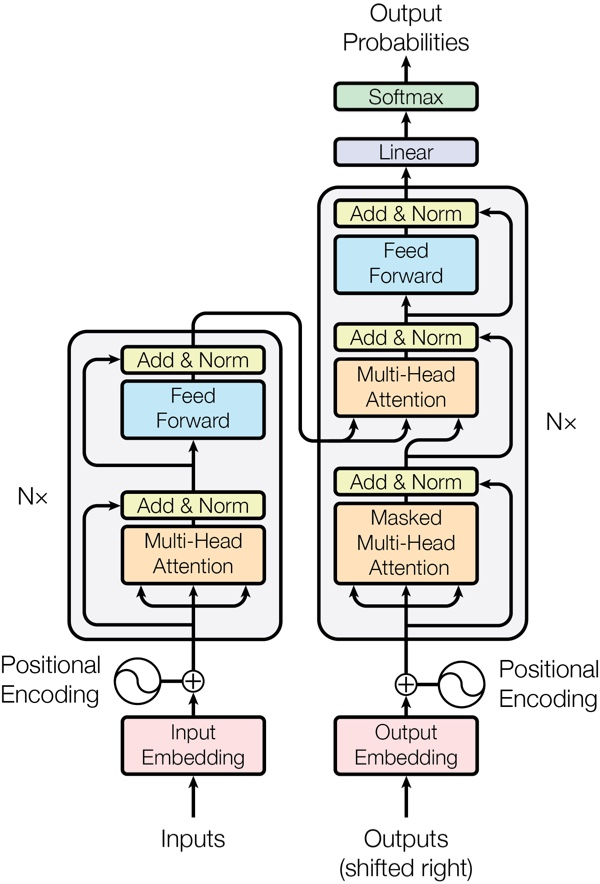

*Hình 1 (nguồn: Vaswani et al., 2017).*

### 1.1. Ý tưởng cốt lõi và lý do Transformer ra đời

#### Bối cảnh trước 2017
Trước Transformer, các bài toán chuỗi (dịch máy, tóm tắt, ...) được giải bởi **RNN / LSTM / GRU** theo mô hình *sequence-to-sequence*: một Encoder RNN nén cả câu nguồn thành một vector, một Decoder RNN sinh câu đích từ vector đó. Có **ba nút thắt** lớn:

1. **Tính tuần tự (sequential bottleneck).** RNN tính trạng thái ẩn $h_t = f(h_{t-1}, x_t)$ → muốn có $h_t$ phải có $h_{t-1}$. Không thể xử lý song song các vị trí trong một câu → huấn luyện chậm, khó tận dụng GPU.
2. **Phụ thuộc xa (long-range dependency).** Thông tin giữa hai từ cách nhau $n$ vị trí phải "đi qua" $n$ bước biến đổi → gradient dễ bị triệt tiêu/bùng nổ, thông tin bị mờ dần. *Độ dài đường đi tối đa là $O(n)$.*
3. **Nút thắt vector cố định.** Toàn bộ câu nguồn bị nén vào 1 vector → câu dài thì mất thông tin. *Attention* (Bahdanau 2014; Luong 2015) giảm bớt vấn đề này nhưng vẫn gắn với RNN.

#### Ý tưởng của Transformer
> **"Attention Is All You Need"**: bỏ hoàn toàn recurrence (và convolution), chỉ dùng **cơ chế attention** để mô hình hoá quan hệ giữa các vị trí.

- Mỗi token **trực tiếp "nhìn" tất cả token khác** trong một phép nhân ma trận → độ dài đường đi giữa hai vị trí bất kỳ là $O(1)$.
- Mọi vị trí được tính **song song** (số phép toán tuần tự là $O(1)$ theo độ dài chuỗi trong một layer).
- Vì attention **không biết thứ tự**, phải bổ sung **Positional Encoding** để đưa thông tin vị trí vào.
- Kết quả trong bài báo: ~28.4 BLEU (En→De) và ~41.8 BLEU (En→Fr) trên WMT 2014, với chi phí huấn luyện thấp hơn đáng kể so với các mô hình trước.

#### Triết lý thiết kế
| Nguyên tắc | Thể hiện trong hình |
|---|---|
| Mọi sub-layer giữ **cùng số chiều $d_{model}$** | để phép cộng residual `x + Sublayer(x)` hợp lệ |
| **Residual + LayerNorm** quanh mỗi sub-layer | các hộp *Add & Norm* |
| **Lặp $N$ lần** cùng một block | ký hiệu *Nx* bên cạnh mỗi khối xám |
| **Hai nửa Encoder / Decoder** | hai khối xám trái / phải |

> **Kiến thức rút ra:**
>
> - RNN/LSTM có 3 điểm yếu: **xử lý tuần tự** (chậm), **khó nhớ phụ thuộc xa** (đường đi $O(n)$), **nén cả câu vào 1 vector**.
> - Transformer **bỏ hẳn recurrence**, chỉ dùng attention → mỗi token nhìn trực tiếp mọi token khác (đường đi $O(1)$).
> - Mọi vị trí tính **song song** → huấn luyện nhanh, tận dụng GPU.
> - Attention không biết thứ tự → cần thêm **Positional Encoding**.

### 1.2. Đọc sơ đồ từ trái sang phải, từ dưới lên trên

#### Nửa trái — **ENCODER** (đọc dữ liệu đầu vào)
| Bước | Hộp trong hình | Việc làm | Tensor (mỗi mẫu) |
|---|---|---|---|
| 1 | **Inputs** | câu nguồn đã được token hoá thành chuỗi ID | $(L_{src},)$ |
| 2 | **Input Embedding** | tra bảng: mỗi ID → vector $d_{model}$ chiều | $(L_{src}, d_{model})$ |
| 3 | **⊕ Positional Encoding** | cộng vector mã hoá vị trí (hình sóng sin) | $(L_{src}, d_{model})$ |
| 4 | **Multi-Head Attention** (có 3 mũi tên vào = Q, K, V) | *self-attention*: mỗi token nhìn mọi token nguồn | $(L_{src}, d_{model})$ |
| 5 | **Add & Norm** | cộng residual (mũi tên vòng qua) rồi LayerNorm | $(L_{src}, d_{model})$ |
| 6 | **Feed Forward** | MLP 2 lớp áp dụng độc lập lên từng vị trí | $(L_{src}, d_{model})$ |
| 7 | **Add & Norm** | residual + LayerNorm lần 2 | $(L_{src}, d_{model})$ |
| 8 | **Nx** | lặp bước 4–7 tổng cộng $N$ lần (bài báo: $N=6$) | $(L_{src}, d_{model})$ |

Đầu ra của Encoder (thường gọi là **memory**) là một chuỗi vector ngữ cảnh *cùng kích thước* với đầu vào. Mũi tên đi từ đỉnh Encoder sang giữa Decoder chính là **memory** này.

#### Nửa phải — **DECODER** (sinh đầu ra từng token một)
| Bước | Hộp trong hình | Việc làm | Tensor |
|---|---|---|---|
| 1 | **Outputs (shifted right)** | các token đích đã sinh, **dịch sang phải 1 vị trí** (thêm `<sos>` ở đầu) | $(L_{tgt},)$ |
| 2 | **Output Embedding ⊕ Positional Encoding** | giống Encoder nhưng cho phía đích | $(L_{tgt}, d_{model})$ |
| 3 | **Masked Multi-Head Attention** | *self-attention có che*: token $t$ chỉ nhìn token $\le t$ | $(L_{tgt}, d_{model})$ |
| 4 | **Add & Norm** | residual + LayerNorm | $(L_{tgt}, d_{model})$ |
| 5 | **Multi-Head Attention** (2 mũi tên từ Encoder + 1 từ Decoder) | *encoder–decoder attention*: **Q từ Decoder; K, V từ Encoder** | $(L_{tgt}, d_{model})$ |
| 6 | **Add & Norm** | residual + LayerNorm | $(L_{tgt}, d_{model})$ |
| 7 | **Feed Forward → Add & Norm** | MLP + residual + LayerNorm | $(L_{tgt}, d_{model})$ |
| 8 | **Nx** | lặp bước 3–7 $N$ lần (**mỗi lần đều dùng cùng một memory của Encoder**) | $(L_{tgt}, d_{model})$ |
| 9 | **Linear** | chiếu $d_{model} \to |V_{tgt}|$ (ra *logits*) | $(L_{tgt}, |V_{tgt}|)$ |
| 10 | **Softmax** | chuẩn hoá thành phân phối xác suất trên từ vựng | $(L_{tgt}, |V_{tgt}|)$ |
| 11 | **Output Probabilities** | $P(y_t \mid y_{<t}, x)$ tại mỗi vị trí | — |

#### Về "Outputs (shifted right)"
Khi huấn luyện (*teacher forcing*), nếu câu đích là `<sos> i love cats <eos>` thì:

| Vị trí | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| **Decoder input** (shifted right) | `<sos>` | `i` | `love` | `cats` |
| **Nhãn cần dự đoán** | `i` | `love` | `cats` | `<eos>` |

Dịch phải 1 vị trí + mask nhân quả đảm bảo: *khi dự đoán token ở vị trí $t$, mô hình chỉ thấy các token đứng trước nó*, không "nhìn trộm" đáp án.

> **Kiến thức rút ra:**
>
> - **Encoder:** Embedding + PE → [Self-Attention → Add&Norm → FFN → Add&Norm] × N → **memory**.
> - **Decoder:** Embedding + PE → [Masked Self-Attn → Cross-Attn (đọc memory) → FFN], mỗi bước có Add&Norm, × N → Linear → Softmax.
> - Kích thước $(L, d_{model})$ **giữ nguyên** suốt các block; chỉ Linear cuối đổi sang $|V|$.
> - **Shifted right:** đầu vào Decoder là `<sos>` + câu đích, nhãn là câu đích + `<eos>` → vị trí $t$ dự đoán token $t+1$.

### 1.3. Kiến trúc Encoder–Decoder

- **Encoder** biến chuỗi nguồn $x=(x_1,\dots,x_n)$ thành chuỗi biểu diễn ngữ cảnh $z=(z_1,\dots,z_n)$. Mỗi $z_i$ đã "hấp thụ" thông tin của **toàn bộ** câu nguồn (hai chiều: nhìn cả trái lẫn phải).
- **Decoder** sinh chuỗi đích $y=(y_1,\dots,y_m)$ theo kiểu **tự hồi quy (auto-regressive)**:

$$P(y \mid x) = \prod_{t=1}^{m} P(y_t \mid y_{<t},\, z)$$

  Tại mỗi bước, Decoder dùng $y_{<t}$ đã sinh (qua Masked Self-Attention) và $z$ của Encoder (qua Encoder–Decoder Attention).
- **Khi huấn luyện:** có sẵn toàn bộ câu đích → đưa vào song song một lượt (nhờ mask).  
  **Khi suy luận:** chưa có câu đích → phải sinh *từng token một*, mỗi lần nối token mới vào đầu vào rồi chạy lại Decoder (Bài 11 sẽ làm đúng như vậy).

> **Kiến thức rút ra:**
>
> - Encoder: đọc câu nguồn **hai chiều** → mỗi $z_i$ chứa ngữ cảnh của cả câu.
> - Decoder: sinh **tự hồi quy** $P(y\mid x)=\prod_t P(y_t\mid y_{<t}, z)$.
> - Huấn luyện: đưa cả câu đích vào **song song** (nhờ mask). Suy luận: sinh **từng token một**.

### 1.4. Bảng phân biệt các thành phần

| Thành phần | Là gì? | Khác gì với thành phần dễ nhầm? |
|---|---|---|
| **Encoder** | Chồng $N$ block [Self-Attn → FFN]. Đọc **toàn bộ** nguồn, hai chiều, **không mask nhân quả**. | Decoder có **thêm** Masked Self-Attn và Cross-Attn. |
| **Decoder** | Chồng $N$ block [Masked Self-Attn → Cross-Attn → FFN]. Sinh tự hồi quy, **có mask nhân quả**. | Encoder chỉ có 2 sub-layer; Decoder có 3. |
| **Input Embedding** | Bảng tra $E_{src}\in\mathbb{R}^{|V_{src}|\times d_{model}}$ cho token **nguồn**. | Chỉ khác Output Embedding ở *chỉ định vocab/tham số*. Bài báo (En–De, BPE chung) **dùng chung trọng số** giữa hai embedding và lớp Linear trước Softmax. |
| **Output Embedding** | Bảng tra cho token **đích** (đã dịch phải) đưa vào Decoder. | Không phải là lớp Linear cuối cùng (Linear cuối đi theo chiều ngược: $d_{model}\to|V|$). |
| **Positional Encoding** | Vector cố định (sin/cos) **cộng vào** embedding để báo vị trí. Không có tham số học. | Embedding mã hoá *từ gì*, PE mã hoá *đứng ở đâu*. |
| **Multi-Head Attention** | $h$ attention song song trên các không gian con khác nhau, rồi nối và chiếu lại. | Một head đơn = Scaled Dot-Product Attention. |
| **Add & Norm** | $\mathrm{LayerNorm}(x+\mathrm{Sublayer}(x))$ — residual + chuẩn hoá. | "Add" = residual; "Norm" = LayerNorm (chuẩn hoá theo chiều đặc trưng, **không** phải BatchNorm). |
| **Feed Forward (FFN)** | $\max(0,xW_1+b_1)W_2+b_2$ áp dụng **độc lập từng vị trí**. | Attention trộn thông tin *giữa* các vị trí; FFN biến đổi *bên trong* từng vị trí. |
| **Linear** | Lớp tuyến tính $d_{model}\to|V_{tgt}|$ tạo **logits**. | Chưa phải xác suất; có thể âm/lớn tuỳ ý. |
| **Softmax** | Biến logits thành xác suất dương, tổng bằng 1 trên từ vựng. | Chỉ là chuẩn hoá; mọi "tri thức" nằm ở các lớp phía trước. |

> **Kiến thức rút ra:**
>
> - Embedding = **từ gì**; Positional Encoding = **đứng ở đâu** (PE không có tham số học).
> - Attention trộn thông tin **giữa** các vị trí; FFN xử lý **trong** từng vị trí.
> - Add & Norm = residual + **LayerNorm** (không phải BatchNorm).
> - Linear cho ra **logits** (chưa phải xác suất); Softmax mới biến thành xác suất.

### 1.5. Luồng dữ liệu và mối liên hệ giữa các khối

```
Câu nguồn ──► Tokenize ──► Input Embedding (×√d_model) ──► + PE ──► [Encoder block] × N ──► memory (B, Ls, d)
                                                                                         │ (K, V)
Câu đích (dịch phải) ─► Output Embedding (×√d_model) ─► + PE ─► [Decoder block] × N ◄───┘
                                                                  │ (Masked Self-Attn → Cross-Attn → FFN)
                                                                  ▼
                                                  Linear (d → |V|) ─► Softmax ─► P(token kế tiếp)
```

Có **3 mối liên kết** cần nhớ:
1. **Residual (mũi tên vòng qua sub-layer):** giữ nguyên thông tin gốc, giúp gradient chảy thẳng về các lớp thấp.
2. **Encoder → Decoder (mũi tên từ đỉnh Encoder sang giữa Decoder):** memory được cấp cho **mọi** Decoder block làm K và V của Cross-Attention.
3. **Decoder → Linear → Softmax:** vector ở vị trí $t$ quyết định phân phối của token $t+1$.

> **Kiến thức rút ra:**
>
> - Nguồn → Encoder × N → **memory** → làm **K, V** cho Cross-Attention ở **mọi** Decoder block.
> - 3 liên kết chính: **residual** (đường tắt cho gradient), **Encoder→Decoder** (memory), **Decoder→Linear→Softmax** (dự đoán).

### 1.6. Ba loại Attention trong Transformer

| | **Self-Attention (Encoder)** | **Masked Self-Attention (Decoder)** | **Encoder–Decoder Attention (Cross)** |
|---|---|---|---|
| Vị trí trong hình | Hộp cam ở Encoder | Hộp cam dưới cùng ở Decoder | Hộp cam giữa ở Decoder |
| **Q** từ đâu | Encoder (lớp trước) | Decoder (lớp trước) | **Decoder** |
| **K, V** từ đâu | Encoder (cùng nguồn với Q) | Decoder (cùng nguồn với Q) | **Đầu ra Encoder (memory)** |
| Mask | Chỉ mask **padding** | Mask **padding + nhân quả** (tam giác dưới) | Mask **padding của nguồn** |
| Ma trận attention | $L_{src}\times L_{src}$ | $L_{tgt}\times L_{tgt}$ (tam giác dưới) | $L_{tgt}\times L_{src}$ (**không vuông**) |
| Vai trò | hiểu ngữ cảnh câu nguồn | mô hình hoá ngôn ngữ phía đích, cấm nhìn tương lai | **căn chỉnh (alignment)** từ đích ↔ từ nguồn, giống attention cổ điển của seq2seq |

> **Kiến thức rút ra:**
>
> - **Encoder self-attn:** Q, K, V cùng từ Encoder; chỉ mask padding; ma trận $L_{src}\times L_{src}$.
> - **Masked self-attn:** Q, K, V cùng từ Decoder; mask padding + **nhân quả**; tam giác dưới.
> - **Cross-attn:** **Q từ Decoder, K/V từ Encoder**; ma trận $L_{tgt}\times L_{src}$ (không vuông) → căn chỉnh nguồn↔đích.

### 1.7. Transformer *nguyên bản 2017* vs. các biến thể *hiện đại*

Notebook này cài đặt **đúng bản gốc**. Khi đọc code hiện đại (LLaMA, GPT, BERT...) bạn sẽ thấy các khác biệt sau — đừng nhầm:

| Hạng mục | Bản gốc 2017 (notebook này) | Biến thể hiện đại thường gặp |
|---|---|---|
| Vị trí của LayerNorm | **Post-LN**: $\mathrm{LN}(x+\mathrm{Sublayer}(x))$ | **Pre-LN**: $x+\mathrm{Sublayer}(\mathrm{LN}(x))$ — ổn định hơn khi rất sâu |
| Chuẩn hoá | LayerNorm | RMSNorm (LLaMA) |
| Mã hoá vị trí | Sinusoidal cố định, **cộng** vào embedding | Học được (BERT/GPT-2), RoPE (LLaMA), ALiBi |
| Hàm kích hoạt FFN | ReLU | GELU (BERT/GPT), SwiGLU (LLaMA, PaLM) |
| Kiến trúc | Encoder–Decoder đầy đủ | Encoder-only (BERT), Decoder-only (GPT, LLaMA), Enc–Dec (T5) |
| Attention | Multi-Head Attention (MHA) | MQA / GQA để tiết kiệm KV-cache, FlashAttention để tăng tốc |
| Lịch học (LR schedule) | Warmup + giảm theo $1/\sqrt{step}$ (Noam) | Warmup + cosine decay |
| Embedding | Dùng chung giữa hai embedding và Linear cuối (với vocab chung) | Thường tie giữa embedding đầu vào và đầu ra LM head |
| $N$, $d_{model}$ | 6, 512 (base); 6, 1024 (big) | Hàng chục–trăm layer, $d_{model}$ hàng nghìn |

> **Kiến thức rút ra:**
>
> - Notebook cài **bản gốc 2017**: Post-LN, LayerNorm, PE sin/cos, ReLU, Encoder–Decoder, Noam LR.
> - Mô hình hiện đại thường dùng: **Pre-LN**, RMSNorm, **RoPE**, GELU/SwiGLU, decoder-only, GQA, FlashAttention.
> - Lõi không đổi: **attention + residual + norm + FFN**.

## Chương 2. Giải thích chi tiết từng thành phần + Thực hành từ đầu

Mỗi bài theo cùng một khuôn: **Khái niệm → Nguyên lý → Công thức (giải thích từng biến) → Ví dụ số → Vị trí trong kiến trúc → Code → Biểu đồ & nhận xét.**

## Bài 1. Tokenization và Embedding

### 1.1. Tokenization

**Khái niệm.** Mạng nơ-ron chỉ xử lý số. *Tokenization* chia văn bản thành các đơn vị nhỏ (**token**) rồi gán mỗi token một **ID nguyên** dựa trên một **từ vựng (vocabulary)**.

**Các mức tokenization thường gặp**

| Mức | Ví dụ với "học máy" | Ưu / nhược |
|---|---|---|
| Ký tự | `h, ọ, c, ␣, m, á, y` | Vocab rất nhỏ, không có OOV, nhưng chuỗi rất dài |
| **Từ (word)** | `học`, `máy` | Dễ hiểu, nhưng vocab lớn và có từ lạ (OOV → `<unk>`) |
| Subword (BPE, WordPiece, SentencePiece) | `học`, `má`, `##y` | **Cân bằng** — bài báo gốc dùng BPE ~37 000 token chung cho En–De |

Notebook dùng **tokenization theo từ** (tách bằng khoảng trắng) để dễ quan sát. Bản chất phần còn lại của Transformer không phụ thuộc cách tokenize.

**Token đặc biệt**

| Token | Vai trò |
|---|---|
| `<pad>` | Đệm cho các câu trong batch cùng độ dài. **Luôn bị mask** trong attention. |
| `<sos>` | Bắt đầu câu đích — token đầu tiên của Decoder. |
| `<eos>` | Kết thúc câu — để Decoder biết khi nào dừng. |
| `<unk>` | Từ chưa có trong vocab. |

> **Kiến thức rút ra:**
>
> - Tokenization: văn bản → **token** → **ID số nguyên** theo vocabulary.
> - 3 mức: ký tự / từ / **subword** (BPE — bài báo dùng ~37k token). Notebook dùng mức **từ** cho dễ quan sát.
> - Token đặc biệt: `<pad>` (đệm, luôn bị mask), `<sos>` (bắt đầu), `<eos>` (kết thúc), `<unk>` (từ lạ).

### 1.2. Word Embedding

**Khái niệm.** Token ID (số nguyên rời rạc) → **vector thực $d_{model}$ chiều** học được. Các vector này là tham số, được cập nhật bằng gradient để từ có nghĩa gần nhau dần có vector gần nhau.

**Công thức.** Với ma trận embedding $E \in \mathbb{R}^{|V|\times d_{model}}$ và token ID $i$:

$$\mathrm{emb}(i) = E_{i,:} = \mathbf{e}_i^{\top} E \qquad\text{(với } \mathbf{e}_i \text{ là one-hot)}$$

Bài báo còn nhân embedding với $\sqrt{d_{model}}$:

$$x = \sqrt{d_{model}}\cdot E_{i,:}$$

| Biến | Ý nghĩa |
|---|---|
| $\lvert V \rvert$ | kích thước từ vựng |
| $d_{model}$ | số chiều vector biểu diễn |
| $E$ | bảng embedding (tham số học được) |
| $\mathbf{e}_i$ | vector one-hot của token $i$ (toàn 0, chỉ vị trí $i$ bằng 1) |
| $\sqrt{d_{model}}$ | hệ số co giãn để độ lớn embedding **tương xứng với Positional Encoding** (PE có biên độ $\le 1$) |

**Vị trí trong kiến trúc:** hai hộp hồng *Input Embedding* và *Output Embedding* ở đáy hình.
**Tensor:** $(B, L) \xrightarrow{\text{Embedding}} (B, L, d_{model})$.

> **Kiến thức rút ra:**
>
> - Embedding = **tra bảng** $E\in\mathbb{R}^{|V|\times d_{model}}$: ID → vector thực, **học được**.
> - Tương đương nhân one-hot với $E$, nhưng nhanh hơn.
> - Nhân thêm $\sqrt{d_{model}}$ để embedding **không bị PE lấn át** (PE có giá trị trong $[-1,1]$).
> - Shape: $(B, L) \to (B, L, d_{model})$.

In [42]:
# ============================================================
# BÀI 1 — Tokenization + Embedding
# ============================================================

# ---- Bước 1: Một kho ngữ liệu nhỏ ----
corpus = [
    "tôi yêu học máy",
    "bạn thích học sâu",
    "chúng ta yêu xử lý ngôn ngữ",
    "mô hình transformer dùng attention nhanh",
    "tôi thích đọc sách",
    "attention giúp mô hình học nhanh",
]

# ---- Bước 2: Hàm tokenize đơn giản (chữ thường + tách theo khoảng trắng) ----
def tokenize(sentence):
    return sentence.lower().strip().split()

# ---- Bước 3: Xây dựng vocabulary (token đặc biệt đứng đầu để ID cố định) ----
SPECIALS = ["<pad>", "<sos>", "<eos>", "<unk>"]

def make_vocab(token_lists):
    """Nhận danh sách các danh sách token, trả về (stoi, itos)."""
    words = sorted({w for toks in token_lists for w in toks})   # sort để kết quả xác định
    itos = SPECIALS + words                                     # ID -> token
    stoi = {w: i for i, w in enumerate(itos)}                   # token -> ID
    return stoi, itos

stoi, itos = make_vocab([tokenize(s) for s in corpus])
PAD, SOS, EOS, UNK = (stoi[t] for t in SPECIALS)
V = len(itos)
print(f"Kích thước từ vựng |V| = {V}")
print("Token đặc biệt:", {t: stoi[t] for t in SPECIALS})
print("Một vài token:", {w: stoi[w] for w in ["tôi", "yêu", "học", "máy", "attention"]})

# ---- Bước 4: Chuyển câu -> danh sách ID ----
def encode(sentence):
    return [stoi.get(w, UNK) for w in tokenize(sentence)]    # từ lạ -> <unk>

def decode(ids):
    return " ".join(itos[i] for i in ids)

# ---- Bước 5: Đệm (padding) để gộp nhiều câu thành một batch hình chữ nhật ----
def pad_sequences(seqs, pad_idx, max_len=None):
    max_len = max_len or max(len(s) for s in seqs)
    return torch.tensor([s + [pad_idx] * (max_len - len(s)) for s in seqs], dtype=torch.long)

demo_sentences = ["tôi yêu học máy", "mô hình transformer dùng attention nhanh"]
src_ids = pad_sequences([encode(s) for s in demo_sentences], PAD)   # (B, L)
B, L = src_ids.shape

print("\n--- Câu -> ID ---")
for s, row in zip(demo_sentences, src_ids):
    print(f"{s!r:50s} -> {row.tolist()}")
print(f"src_ids.shape = {tuple(src_ids.shape)}  # (B={B}, L={L})  — câu ngắn được đệm bằng <pad>=0")
print("Kiểm tra giải mã:", decode(src_ids[0].tolist()))

Kích thước từ vựng |V| = 26
Token đặc biệt: {'<pad>': 0, '<sos>': 1, '<eos>': 2, '<unk>': 3}
Một vài token: {'tôi': 22, 'yêu': 24, 'học': 10, 'máy': 12, 'attention': 4}

--- Câu -> ID ---
'tôi yêu học máy'                                  -> [22, 24, 10, 12, 0, 0]
'mô hình transformer dùng attention nhanh'         -> [13, 9, 21, 7, 4, 16]
src_ids.shape = (2, 6)  # (B=2, L=6)  — câu ngắn được đệm bằng <pad>=0
Kiểm tra giải mã: tôi yêu học máy <pad> <pad>


In [43]:
# ---- Bước 6: Embedding layer ----
# nn.Embedding(V, d_model) chính là ma trận E có kích thước (V, d_model), học được.
emb = nn.Embedding(V, D_MODEL, padding_idx=PAD)     # hàng của <pad> được giữ bằng 0, không cập nhật

x_emb = emb(src_ids)                                # (B, L) -> (B, L, d_model)
print("Kích thước bảng embedding E :", tuple(emb.weight.shape), " = (|V|, d_model)")
print("Kích thước đầu ra emb(src)  :", tuple(x_emb.shape), " = (B, L, d_model)")

print("\nVector embedding của token 'tôi' (d_model=8 chiều):")
print(x_emb[0, 0])
print("Vector embedding của <pad> (toàn 0 vì padding_idx):")
print(x_emb[0, 5])

# ---- Kiểm chứng: Embedding = one-hot @ E ----
one_hot = F.one_hot(src_ids, num_classes=V).float()      # (B, L, V)
x_by_matmul = one_hot @ emb.weight                       # (B, L, V) @ (V, d) -> (B, L, d)
print("\nEmbedding == one-hot @ E ?", torch.allclose(x_emb, x_by_matmul, atol=1e-6))

# ---- Co giãn theo √d_model như bài báo ----
x = x_emb * math.sqrt(D_MODEL)
print(f"Sau khi nhân √d_model = {math.sqrt(D_MODEL):.4f}: x.shape = {tuple(x.shape)}")

Kích thước bảng embedding E : (26, 8)  = (|V|, d_model)
Kích thước đầu ra emb(src)  : (2, 6, 8)  = (B, L, d_model)

Vector embedding của token 'tôi' (d_model=8 chiều):
tensor([ 0.0358,  0.1206, -0.8057, -0.2076, -0.9319, -1.5910, -1.1360, -0.5226], grad_fn=<SelectBackward0>)
Vector embedding của <pad> (toàn 0 vì padding_idx):
tensor([0., 0., 0., 0., 0., 0., 0., 0.], grad_fn=<SelectBackward0>)

Embedding == one-hot @ E ? True
Sau khi nhân √d_model = 2.8284: x.shape = (2, 6, 8)


**Nhận xét Bài 1**
- Embedding là một **phép tra bảng** — tương đương nhân vector one-hot với $E$, nhưng nhanh hơn vì không phải nhân với ma trận thưa khổng lồ.
- Ở thời điểm này $E$ mới khởi tạo ngẫu nhiên nên các vector **chưa mang ý nghĩa**; ý nghĩa xuất hiện sau khi huấn luyện (Bài 11).
- Tensor đi vào Encoder có dạng $(B, L, d_{model}) = (2, 6, 8)$. **Kích thước này giữ nguyên xuyên suốt Encoder** — đó là lý do residual cộng được.

## Bài 2. Positional Encoding

### 2.1. Vì sao cần?
Self-attention là phép toán **bất biến với hoán vị**: nếu xáo trộn thứ tự token đầu vào, đầu ra chỉ bị xáo trộn tương ứng, mô hình **không biết** "tôi yêu mèo" khác "mèo yêu tôi". RNN biết thứ tự nhờ cấu trúc tuần tự; Transformer thì không, nên phải **tiêm thông tin vị trí** vào đầu vào.

> **Kiến thức rút ra:**
>
> - Self-attention **bất biến với hoán vị**: không phân biệt "tôi yêu mèo" với "mèo yêu tôi".
> - → Phải **cộng thông tin vị trí** vào embedding.

### 2.2. Công thức (bài báo gốc)

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)\qquad
PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

| Biến | Ý nghĩa |
|---|---|
| $pos$ | vị trí của token trong câu ($0,1,2,\dots$) |
| $i$ | chỉ số **cặp chiều** ($i=0,\dots,d_{model}/2-1$); chiều chẵn $2i$ dùng sin, chiều lẻ $2i+1$ dùng cos |
| $d_{model}$ | tổng số chiều của vector |
| $10000$ | hằng số chọn để bước sóng trải từ $2\pi$ đến $10000\cdot 2\pi$ |
| $\omega_i=\dfrac{1}{10000^{2i/d_{model}}}$ | **tần số** của cặp chiều thứ $i$: $i$ nhỏ → tần số cao (đổi nhanh theo $pos$), $i$ lớn → tần số thấp (đổi chậm) |

Cộng vào embedding: $\;x_{pos}' = \sqrt{d_{model}}\,E_{w_{pos}} + PE_{pos}$.

> **Kiến thức rút ra:**
>
> - Chiều chẵn dùng **sin**, chiều lẻ dùng **cos**, tần số $\omega_i = 1/10000^{2i/d_{model}}$.
> - Chiều thấp → tần số **cao** (đổi nhanh); chiều cao → tần số **thấp** (đổi chậm).
> - **Cộng** (không nối) vào embedding: $x' = \sqrt{d}\,E_w + PE_{pos}$.

### 2.3. Vì sao dùng sin/cos?
1. **Mỗi vị trí có một "dấu vân tay" duy nhất** — như đồng hồ có kim giờ, phút, giây (các tần số khác nhau) hay như các chữ số của hệ nhị phân nhưng liên tục.
2. **Biểu diễn vị trí tương đối là phép biến đổi tuyến tính.** Với mỗi cặp chiều:

$$\begin{pmatrix}\sin\omega(pos+k)\\ \cos\omega(pos+k)\end{pmatrix}=
\underbrace{\begin{pmatrix}\cos\omega k & \sin\omega k\\ -\sin\omega k & \cos\omega k\end{pmatrix}}_{\text{ma trận quay, chỉ phụ thuộc }k}
\begin{pmatrix}\sin\omega\, pos\\ \cos\omega\, pos\end{pmatrix}$$

   → $PE_{pos+k}$ là hàm tuyến tính của $PE_{pos}$ ⇒ mô hình dễ học "chú ý vào từ cách tôi $k$ vị trí".
3. **Ngoại suy** được tới câu dài hơn lúc huấn luyện (công thức có sẵn cho mọi $pos$).

**Ví dụ số** ($d_{model}=8$, $pos=1$): $i=0\Rightarrow \omega_0=1$, nên $PE_{1,0}=\sin 1\approx0.8415$, $PE_{1,1}=\cos 1\approx0.5403$.

**Vị trí trong kiến trúc:** biểu tượng ⊕ cùng hình sóng sin ở dưới hai khối Encoder và Decoder.
**Tensor:** $(B, L, d_{model}) + (1, L, d_{model}) \to (B, L, d_{model})$ (PE được broadcast theo batch).

> **Kiến thức rút ra:**
>
> - Mỗi vị trí có một **"dấu vân tay" riêng** (giống kim giờ/phút/giây của đồng hồ).
> - $PE_{pos+k}$ = **phép quay** của $PE_{pos}$ → dễ học **vị trí tương đối**.
> - Áp dụng được cho **câu dài hơn** lúc huấn luyện; không cần tham số.
> - Ví dụ: $PE_{1,0}=\sin 1\approx0.84$, $PE_{1,1}=\cos 1\approx0.54$.

In [44]:
# ============================================================
# BÀI 2 — Positional Encoding (NumPy)
# ============================================================
def positional_encoding_np(max_len, d_model):
    """Cài đặt đúng công thức bài báo. Trả về ma trận (max_len, d_model)."""
    assert d_model % 2 == 0, "d_model phải chẵn để ghép cặp sin/cos"
    pe = np.zeros((max_len, d_model))
    pos = np.arange(max_len)[:, None]                 # (max_len, 1)   : pos
    two_i = np.arange(0, d_model, 2)[None, :]         # (1, d_model/2) : 2i
    angle = pos / np.power(10000.0, two_i / d_model)  # (max_len, d_model/2) : pos / 10000^(2i/d)
    pe[:, 0::2] = np.sin(angle)                       # chiều chẵn 2i   -> sin
    pe[:, 1::2] = np.cos(angle)                       # chiều lẻ 2i+1   -> cos
    return pe

# ---- Ví dụ số với d_model = 8 ----
pe8 = positional_encoding_np(6, D_MODEL)
print("PE (6 vị trí × 8 chiều):")
print(pe8)
print("\nKiểm chứng tay: PE[1,0] = sin(1) =", round(math.sin(1), 4), "| PE[1,1] = cos(1) =", round(math.cos(1), 4))
print("PE[0] = (sin0, cos0, ...) = (0, 1, 0, 1, ...):", pe8[0])
assert np.isclose(pe8[1, 0], math.sin(1)) and np.isclose(pe8[1, 1], math.cos(1))

# ---- Kiểm chứng tính chất "vị trí tương đối = phép quay" ----
pos, k = 7, 5
pe_big = positional_encoding_np(64, 16)
for i in range(16 // 2):
    w = 1.0 / (10000 ** (2 * i / 16))
    rot = np.array([[ math.cos(w * k), math.sin(w * k)],
                    [-math.sin(w * k), math.cos(w * k)]])
    lhs = pe_big[pos + k, 2 * i: 2 * i + 2]           # (sin, cos) tại pos+k
    rhs = rot @ pe_big[pos, 2 * i: 2 * i + 2]         # quay (sin, cos) tại pos đi góc w*k
    assert np.allclose(lhs, rhs), f"sai ở cặp chiều {i}"
print(f"\n✔ PE(pos+k) = R(k)·PE(pos) đúng cho mọi cặp chiều (pos={pos}, k={k}).")

PE (6 vị trí × 8 chiều):
[[ 0.      1.      0.      1.      0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.0998  0.995   0.01    1.      0.001   1.    ]
 [ 0.9093 -0.4161  0.1987  0.9801  0.02    0.9998  0.002   1.    ]
 [ 0.1411 -0.99    0.2955  0.9553  0.03    0.9996  0.003   1.    ]
 [-0.7568 -0.6536  0.3894  0.9211  0.04    0.9992  0.004   1.    ]
 [-0.9589  0.2837  0.4794  0.8776  0.05    0.9988  0.005   1.    ]]

Kiểm chứng tay: PE[1,0] = sin(1) = 0.8415 | PE[1,1] = cos(1) = 0.5403
PE[0] = (sin0, cos0, ...) = (0, 1, 0, 1, ...): [0. 1. 0. 1. 0. 1. 0. 1.]

✔ PE(pos+k) = R(k)·PE(pos) đúng cho mọi cặp chiều (pos=7, k=5).


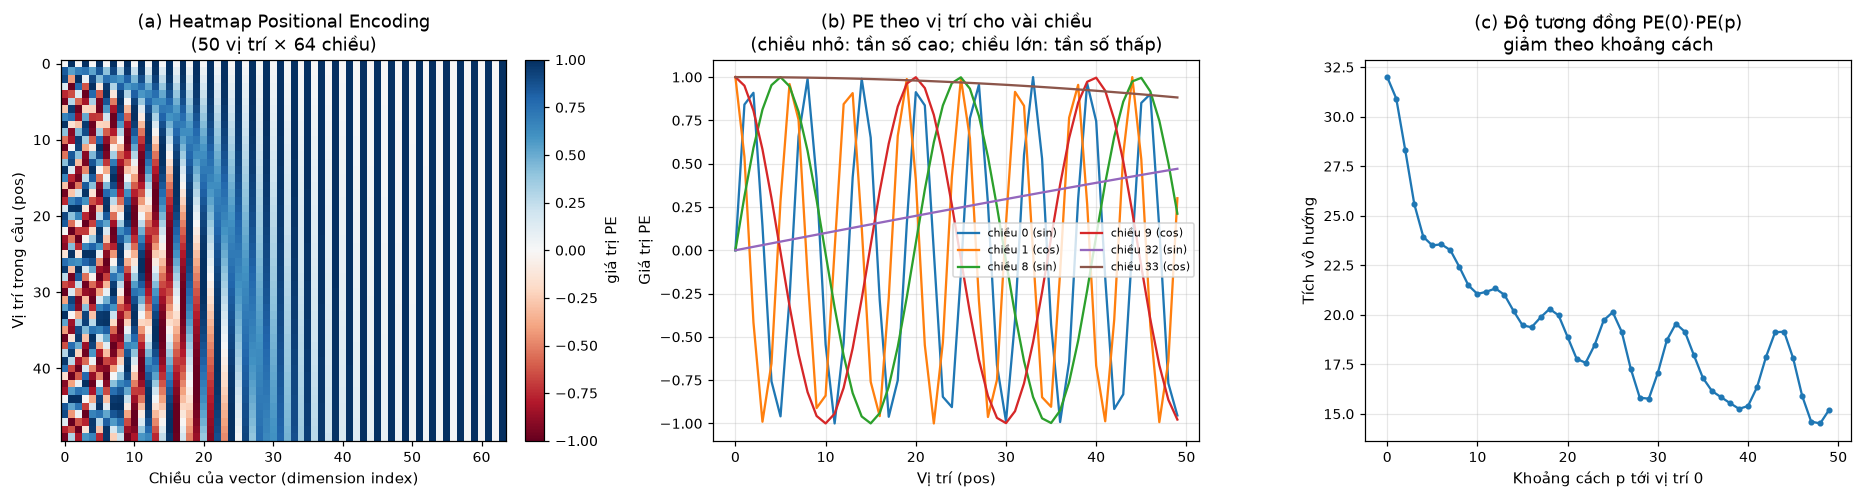

In [13]:
# ============================================================
# BÀI 2 — Trực quan hoá Positional Encoding (Matplotlib)
# ============================================================
MAXLEN_VIS, D_VIS = 50, 64            # dùng d_model=64 chỉ để hình đẹp/đủ nhiều tần số
pe_vis = positional_encoding_np(MAXLEN_VIS, D_VIS)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# (a) Heatmap toàn bộ PE
im = axes[0].imshow(pe_vis, cmap="RdBu", aspect="auto", vmin=-1, vmax=1)
axes[0].set_title("(a) Heatmap Positional Encoding\n(50 vị trí × 64 chiều)")
axes[0].set_xlabel("Chiều của vector (dimension index)")
axes[0].set_ylabel("Vị trí trong câu (pos)")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="giá trị PE")

# (b) PE theo pos cho một vài chiều: tần số giảm dần
for d in [0, 1, 8, 9, 32, 33]:
    axes[1].plot(pe_vis[:, d], label=f"chiều {d} ({'sin' if d % 2 == 0 else 'cos'})")
axes[1].set_title("(b) PE theo vị trí cho vài chiều\n(chiều nhỏ: tần số cao; chiều lớn: tần số thấp)")
axes[1].set_xlabel("Vị trí (pos)")
axes[1].set_ylabel("Giá trị PE")
axes[1].legend(fontsize=7, ncol=2)
axes[1].grid(alpha=0.3)

# (c) Tích vô hướng PE(0)·PE(p): phụ thuộc khoảng cách
dots = pe_vis @ pe_vis[0]
axes[2].plot(dots, marker="o", ms=3)
axes[2].set_title("(c) Độ tương đồng PE(0)·PE(p)\ngiảm theo khoảng cách")
axes[2].set_xlabel("Khoảng cách p tới vị trí 0")
axes[2].set_ylabel("Tích vô hướng")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Giải thích biểu đồ Bài 2**
- **(a) Heatmap:** mỗi **hàng** là vector vị trí của một token. Bên trái (chiều thấp) các sọc đổi màu rất nhanh theo hàng; bên phải (chiều cao) sọc gần như không đổi. Chính tổ hợp nhiều tần số tạo ra "mã vị trí" duy nhất cho từng hàng.
- **(b) Dạng sóng:** chiều 0 (sin, $\omega_0=1$) dao động nhanh nhất; chiều 32–33 gần như đứng yên trong 50 vị trí đầu. Các cặp sin/cos cùng tần số lệch pha $90^\circ$.
- **(c) Tương đồng:** $PE_0\cdot PE_p$ cao khi $p$ nhỏ và dao động/giảm khi $p$ xa → mã vị trí **bảo toàn khái niệm khoảng cách**. Do $\sin a\sin b+\cos a\cos b=\cos(a-b)$ nên $PE_p\cdot PE_q=\sum_i\cos(\omega_i(p-q))$ **chỉ phụ thuộc $|p-q|$**.

In [46]:
# ============================================================
# BÀI 2 — Phiên bản PyTorch (module dùng lại ở các bài sau) + ảnh hưởng của vị trí
# ============================================================
class PositionalEncoding(nn.Module):
    """Cộng mã hoá vị trí sin/cos vào embedding. Không có tham số học (dùng register_buffer)."""
    def __init__(self, d_model, dropout=0.1, max_len=512):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)                                   # (max_len, d_model)
        position = torch.arange(max_len).unsqueeze(1).float()                # (max_len, 1)
        # 1/10000^(2i/d) = exp(-(2i/d) * ln 10000)  -> tính ổn định số học
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))                          # (1, max_len, d_model)

    def forward(self, x):                                                    # x: (B, L, d_model)
        x = x + self.pe[:, : x.size(1)]                                      # broadcast theo batch
        return self.dropout(x)

pos_enc = PositionalEncoding(D_MODEL, dropout=0.0, max_len=64)               # dropout=0 để quan sát rõ

# Kiểm chứng PyTorch == NumPy
print("PyTorch PE == NumPy PE ?", np.allclose(to_np(pos_enc.pe[0, :6]), pe8, atol=1e-6))

# ---- Ảnh hưởng của vị trí: cùng một từ lặp lại 4 lần ----
same_word = torch.tensor([[stoi["tôi"]] * 4])                                # (1, 4): "tôi tôi tôi tôi"
e = emb(same_word) * math.sqrt(D_MODEL)                                       # embedding giống hệt nhau ở mọi vị trí
e_pos = pos_enc(e)                                                            # sau khi cộng PE

cos = nn.CosineSimilarity(dim=-1)
print("\nTrước PE — cos(vị trí0, vị trí1):", round(cos(e[0, 0], e[0, 1]).item(), 4), "(giống hệt nhau)")
print("Sau  PE — cos(vị trí0, vị trí1):", round(cos(e_pos[0, 0], e_pos[0, 1]).item(), 4), "(đã khác nhau)")
print("Sau  PE — cos(vị trí0, vị trí3):", round(cos(e_pos[0, 0], e_pos[0, 3]).item(), 4))

# ---- Đầu vào chuẩn bị cho Encoder ở các bài sau: x = PE( √d · Emb(src) ) ----
x = pos_enc(emb(src_ids) * math.sqrt(D_MODEL))                                # (B, L, d_model)
print("\nTensor đầu vào Encoder x.shape =", tuple(x.shape), "= (B, L, d_model)")

PyTorch PE == NumPy PE ? True

Trước PE — cos(vị trí0, vị trí1): 1.0 (giống hệt nhau)
Sau  PE — cos(vị trí0, vị trí1): 0.9873 (đã khác nhau)
Sau  PE — cos(vị trí0, vị trí3): 0.9434

Tensor đầu vào Encoder x.shape = (2, 6, 8) = (B, L, d_model)


## Bài 3. Scaled Dot-Product Attention (và Query, Key, Value)

### 3.1. Trực giác: Q, K, V
Hình dung một **thư viện tìm kiếm**:
- **Query (Q)** — "câu hỏi" của token hiện tại: *tôi đang cần thông tin gì?*
- **Key (K)** — "nhãn" mà mỗi token đưa ra: *tôi có thể cung cấp thông tin loại gì?*
- **Value (V)** — "nội dung" thực sự mỗi token sẽ đóng góp nếu được chú ý.

Mức độ liên quan giữa query $i$ và key $j$ là tích vô hướng $q_i\cdot k_j$ → qua softmax thành **trọng số** → trung bình có trọng số các **value**.

**Cả ba đều sinh ra từ cùng ma trận đầu vào $X$ bằng ba phép chiếu tuyến tính học được:**

$$Q = XW^Q,\qquad K = XW^K,\qquad V = XW^V$$

| Biến | Kích thước | Ý nghĩa |
|---|---|---|
| $X$ | $(L, d_{model})$ | biểu diễn các token (embedding + PE hoặc đầu ra layer trước) |
| $W^Q, W^K$ | $(d_{model}, d_k)$ | ma trận chiếu học được (cho Q, K) |
| $W^V$ | $(d_{model}, d_v)$ | ma trận chiếu học được (cho V) |
| $Q$ | $(L_q, d_k)$ | mỗi hàng là query của 1 token |
| $K$ | $(L_k, d_k)$ | mỗi hàng là key của 1 token |
| $V$ | $(L_k, d_v)$ | mỗi hàng là value của 1 token |

> Trong **self-attention** $Q,K,V$ cùng từ $X$ ($L_q=L_k$). Trong **cross-attention** $Q$ từ Decoder còn $K,V$ từ Encoder ($L_q\neq L_k$).

> **Kiến thức rút ra:**
>
> - **Q** = "tôi cần gì?", **K** = "tôi có gì?", **V** = "nội dung tôi đóng góp".
> - Cả ba tạo từ cùng $X$ qua 3 ma trận học được: $Q=XW^Q,\;K=XW^K,\;V=XW^V$.
> - Self-attention: Q, K, V cùng nguồn. Cross-attention: Q từ Decoder, K/V từ Encoder.

### 3.2. Công thức

$$\boxed{\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V}$$

Tách thành **4 bước**:

| Bước | Phép tính | Kích thước | Ý nghĩa |
|---|---|---|---|
| ① Scores | $S = QK^{\top}$ | $(L_q, L_k)$ | $S_{ij}=q_i\cdot k_j$: token $i$ "hợp" token $j$ đến đâu |
| ② Scaling | $S' = S/\sqrt{d_k}$ | $(L_q, L_k)$ | giữ phương sai điểm số ≈ 1 |
| ③ Softmax | $A=\mathrm{softmax}(S')$ **theo từng hàng** | $(L_q, L_k)$ | mỗi hàng thành phân phối xác suất (dương, tổng = 1) |
| ④ Trộn Value | $O = AV$ | $(L_q, d_v)$ | $o_i=\sum_j A_{ij}v_j$ — trung bình có trọng số |

#### Vì sao chia cho $\sqrt{d_k}$?
Giả sử các thành phần của $q,k$ độc lập, kỳ vọng 0, phương sai 1. Khi đó $q\cdot k=\sum_{m=1}^{d_k}q_mk_m$ có **kỳ vọng 0 và phương sai $d_k$**. Với $d_k$ lớn (64, 512...) các điểm số rất lớn → softmax gần như **one-hot** (bão hoà) → gradient gần 0 → khó học. Chia cho $\sqrt{d_k}$ đưa phương sai về 1. Code bên dưới sẽ kiểm chứng bằng số liệu.

> **Kiến thức rút ra:**
>
> - $\mathrm{Attention}=\mathrm{softmax}(QK^\top/\sqrt{d_k})\,V$ gồm 4 bước: **điểm số → chia $\sqrt{d_k}$ → softmax theo hàng → trộn V**.
> - Mỗi hàng của ma trận attention là **phân phối xác suất** (tổng = 1).
> - **Chia $\sqrt{d_k}$:** phương sai của $q\cdot k$ bằng $d_k$ → nếu không chia, softmax **bão hoà** (gần one-hot) → gradient ≈ 0.

### 3.3. Ví dụ số (tính tay được)
3 token `tôi, yêu, mèo`, $d_k=4$, $d_v=3$:

$$Q=\begin{pmatrix}1&0&1&0\\0&1&0&1\\1&1&0&0\end{pmatrix},\quad
K=\begin{pmatrix}1&0&1&0\\0&1&0&1\\1&1&1&1\end{pmatrix},\quad
V=\begin{pmatrix}1&2&3\\4&5&6\\7&8&9\end{pmatrix}$$

**Hàng 0 (token "tôi"):**
- ① $q_0\cdot k_0=2,\; q_0\cdot k_1=0,\; q_0\cdot k_2=2 \Rightarrow S_{0,:}=[2,0,2]$
- ② $\sqrt{d_k}=2 \Rightarrow S'_{0,:}=[1,0,1]$
- ③ $\mathrm{softmax}=\left[\frac{e}{2e+1},\frac{1}{2e+1},\frac{e}{2e+1}\right]\approx[0.4223,\;0.1554,\;0.4223]$
- ④ $o_0\approx 0.4223\,v_0+0.1554\,v_1+0.4223\,v_2=[4,\;5,\;6]$ (chính xác, vì $v_1=[4,5,6]$ đúng bằng trung điểm của $v_0$ và $v_2$ nên trộn đối xứng cho ra đúng $v_1$)

Code bên dưới sẽ **tự kiểm tra** các con số này.

**Vị trí trong kiến trúc:** bên trong mọi hộp cam *(Masked) Multi-Head Attention*.

> **Kiến thức rút ra:**
>
> - Hàng "tôi": điểm số $[2,0,2]$ → chia 2 → $[1,0,1]$ → softmax $\approx[0.42, 0.16, 0.42]$.
> - Output $=[4,5,6]$: trung bình có trọng số của các value.
> - Attention nằm trong **mọi** hộp Multi-Head Attention.

In [47]:
# ============================================================
# BÀI 3 — Scaled Dot-Product Attention
# ============================================================
def scaled_dot_product_attention(q, k, v, mask=None, dropout=None):
    """
    q: (..., Lq, d_k)   k: (..., Lk, d_k)   v: (..., Lk, d_v)
    mask: broadcast được tới (..., Lq, Lk); True/1 = ĐƯỢC nhìn, False/0 = BỊ che.
    Trả về: (output (..., Lq, d_v), weights (..., Lq, Lk))
    """
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1)                  # ① (..., Lq, Lk) : Q·Kᵀ
    scores = scores / math.sqrt(d_k)                  # ② chia √d_k
    if mask is not None:
        scores = scores.masked_fill(~mask.bool(), -1e9)   # vị trí bị che -> -∞ (xấp xỉ) => softmax = 0
    weights = F.softmax(scores, dim=-1)               # ③ softmax theo chiều KEY (mỗi hàng tổng = 1)
    if dropout is not None:
        weights = dropout(weights)
    output = weights @ v                              # ④ (..., Lq, d_v)
    return output, weights

# ---- Ví dụ số tính tay (3 token, d_k=4, d_v=3) ----
tokens3 = ["tôi", "yêu", "mèo"]
Q = torch.tensor([[1., 0., 1., 0.], [0., 1., 0., 1.], [1., 1., 0., 0.]])
K = torch.tensor([[1., 0., 1., 0.], [0., 1., 0., 1.], [1., 1., 1., 1.]])
Vv = torch.tensor([[1., 2., 3.], [4., 5., 6.], [7., 8., 9.]])
print("Q", tuple(Q.shape), "| K", tuple(K.shape), "| V", tuple(Vv.shape))

scores = Q @ K.T                                      # ① điểm thô
scaled = scores / math.sqrt(Q.size(-1))               # ② scaling
weights = F.softmax(scaled, dim=-1)                   # ③ softmax
output = weights @ Vv                                 # ④ trộn value

print("\n① Scores = Q·Kᵀ  (3×3):\n", scores)
print("\n② Scaled = Scores/√d_k (√4 = 2):\n", scaled)
print("\n③ Attention weights = softmax theo hàng:\n", weights)
print("   Tổng mỗi hàng:", weights.sum(-1))
print("\n④ Output = weights·V  (3×3):\n", output)

# ---- Kiểm chứng với số tính tay trong phần lý thuyết ----
e = math.e
hand_w0 = torch.tensor([e / (2 * e + 1), 1 / (2 * e + 1), e / (2 * e + 1)])
assert torch.allclose(weights[0], hand_w0, atol=1e-5)
assert torch.allclose(output[0], torch.tensor([4.0, 5.0, 6.0]), atol=1e-3)
print("\n✔ Hàng 0 khớp với kết quả tính tay: weights≈[0.4223, 0.1554, 0.4223], output=[4.0, 5.0, 6.0]")

# ---- Kiểm chứng với hàm của hệ thống và với hàm tự viết ----
out_fn, w_fn = scaled_dot_product_attention(Q, K, Vv)
out_ref = F.scaled_dot_product_attention(Q.unsqueeze(0), K.unsqueeze(0), Vv.unsqueeze(0))[0]
print("Hàm tự viết == F.scaled_dot_product_attention ?", torch.allclose(out_fn, out_ref, atol=1e-6))

Q (3, 4) | K (3, 4) | V (3, 3)

① Scores = Q·Kᵀ  (3×3):
 tensor([[2., 0., 2.],
        [0., 2., 2.],
        [1., 1., 2.]])

② Scaled = Scores/√d_k (√4 = 2):
 tensor([[1.0000, 0.0000, 1.0000],
        [0.0000, 1.0000, 1.0000],
        [0.5000, 0.5000, 1.0000]])

③ Attention weights = softmax theo hàng:
 tensor([[0.4223, 0.1554, 0.4223],
        [0.1554, 0.4223, 0.4223],
        [0.2741, 0.2741, 0.4519]])
   Tổng mỗi hàng: tensor([1., 1., 1.])

④ Output = weights·V  (3×3):
 tensor([[4.0000, 5.0000, 6.0000],
        [4.8009, 5.8009, 6.8009],
        [4.5334, 5.5334, 6.5334]])

✔ Hàng 0 khớp với kết quả tính tay: weights≈[0.4223, 0.1554, 0.4223], output=[4.0, 5.0, 6.0]
Hàm tự viết == F.scaled_dot_product_attention ? True


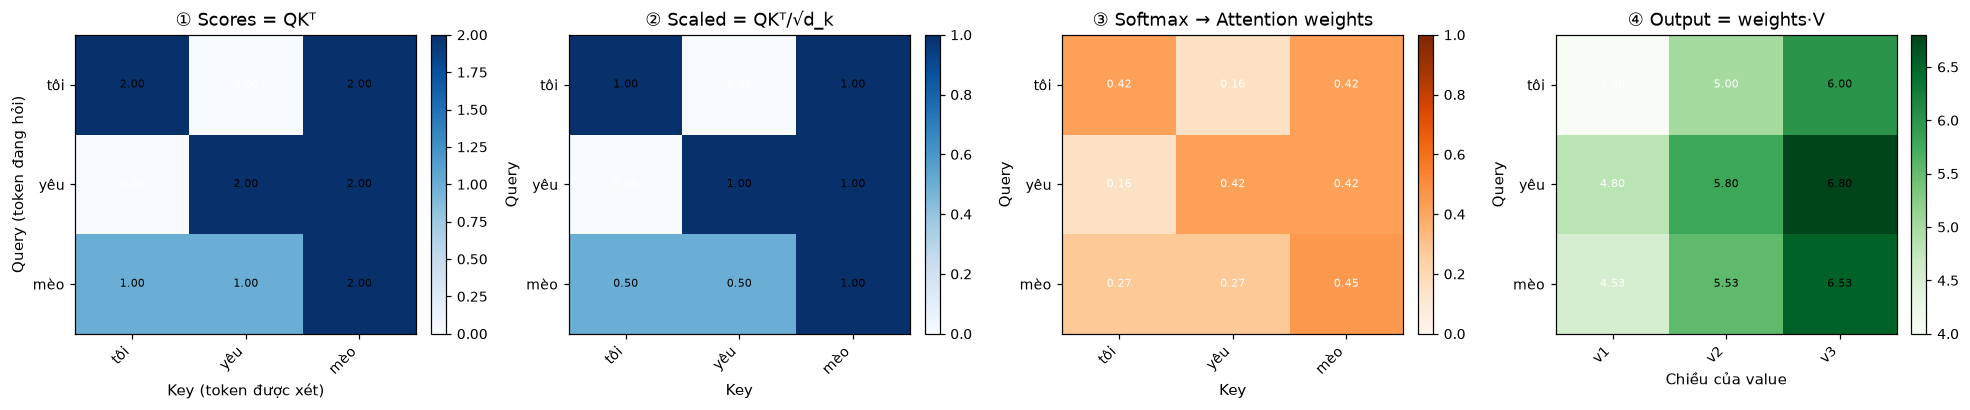

In [48]:
# ---- Trực quan hoá 4 bước ----
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
plot_heatmap(axes[0], scores, tokens3, tokens3, "① Scores = QKᵀ", "Key (token được xét)", "Query (token đang hỏi)", cmap="Blues")
plot_heatmap(axes[1], scaled, tokens3, tokens3, "② Scaled = QKᵀ/√d_k", "Key", "Query", cmap="Blues")
plot_heatmap(axes[2], weights, tokens3, tokens3, "③ Softmax → Attention weights", "Key", "Query", cmap="Oranges", vmin=0, vmax=1)
plot_heatmap(axes[3], output, ["v1", "v2", "v3"], tokens3, "④ Output = weights·V", "Chiều của value", "Query", cmap="Greens")
plt.tight_layout()
plt.show()

**Giải thích biểu đồ Bài 3.** Heatmap ③ là **ma trận attention**: hàng $i$ cho biết token $i$ phân bổ "sự chú ý" lên các token $j$. Hàng "tôi" chú ý bằng nhau vào "tôi" và "mèo" (0.42) vì hai key đó cho điểm bằng nhau, và ít hơn vào "yêu" (0.16). Heatmap ④ là kết quả: mỗi query nhận **một vector mới** là trung bình có trọng số của các value.

In [49]:
# ============================================================
# BÀI 3 — Q, K, V được sinh ra từ X bằng 3 phép chiếu tuyến tính
# ============================================================
torch.manual_seed(0)
X = x[1]                                              # (L, d_model) = (6, 8): câu dài của batch demo
W_Q = torch.randn(D_MODEL, D_K) / math.sqrt(D_MODEL)  # (8, 4)
W_K = torch.randn(D_MODEL, D_K) / math.sqrt(D_MODEL)  # (8, 4)
W_V = torch.randn(D_MODEL, D_K) / math.sqrt(D_MODEL)  # (8, 4)  (d_v = d_k)

Qx, Kx, Vx = X @ W_Q, X @ W_K, X @ W_V
print(f"X {tuple(X.shape)} @ W {tuple(W_Q.shape)}  ->  Q,K,V đều có shape {tuple(Qx.shape)}")

out_x, w_x = scaled_dot_product_attention(Qx, Kx, Vx)
print("Attention weights shape:", tuple(w_x.shape), "= (Lq, Lk) ; Output shape:", tuple(out_x.shape), "= (Lq, d_v)")

# ---- Vì sao phải chia √d_k ? Kiểm chứng bằng thực nghiệm ----
torch.manual_seed(1)
print("\nPhương sai của q·k khi q,k ~ N(0,1):")
for dk in [4, 64, 512]:
    q_ = torch.randn(20000, dk); k_ = torch.randn(20000, dk)
    dots = (q_ * k_).sum(-1)
    print(f"  d_k={dk:4d} | Var(q·k) = {dots.var().item():8.2f} (≈ d_k) | Var(q·k/√d_k) = {(dots / math.sqrt(dk)).var().item():5.2f} (≈ 1)")

print("\nBão hoà softmax khi d_k=512 (10 key ngẫu nhiên):")
dk = 512
q_ = torch.randn(dk); K_ = torch.randn(10, dk)
raw = K_ @ q_
p_raw = F.softmax(raw, dim=-1)
p_scaled = F.softmax(raw / math.sqrt(dk), dim=-1)
print("  Không chia √d_k : max prob =", round(p_raw.max().item(), 4), "→ gần one-hot, gradient triệt tiêu")
print("  Có chia √d_k    : max prob =", round(p_scaled.max().item(), 4), "→ phân bố mềm, gradient còn tốt")

X (6, 8) @ W (8, 4)  ->  Q,K,V đều có shape (6, 4)
Attention weights shape: (6, 6) = (Lq, Lk) ; Output shape: (6, 4) = (Lq, d_v)

Phương sai của q·k khi q,k ~ N(0,1):
  d_k=   4 | Var(q·k) =     4.03 (≈ d_k) | Var(q·k/√d_k) =  1.01 (≈ 1)
  d_k=  64 | Var(q·k) =    64.02 (≈ d_k) | Var(q·k/√d_k) =  1.00 (≈ 1)
  d_k= 512 | Var(q·k) =   508.17 (≈ d_k) | Var(q·k/√d_k) =  0.99 (≈ 1)

Bão hoà softmax khi d_k=512 (10 key ngẫu nhiên):
  Không chia √d_k : max prob = 0.9997 → gần one-hot, gradient triệt tiêu
  Có chia √d_k    : max prob = 0.3362 → phân bố mềm, gradient còn tốt


**Nhận xét Bài 3.** Phương sai của $q\cdot k$ tăng tuyến tính theo $d_k$ đúng như phân tích; sau khi chia $\sqrt{d_k}$ nó về ≈ 1. Không chia thì softmax với $d_k=512$ gần như chọn đúng một key (xác suất ≈ 1) — mô hình mất khả năng "pha trộn" thông tin và gradient gần như bằng 0.

## Bài 4. Multi-Head Attention

### 4.1. Khái niệm và động cơ
Một attention duy nhất chỉ tạo **một** phân phối chú ý cho mỗi token — nó phải "gánh" cùng lúc mọi loại quan hệ (cú pháp, ngữ nghĩa, vị trí gần...). **Multi-Head Attention (MHA)** chạy $h$ attention **song song** trên $h$ không gian con khác nhau, để mỗi head có thể chuyên về một kiểu quan hệ, rồi ghép kết quả lại.

> **Kiến thức rút ra:**
>
> - Một head chỉ cho **một** kiểu chú ý → khó học nhiều loại quan hệ cùng lúc.
> - MHA chạy **$h$ head song song**, mỗi head trên một không gian con riêng → mỗi head chuyên một kiểu quan hệ.

### 4.2. Công thức

$$\mathrm{MultiHead}(Q,K,V)=\mathrm{Concat}(\mathrm{head}_1,\dots,\mathrm{head}_h)\,W^O$$
$$\mathrm{head}_i=\mathrm{Attention}(QW_i^Q,\;KW_i^K,\;VW_i^V)$$

| Biến | Kích thước | Ý nghĩa |
|---|---|---|
| $h$ | — | số head (bài báo: 8; demo: 2) |
| $W_i^Q, W_i^K$ | $(d_{model}, d_k)$ | phép chiếu của head $i$, với $d_k=d_{model}/h$ |
| $W_i^V$ | $(d_{model}, d_v)$ | phép chiếu value của head $i$, $d_v=d_{model}/h$ |
| $\mathrm{head}_i$ | $(L_q, d_v)$ | đầu ra của head $i$ |
| $\mathrm{Concat}$ | $(L_q, h\cdot d_v)=(L_q,d_{model})$ | nối các head theo chiều đặc trưng |
| $W^O$ | $(d_{model}, d_{model})$ | **Output Projection**: trộn thông tin giữa các head |

#### Cách cài đặt hiệu quả (dùng trong code)
Thay vì $h$ cặp ma trận nhỏ, dùng **một** ma trận lớn $W^Q\in\mathbb{R}^{d_{model}\times d_{model}}$ rồi **cắt (reshape)** kết quả thành $h$ phần:

$$(B,L,d_{model})\xrightarrow{\text{Linear}}(B,L,d_{model})\xrightarrow{\text{view}}(B,L,h,d_k)\xrightarrow{\text{transpose}}(B,h,L,d_k)$$

Sau đó các phép `@` hoạt động trên hai chiều cuối nên **mọi head chạy song song**. Kết quả: $(B,h,L,d_k)\to(B,L,h,d_k)\to(B,L,d_{model})\xrightarrow{W^O}(B,L,d_{model})$.

Vì $d_k=d_{model}/h$ nên **tổng chi phí tính toán xấp xỉ một attention đầy đủ chiều**.

**Vị trí trong kiến trúc:** cả ba hộp cam trong hình (Self-Attention, Masked Self-Attention, Encoder–Decoder Attention) đều là MHA; chỉ khác *Q, K, V lấy từ đâu* và *mask*.

> **Kiến thức rút ra:**
>
> - $\mathrm{MultiHead}=\mathrm{Concat}(\mathrm{head}_1..\mathrm{head}_h)\,W^O$, với $d_k=d_{model}/h$.
> - Cài đặt: **1 Linear lớn** → reshape $(B,L,h,d_k)$ → transpose $(B,h,L,d_k)$ → mọi head tính song song.
> - $W^O$ trộn thông tin giữa các head. Tổng chi phí ≈ **một** attention đầy đủ chiều.
> - Cả 3 hộp attention trong hình đều là MHA; chỉ khác **nguồn Q/K/V** và **mask**.

In [50]:
# ============================================================
# BÀI 4 — Multi-Head Attention (viết từ đầu)
# ============================================================
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0, "d_model phải chia hết cho số head"
        self.d_model = d_model
        self.h = num_heads
        self.d_k = d_model // num_heads
        # 4 phép chiếu tuyến tính: W^Q, W^K, W^V và W^O (mỗi cái (d_model, d_model))
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.attn_weights = None                     # lưu lại để vẽ heatmap

    def split_heads(self, t):
        """(B, L, d_model) -> (B, h, L, d_k)"""
        B, L, _ = t.shape
        return t.view(B, L, self.h, self.d_k).transpose(1, 2)

    def forward(self, query, key, value, mask=None):
        # query: (B, Lq, d_model); key, value: (B, Lk, d_model)
        B, Lq, _ = query.shape
        # (1) Chiếu tuyến tính rồi (2) chia head
        q = self.split_heads(self.W_q(query))        # (B, h, Lq, d_k)
        k = self.split_heads(self.W_k(key))          # (B, h, Lk, d_k)
        v = self.split_heads(self.W_v(value))        # (B, h, Lk, d_k)
        # (3) Attention độc lập cho từng head (mask (B,1,Lq,Lk) tự broadcast qua chiều head)
        out, weights = scaled_dot_product_attention(q, k, v, mask, self.dropout)   # out (B,h,Lq,d_k)
        self.attn_weights = weights.detach()         # (B, h, Lq, Lk)
        # (4) Nối các head: (B,h,Lq,d_k) -> (B,Lq,h,d_k) -> (B,Lq,d_model)
        out = out.transpose(1, 2).contiguous().view(B, Lq, self.d_model)
        # (5) Output projection W^O
        return self.W_o(out)                         # (B, Lq, d_model)

def make_pad_mask(seq, pad_idx):
    """seq: (B, L) ID token. Trả về (B, 1, 1, L): True = token thật, False = <pad> (bị che)."""
    return (seq != pad_idx).unsqueeze(1).unsqueeze(2)

torch.manual_seed(0)
mha = MultiHeadAttention(D_MODEL, N_HEADS)
mha.eval()
src_mask = make_pad_mask(src_ids, PAD)               # (B, 1, 1, L)
print("x         :", tuple(x.shape), "  (B, L, d_model)")
print("src_mask  :", tuple(src_mask.shape), " (B, 1, 1, L)  ← broadcast qua head và query")
print("Mask câu 0:", src_mask[0, 0, 0].tolist(), " (2 vị trí cuối là <pad>)")

x         : (2, 6, 8)   (B, L, d_model)
src_mask  : (2, 1, 1, 6)  (B, 1, 1, L)  ← broadcast qua head và query
Mask câu 0: [True, True, True, True, False, False]  (2 vị trí cuối là <pad>)


In [51]:
# ---- Đi từng bước bên trong MHA để quan sát kích thước tensor ----
with torch.no_grad():
    q_lin = mha.W_q(x)                    # (B, L, d_model)   chiếu tuyến tính
    q_h   = mha.split_heads(q_lin)        # (B, h, L, d_k)    chia head
    k_h   = mha.split_heads(mha.W_k(x))
    v_h   = mha.split_heads(mha.W_v(x))
    scores_h = q_h @ k_h.transpose(-2, -1) / math.sqrt(D_K)       # (B, h, L, L)
    head_out, w_h = scaled_dot_product_attention(q_h, k_h, v_h, src_mask)
    concat = head_out.transpose(1, 2).contiguous().view(B, L, D_MODEL)   # (B, L, d_model)
    final  = mha.W_o(concat)

print(f"x                      : {tuple(x.shape)}")
print(f"Q sau Linear           : {tuple(q_lin.shape)}")
print(f"Q sau chia head        : {tuple(q_h.shape)}   = (B, h={N_HEADS}, L, d_k={D_K})")
print(f"Scores mỗi head        : {tuple(scores_h.shape)}   = (B, h, L, L)")
print(f"Output mỗi head        : {tuple(head_out.shape)}   = (B, h, L, d_k)")
print(f"Sau Concatenate        : {tuple(concat.shape)}   = (B, L, h·d_k = d_model)")
print(f"Sau Output Projection  : {tuple(final.shape)}   = (B, L, d_model)")
print("Khớp với forward() của module ?", torch.allclose(final, mha(x, x, x, src_mask), atol=1e-6))

# ---- Kiểm chứng với nn.MultiheadAttention của PyTorch (chỉ để đối chiếu) ----
ref = nn.MultiheadAttention(D_MODEL, N_HEADS, batch_first=True)
with torch.no_grad():
    ref.in_proj_weight.copy_(torch.cat([mha.W_q.weight, mha.W_k.weight, mha.W_v.weight], dim=0))
    ref.in_proj_bias.copy_(torch.cat([mha.W_q.bias, mha.W_k.bias, mha.W_v.bias], dim=0))
    ref.out_proj.weight.copy_(mha.W_o.weight)
    ref.out_proj.bias.copy_(mha.W_o.bias)
ref.eval()
with torch.no_grad():
    # key_padding_mask của PyTorch: True = BỊ che  (ngược quy ước của ta)
    ref_out, ref_w = ref(x, x, x, key_padding_mask=(src_ids == PAD), need_weights=True, average_attn_weights=False)
    mine = mha(x, x, x, src_mask)
valid = (src_ids != PAD).unsqueeze(-1)               # chỉ so sánh ở vị trí token thật (hàng <pad> không quan trọng)
print("MHA tự viết == nn.MultiheadAttention (output, token thật) ?",
      torch.allclose((mine * valid), (ref_out * valid), atol=1e-5))
print("Attention weights khớp ?", torch.allclose(mha.attn_weights, ref_w, atol=1e-5))

x                      : (2, 6, 8)
Q sau Linear           : (2, 6, 8)
Q sau chia head        : (2, 2, 6, 4)   = (B, h=2, L, d_k=4)
Scores mỗi head        : (2, 2, 6, 6)   = (B, h, L, L)
Output mỗi head        : (2, 2, 6, 4)   = (B, h, L, d_k)
Sau Concatenate        : (2, 6, 8)   = (B, L, h·d_k = d_model)
Sau Output Projection  : (2, 6, 8)   = (B, L, d_model)
Khớp với forward() của module ? True
MHA tự viết == nn.MultiheadAttention (output, token thật) ? True
Attention weights khớp ? True


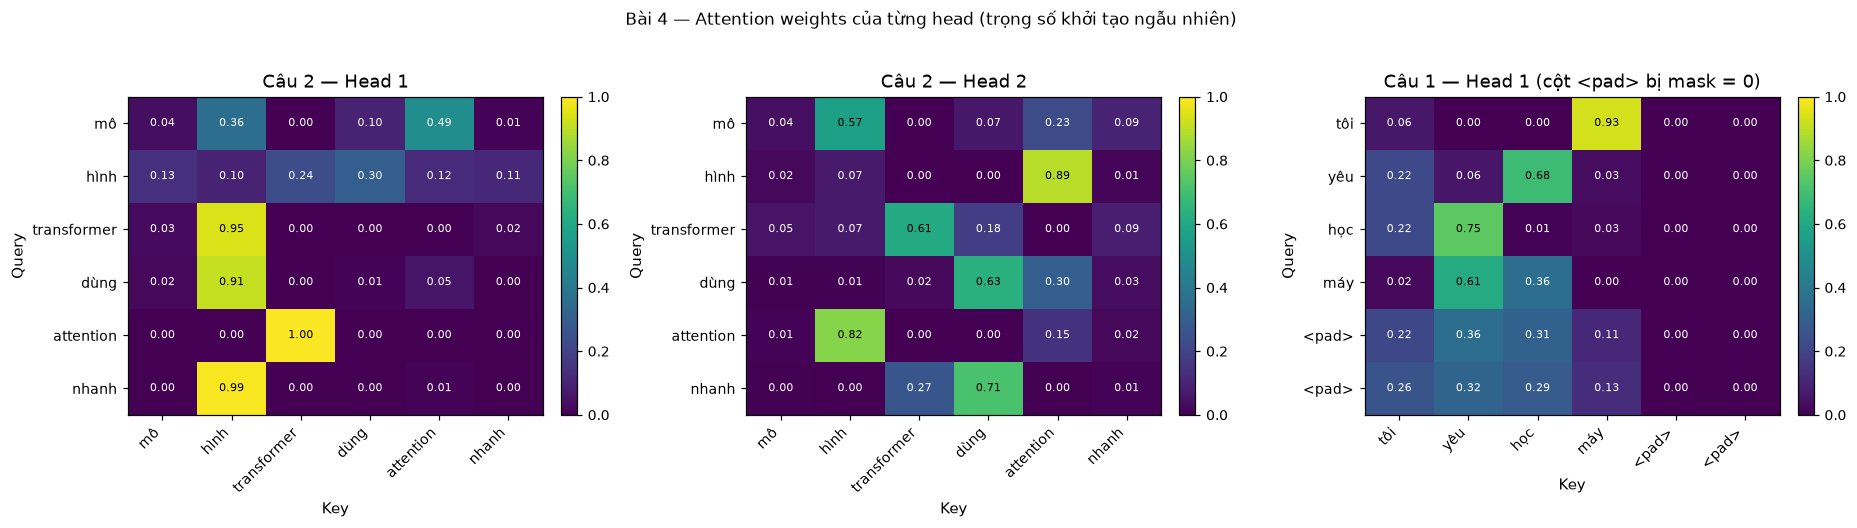

In [20]:
# ---- Trực quan hoá: so sánh attention của các head (mô hình CHƯA huấn luyện) ----
tok_b1 = [itos[i] for i in src_ids[1].tolist()]      # 6 token thật
tok_b0 = [itos[i] for i in src_ids[0].tolist()]      # 4 token thật + 2 <pad>
w = to_np(mha.attn_weights)                           # (B, h, L, L)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
plot_heatmap(axes[0], w[1, 0], tok_b1, tok_b1, "Câu 2 — Head 1", "Key", "Query", cmap="viridis", vmin=0, vmax=1)
plot_heatmap(axes[1], w[1, 1], tok_b1, tok_b1, "Câu 2 — Head 2", "Key", "Query", cmap="viridis", vmin=0, vmax=1)
plot_heatmap(axes[2], w[0, 0], tok_b0, tok_b0, "Câu 1 — Head 1 (cột <pad> bị mask = 0)", "Key", "Query", cmap="viridis", vmin=0, vmax=1)
plt.suptitle("Bài 4 — Attention weights của từng head (trọng số khởi tạo ngẫu nhiên)", y=1.03)
plt.tight_layout()
plt.show()

**Giải thích biểu đồ Bài 4**
- Hai head (hình 1 và 2) cho **hai ma trận attention khác nhau** dù cùng nhận một đầu vào, vì mỗi head có $W^Q,W^K,W^V$ riêng → mỗi head nhìn câu qua một "lăng kính" khác. Sau huấn luyện, các head thường chuyên biệt hoá (xem hình attention đã huấn luyện ở Bài 11).
- Hình 3: các **cột `<pad>` bằng 0** — padding mask đã ngăn mọi query chú ý vào token đệm; mỗi hàng vẫn có tổng bằng 1 trên các token thật.
- Kiểm chứng số liệu cho thấy bản tự viết khớp `nn.MultiheadAttention` (sai khác ~$10^{-6}$).

## Bài 5. Masked Multi-Head Attention (Causal Mask)

### 5.1. Vì sao Decoder không được nhìn token tương lai?
Decoder được huấn luyện để dự đoán token $t$ **chỉ từ các token trước nó** vì khi suy luận thật, các token tương lai **chưa tồn tại**. Nếu lúc huấn luyện cho Decoder thấy đáp án (token $t$ hoặc sau đó) thì nó chỉ cần **sao chép** — loss giảm rất nhanh nhưng mô hình vô dụng khi sinh văn bản thật (*rò rỉ thông tin*, data leakage).

> **Kiến thức rút ra:**
>
> - Khi suy luận, token tương lai **chưa tồn tại** → lúc huấn luyện cũng không được nhìn.
> - Nếu nhìn được → mô hình chỉ **sao chép đáp án** (rò rỉ dữ liệu), loss thấp nhưng vô dụng.

### 5.2. Công thức
Thêm ma trận mask $M\in\mathbb{R}^{L\times L}$ vào điểm số trước softmax:

$$\mathrm{MaskedAttention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}+M\right)V,\qquad
M_{ij}=\begin{cases}0 & j\le i\\ -\infty & j>i\end{cases}$$

- $e^{-\infty}=0$ ⇒ sau softmax, trọng số lên token tương lai **đúng bằng 0**, các hàng vẫn có tổng bằng 1.
- Mask là **tam giác dưới (lower-triangular)**: token $i$ chỉ nhìn $0,\dots,i$.
- Trong code dùng giá trị rất âm `-1e9` thay cho $-\infty$ để tránh `NaN` nếu một hàng bị che hoàn toàn.

**Mask kết hợp ở Decoder** = mask padding **AND** mask nhân quả.

**Vị trí trong kiến trúc:** hộp *Masked Multi-Head Attention* dưới cùng của Decoder.

> **Kiến thức rút ra:**
>
> - Cộng mask $M$ vào điểm số: $M_{ij}=0$ nếu $j\le i$, $-\infty$ nếu $j>i$ → **tam giác dưới**.
> - Sau softmax, trọng số lên tương lai **= 0**; mỗi hàng vẫn có tổng = 1.
> - Code dùng `-1e9` thay cho $-\infty$ để tránh NaN.
> - Mask của Decoder = **padding AND nhân quả**.

Causal mask (1 = được nhìn, 0 = bị che):
tensor([[1, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1]], dtype=torch.int32)

Attention weights (có mask), làm tròn 3 chữ số:
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4267, 0.5733, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3364, 0.2582, 0.4053, 0.0000, 0.0000, 0.0000],
        [0.2471, 0.2164, 0.2475, 0.2889, 0.0000, 0.0000],
        [0.1804, 0.1820, 0.1802, 0.2017, 0.2556, 0.0000],
        [0.1823, 0.1416, 0.1654, 0.1639, 0.1259, 0.2209]])
Tổng mỗi hàng: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


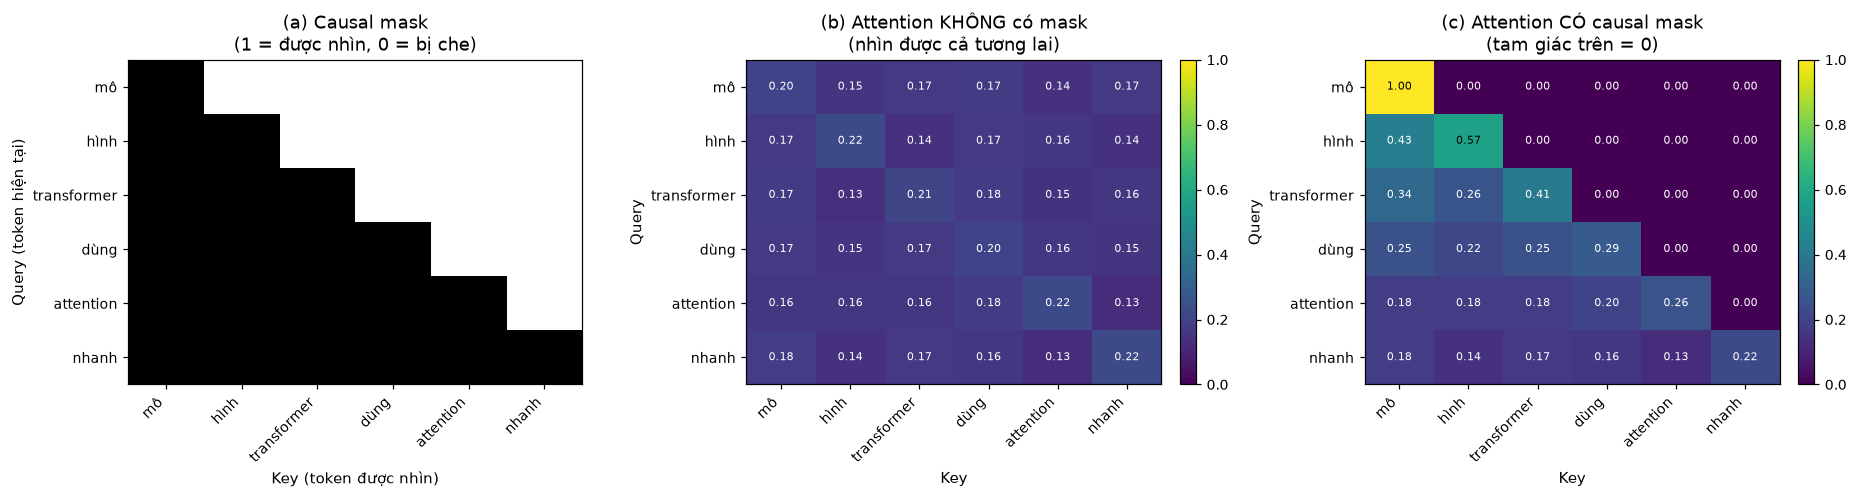

In [53]:
# ============================================================
# BÀI 5 — Causal Mask + so sánh attention trước/sau mask
# ============================================================
def make_causal_mask(L):
    """(1, 1, L, L) — True ở tam giác dưới (được nhìn), False ở tam giác trên (tương lai)."""
    return torch.tril(torch.ones(L, L, dtype=torch.bool)).unsqueeze(0).unsqueeze(0)

def make_tgt_mask(tgt, pad_idx):
    """Mask của Decoder = mask padding AND mask nhân quả. tgt: (B, Lt) -> (B, 1, Lt, Lt)."""
    Lt = tgt.size(1)
    return make_pad_mask(tgt, pad_idx) & make_causal_mask(Lt).to(tgt.device)   # (B,1,1,Lt) & (1,1,Lt,Lt)

causal = make_causal_mask(L)
print("Causal mask (1 = được nhìn, 0 = bị che):")
print(causal[0, 0].int())

# Dùng câu 2 (6 token thật) làm ví dụ. Q = K = V = x.
# - Chuẩn hoá về độ dài 1 (F.normalize) để điểm số vừa phải -> attention "mềm", dễ quan sát
#   (nếu dùng thẳng x, tích vô hướng của token với chính nó quá lớn nên attention gần như chỉ nhìn chính nó).
# - unsqueeze(1) thêm chiều head giả: (1, L, d_model) -> (1, 1, L, d_model), khớp dạng (B, h, L, d) của MHA.
def prep(t):
    return F.normalize(t, dim=-1).unsqueeze(1)

xb = x[1:2].detach()                                           # (1, L, d_model)
xq = prep(xb)                                                  # (1, 1, L, d_model)
out_nomask, w_nomask = scaled_dot_product_attention(xq, xq, xq)                 # KHÔNG mask -> w: (1, 1, L, L)
out_masked, w_masked = scaled_dot_product_attention(xq, xq, xq, causal)         # CÓ mask nhân quả -> (1, 1, L, L)
print("\nAttention weights (có mask), làm tròn 3 chữ số:")
print(w_masked[0, 0])
print("Tổng mỗi hàng:", w_masked[0, 0].sum(-1))

# ---- Biểu đồ: Mask / Trước mask / Sau mask ----
tok = [itos[i] for i in src_ids[1].tolist()]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
plot_heatmap(axes[0], causal[0, 0].int(), tok, tok, "(a) Causal mask\n(1 = được nhìn, 0 = bị che)", "Key (token được nhìn)", "Query (token hiện tại)", cmap="Greys", fmt="d", vmin=0, vmax=1, colorbar=False)
plot_heatmap(axes[1], w_nomask[0, 0], tok, tok, "(b) Attention KHÔNG có mask\n(nhìn được cả tương lai)", "Key", "Query", cmap="viridis", vmin=0, vmax=1)
plot_heatmap(axes[2], w_masked[0, 0], tok, tok, "(c) Attention CÓ causal mask\n(tam giác trên = 0)", "Key", "Query", cmap="viridis", vmin=0, vmax=1)
plt.tight_layout()
plt.show()

In [54]:
# ---- THÍ NGHIỆM RÒ RỈ: thay đổi token CUỐI, xem đầu ra các vị trí TRƯỚC có đổi không ----
x_changed = xb.clone()
x_changed[0, -1] += 10.0                                       # "phá" token cuối cùng (vị trí cuối)

def run(inp, m):
    q = prep(inp)                                              # (1, 1, L, d_model)
    return scaled_dot_product_attention(q, q, q, m)[0]         # output: (1, 1, L, d_model)

for name, m in [("KHÔNG mask", None), ("CÓ causal mask", causal)]:
    before, after = run(xb, m), run(x_changed, m)
    unchanged = torch.isclose(before[0, 0, :-1], after[0, 0, :-1], atol=1e-6).all().item()
    max_diff = (before[0, 0, :-1] - after[0, 0, :-1]).abs().max().item()
    print(f"{name:15s}: đầu ra các vị trí TRƯỚC token cuối có GIỮ NGUYÊN khi đổi token cuối ?  {unchanged}   (lệch tối đa = {max_diff:.6f})")

print("\n⇒ Khi KHÔNG mask, token sớm 'biết' token tương lai (rò rỉ). Khi CÓ mask, đầu ra tại vị trí t chỉ phụ thuộc token ≤ t.")

# ---- Mask kết hợp của Decoder (padding AND causal) ----
tgt_demo = torch.tensor([[SOS, stoi["tôi"], stoi["yêu"], PAD, PAD]])         # có 2 <pad> cuối
print("\ntgt_mask kết hợp (B,1,Lt,Lt) = padding AND causal:")
print(make_tgt_mask(tgt_demo, PAD)[0, 0].int())

KHÔNG mask     : đầu ra các vị trí TRƯỚC token cuối có GIỮ NGUYÊN khi đổi token cuối ?  False   (lệch tối đa = 0.095323)
CÓ causal mask : đầu ra các vị trí TRƯỚC token cuối có GIỮ NGUYÊN khi đổi token cuối ?  True   (lệch tối đa = 0.000000)

⇒ Khi KHÔNG mask, token sớm 'biết' token tương lai (rò rỉ). Khi CÓ mask, đầu ra tại vị trí t chỉ phụ thuộc token ≤ t.

tgt_mask kết hợp (B,1,Lt,Lt) = padding AND causal:
tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 0, 0]], dtype=torch.int32)


**Giải thích biểu đồ và thí nghiệm Bài 5**
- **(a)** Tam giác dưới màu sáng = các cặp (query, key) được phép.
- **(b) vs (c):** ở (b) mỗi hàng có trọng số ở cả bên phải đường chéo (tương lai); ở (c) toàn bộ phần đó bằng 0, hàng 0 chỉ nhìn chính nó (trọng số = 1), hàng cuối nhìn được cả 6 token. Tổng mỗi hàng vẫn bằng 1.
- **Thí nghiệm rò rỉ** chứng minh bằng số: không mask thì sửa token cuối làm thay đổi đầu ra của các vị trí trước; có mask thì **không đổi** (lệch = 0). Đây chính là đảm bảo *tự hồi quy* của Decoder.
- Mask kết hợp: các cột `<pad>` bị che cùng với tương lai.

## Bài 6. Position-wise Feed-Forward Network (FFN)

### 6.1. Khái niệm
Sau attention (trộn thông tin **giữa** các vị trí), mỗi block có một mạng MLP 2 lớp **áp dụng độc lập và giống hệt lên từng vị trí** (cùng trọng số cho mọi vị trí, nhưng **khác** trọng số giữa các layer). Vai trò: thêm **phi tuyến** và **năng lực biểu diễn** cho từng token — attention bản thân chỉ là trung bình có trọng số (tuyến tính theo $V$).

> **Kiến thức rút ra:**
>
> - MLP 2 lớp áp dụng **độc lập cho từng vị trí** (dùng chung trọng số giữa các vị trí, khác nhau giữa các layer).
> - Thêm **phi tuyến** và năng lực biểu diễn (attention chỉ là trung bình có trọng số).
> - Attention = trộn **giữa** các token; FFN = "suy nghĩ" **trong** từng token.

### 6.2. Công thức

$$\mathrm{FFN}(x)=\max(0,\;xW_1+b_1)\,W_2+b_2$$

| Biến | Kích thước | Ý nghĩa |
|---|---|---|
| $x$ | $(\dots, d_{model})$ | vector của một vị trí |
| $W_1$, $b_1$ | $(d_{model}, d_{ff})$, $(d_{ff})$ | lớp 1: **mở rộng** chiều (bài báo $512\to2048$) |
| $\max(0,\cdot)$ | — | **ReLU**: hàm kích hoạt phi tuyến |
| $W_2$, $b_2$ | $(d_{ff}, d_{model})$, $(d_{model})$ | lớp 2: **thu hẹp** về $d_{model}$ |

Tương đương hai phép tích chập kích thước kernel 1 (1×1 conv). Tensor: $(B,L,d_{model})\to(B,L,d_{ff})\to(B,L,d_{model})$ — **kích thước đầu vào = đầu ra** để residual cộng được.

**Vị trí trong kiến trúc:** hộp xanh *Feed Forward* trong mọi Encoder và Decoder block.

> **Kiến thức rút ra:**
>
> - $\mathrm{FFN}(x)=\max(0, xW_1+b_1)W_2+b_2$ — **mở rộng** $512\to2048$, ReLU, **thu hẹp** về 512.
> - Đầu vào và đầu ra cùng kích thước $d_{model}$ → cộng residual được.
> - Tương đương conv 1×1.

Đầu vào FFN        : (2, 6, 8)       = (B, L, d_model)
Sau lớp Linear 1   : (2, 6, 32)      = (B, L, d_ff)   ← mở rộng ×4
Sau ReLU           : (2, 6, 32)      (các giá trị âm bị đưa về 0)
Đầu ra FFN         : (2, 6, 8)       = (B, L, d_model)
Tỷ lệ nơ-ron ẩn bị ReLU tắt (=0): 50.78%
FFN(toàn câu)[0,3] == FFN(riêng vector vị trí 3) ? True
Số tham số FFN = d_model·d_ff + d_ff + d_ff·d_model + d_model = 552


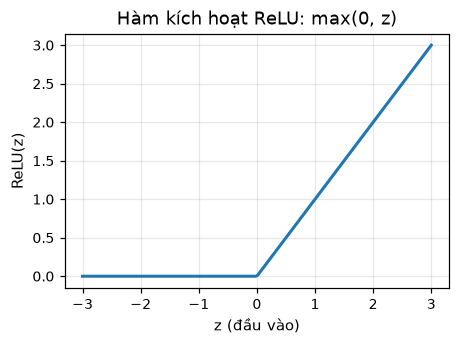

In [55]:
# ============================================================
# BÀI 6 — Position-wise Feed-Forward Network
# ============================================================
class PositionwiseFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.w_1 = nn.Linear(d_model, d_ff)      # mở rộng: d_model -> d_ff
        self.w_2 = nn.Linear(d_ff, d_model)      # thu hẹp: d_ff -> d_model
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):                        # x: (B, L, d_model)
        hidden = F.relu(self.w_1(x))             # (B, L, d_ff)   ReLU: max(0, ·)
        hidden = self.dropout(hidden)
        return self.w_2(hidden)                  # (B, L, d_model)

torch.manual_seed(0)
ffn = PositionwiseFeedForward(D_MODEL, D_FF, dropout=0.0)
ffn.eval()
with torch.no_grad():
    hidden = F.relu(ffn.w_1(x))
    y = ffn(x)
print(f"Đầu vào FFN        : {tuple(x.shape)}       = (B, L, d_model)")
print(f"Sau lớp Linear 1   : {tuple(ffn.w_1(x).shape)}      = (B, L, d_ff)   ← mở rộng ×{D_FF // D_MODEL}")
print(f"Sau ReLU           : {tuple(hidden.shape)}      (các giá trị âm bị đưa về 0)")
print(f"Đầu ra FFN         : {tuple(y.shape)}       = (B, L, d_model)")
print(f"Tỷ lệ nơ-ron ẩn bị ReLU tắt (=0): {(hidden == 0).float().mean().item():.2%}")

# ---- Kiểm chứng tính 'position-wise': mỗi vị trí được xử lý ĐỘC LẬP, cùng trọng số ----
with torch.no_grad():
    one_pos = ffn(x[0, 3])                   # chỉ đưa vector của token vị trí 3 (shape (d_model,))
print("FFN(toàn câu)[0,3] == FFN(riêng vector vị trí 3) ?", torch.allclose(y[0, 3], one_pos, atol=1e-6))

# ---- Minh hoạ ReLU và số tham số ----
n_params = sum(p.numel() for p in ffn.parameters())
print(f"Số tham số FFN = d_model·d_ff + d_ff + d_ff·d_model + d_model = {n_params}")

fig, ax = plt.subplots(1, 1, figsize=(4.5, 3))
zs = torch.linspace(-3, 3, 200)
ax.plot(to_np(zs), to_np(F.relu(zs)), lw=2)
ax.set_title("Hàm kích hoạt ReLU: max(0, z)")
ax.set_xlabel("z (đầu vào)")
ax.set_ylabel("ReLU(z)")
ax.grid(alpha=0.3)
plt.show()

**Nhận xét Bài 6.** Kết quả `FFN(toàn câu)[0,3] == FFN(vector vị trí 3)` xác nhận: FFN **không trộn thông tin giữa các vị trí**. Việc trộn là nhiệm vụ riêng của attention; FFN chỉ "suy nghĩ thêm" trên từng token. Lớp ẩn rộng hơn ($d_{ff}=4\,d_{model}$) cho phép biến đổi phi tuyến phong phú trước khi thu về $d_{model}$.

## Bài 7. Add & Norm — Residual Connection và Layer Normalization

### 7.1. Residual Connection (Add)

$$y = x + \mathrm{Sublayer}(x)$$

Sub-layer chỉ cần học **phần chênh lệch** $F(x)=y-x$ thay vì cả phép biến đổi. Đạo hàm:

$$\frac{\partial y}{\partial x}=I+\frac{\partial\,\mathrm{Sublayer}(x)}{\partial x}$$

Số hạng **đơn vị $I$** cho gradient một **"đường cao tốc"** đi thẳng về lớp thấp → huấn luyện được mạng sâu (6 block × 2–3 sub-layer) mà không bị triệt tiêu gradient. Điều kiện: $x$ và $\mathrm{Sublayer}(x)$ phải **cùng kích thước** ($d_{model}$).

> **Kiến thức rút ra:**
>
> - $y = x + \mathrm{Sublayer}(x)$: sub-layer chỉ cần học **phần chênh lệch**.
> - Đạo hàm có số hạng $I$ → gradient có **đường tắt** về lớp thấp → huấn luyện được mạng sâu.
> - Yêu cầu $x$ và $\mathrm{Sublayer}(x)$ **cùng kích thước**.

### 7.2. Layer Normalization (Norm)

Với vector $x\in\mathbb{R}^{d_{model}}$ của **một token**:

$$\mu=\frac1d\sum_{j=1}^{d}x_j,\qquad \sigma^2=\frac1d\sum_{j=1}^{d}(x_j-\mu)^2,\qquad
\mathrm{LN}(x)=\gamma\odot\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta$$

| Biến | Ý nghĩa |
|---|---|
| $\mu,\sigma^2$ | trung bình / phương sai **trên chiều đặc trưng của từng token** (không trộn giữa các token hay giữa các mẫu batch) |
| $\epsilon$ | hằng nhỏ ($10^{-5}$) để tránh chia cho 0 |
| $\gamma,\beta$ | tham số học được (co giãn và dịch) — khởi tạo $\gamma=1,\beta=0$ |
| $\odot$ | nhân từng phần tử |

**Vì sao LayerNorm mà không phải BatchNorm?** Độ dài câu thay đổi và batch nhỏ; LayerNorm không phụ thuộc batch nên ổn định và dùng như nhau ở huấn luyện/suy luận.

> **Kiến thức rút ra:**
>
> - Chuẩn hoá **mỗi token** theo chiều đặc trưng: trừ trung bình, chia độ lệch chuẩn, rồi nhân $\gamma$ cộng $\beta$ (học được).
> - Không phụ thuộc batch → hợp với câu dài ngắn khác nhau, batch nhỏ, chạy giống nhau khi train và khi suy luận.

### 7.3. Vì sao phải kết hợp hai kỹ thuật?
- **Residual** giữ cho gradient chảy được, nhưng cộng dồn nhiều nhánh làm **độ lớn kích hoạt** trôi/tăng dần.
- **LayerNorm** kéo mỗi vector token về trung bình 0, phương sai 1 → **ổn định độ lớn** và làm bề mặt loss dễ tối ưu hơn.
- Bài báo dùng **Post-LN**: $\;\mathrm{LayerNorm}\big(x+\mathrm{Dropout}(\mathrm{Sublayer}(x))\big)$ — đúng như hộp *Add & Norm*.

**Vị trí trong kiến trúc:** hộp vàng *Add & Norm* sau **mỗi** sub-layer (Encoder: 2 hộp/block; Decoder: 3 hộp/block).

> **Kiến thức rút ra:**
>
> - **Residual** lo **đường đi của gradient**; **LayerNorm** lo **thang đo của giá trị kích hoạt**.
> - Chỉ có residual → giá trị kích hoạt lớn dần theo độ sâu; LayerNorm kéo về mean 0, var 1.
> - Bài báo dùng **Post-LN**: $\mathrm{LN}(x+\mathrm{Dropout}(\mathrm{Sublayer}(x)))$.

In [56]:
# ============================================================
# BÀI 7 — Layer Normalization (từ đầu) + Residual + SublayerConnection (Add & Norm)
# ============================================================
class LayerNormScratch(nn.Module):
    def __init__(self, d_model, eps=1e-5):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))      # γ (co giãn), khởi tạo 1
        self.beta = nn.Parameter(torch.zeros(d_model))      # β (dịch),    khởi tạo 0
        self.eps = eps

    def forward(self, x):                                    # x: (..., d_model)
        mean = x.mean(dim=-1, keepdim=True)                  # μ  : (..., 1)
        var = x.var(dim=-1, keepdim=True, unbiased=False)    # σ² : (..., 1) (chia cho d, không phải d-1)
        x_hat = (x - mean) / torch.sqrt(var + self.eps)      # chuẩn hoá về mean=0, var=1
        return self.gamma * x_hat + self.beta

ln = LayerNormScratch(D_MODEL)
y_ln = ln(x)
print("Kích thước giữ nguyên:", tuple(x.shape), "→", tuple(y_ln.shape))
print("Trước LN — token (0,0): mean = %.4f, std = %.4f" % (x[0, 0].mean(), x[0, 0].std(unbiased=False)))
print("Sau  LN — token (0,0): mean = %.4f, std = %.4f" % (y_ln[0, 0].mean(), y_ln[0, 0].std(unbiased=False)))
print("Tự viết == nn.LayerNorm ?", torch.allclose(y_ln, nn.LayerNorm(D_MODEL)(x), atol=1e-5))

class SublayerConnection(nn.Module):
    """Add & Norm (Post-LN, đúng bài báo):  LayerNorm( x + Dropout( Sublayer(x) ) )"""
    def __init__(self, d_model, dropout=0.1):
        super().__init__()
        self.norm = LayerNormScratch(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, sublayer):
        return self.norm(x + self.dropout(sublayer(x)))      # residual rồi chuẩn hoá

addnorm = SublayerConnection(D_MODEL, dropout=0.0)
y_an = addnorm(x, ffn)                                       # Add & Norm quanh FFN
print("\nAdd&Norm(x, FFN): input", tuple(x.shape), "→ output", tuple(y_an.shape), "(giữ nguyên để xếp chồng được)")

Kích thước giữ nguyên: (2, 6, 8) → (2, 6, 8)
Trước LN — token (0,0): mean = -1.2813, std = 1.7244
Sau  LN — token (0,0): mean = 0.0000, std = 1.0000
Tự viết == nn.LayerNorm ? True

Add&Norm(x, FFN): input (2, 6, 8) → output (2, 6, 8) (giữ nguyên để xếp chồng được)


‖gradient‖ tại lớp ĐẦU của mạng 40 lớp:
  Không residual : 3.196e-12
  Có residual    : 2.029e+01
  → residual cho gradient lớn hơn khoảng 6.3e+12 lần


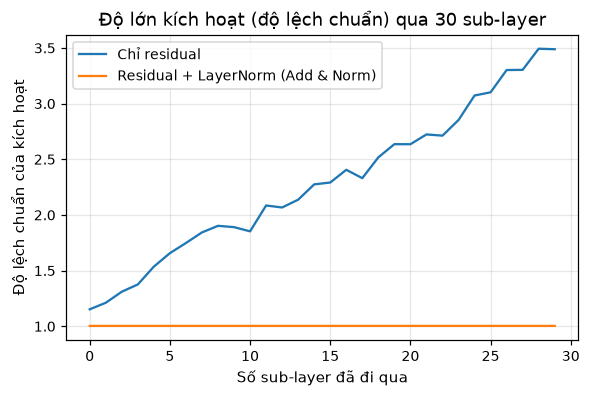

In [57]:
# ---- Thí nghiệm: Residual giúp gradient chảy về lớp đầu của mạng sâu ----
def grad_norm_first_layer(use_residual, depth=40, d=16, seed=0):
    torch.manual_seed(seed)
    layers = nn.ModuleList([nn.Linear(d, d) for _ in range(depth)])
    h = torch.randn(8, d)
    for layer in layers:
        out = torch.tanh(layer(h))
        h = h + out if use_residual else out              # có / không có đường tắt
    loss = h.pow(2).mean()
    loss.backward()
    return layers[0].weight.grad.norm().item()

g_plain = grad_norm_first_layer(False)
g_res = grad_norm_first_layer(True)
print(f"‖gradient‖ tại lớp ĐẦU của mạng 40 lớp:")
print(f"  Không residual : {g_plain:.3e}")
print(f"  Có residual    : {g_res:.3e}")
print(f"  → residual cho gradient lớn hơn khoảng {g_res / max(g_plain, 1e-30):.1e} lần")

# ---- Thí nghiệm: LayerNorm ổn định độ lớn khi cộng dồn nhiều nhánh ----
torch.manual_seed(0)
h_raw = torch.randn(8, 16)
h_ln = h_raw.clone()
std_raw, std_ln = [], []
blocks = [nn.Linear(16, 16) for _ in range(30)]
norm_fn = LayerNormScratch(16)
for blk in blocks:
    h_raw = h_raw + torch.tanh(blk(h_raw)) * 1.0                    # chỉ residual
    h_ln = norm_fn(h_ln + torch.tanh(blk(h_ln)) * 1.0)              # residual + LayerNorm
    std_raw.append(h_raw.std().item()); std_ln.append(h_ln.std().item())

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(std_raw, label="Chỉ residual")
ax.plot(std_ln, label="Residual + LayerNorm (Add & Norm)")
ax.set_title("Độ lớn kích hoạt (độ lệch chuẩn) qua 30 sub-layer")
ax.set_xlabel("Số sub-layer đã đi qua")
ax.set_ylabel("Độ lệch chuẩn của kích hoạt")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Nhận xét Bài 7**
- Sau LayerNorm, mỗi token có trung bình ≈ 0 và độ lệch chuẩn ≈ 1; bản tự viết khớp `nn.LayerNorm`.
- Thí nghiệm gradient: mạng 40 lớp **không có đường tắt** cho gradient ở lớp đầu nhỏ hơn rất nhiều bậc so với mạng có residual (vanishing gradient).
- Biểu đồ: nếu chỉ cộng residual, độ lớn kích hoạt **tăng dần** theo độ sâu; LayerNorm giữ nó ổn định ≈ 1. Hai kỹ thuật **bổ sung cho nhau**: residual lo *đường đi của gradient*, LayerNorm lo *thang đo của kích hoạt*.

## Bài 8. Encoder Block

### 8.1. Cấu trúc
Một **Encoder block** (một khối "Nx" bên trái hình) gồm **2 sub-layer**, mỗi sub-layer được bọc bởi *Add & Norm*:

$$\begin{aligned}
z &= \mathrm{LN}\big(x+\mathrm{Dropout}(\mathrm{MultiHeadSelfAttn}(x,x,x))\big)\\
y &= \mathrm{LN}\big(z+\mathrm{Dropout}(\mathrm{FFN}(z))\big)
\end{aligned}$$

| Sub-layer | Vai trò | Mask |
|---|---|---|
| **Multi-Head Self-Attention** | mỗi token thu thập thông tin từ **mọi** token nguồn (hai chiều) | chỉ mask padding |
| **Position-wise FFN** | biến đổi phi tuyến từng token | — |

Tensor: $(B,L_{src},d_{model})\to(B,L_{src},d_{model})$ — **không đổi kích thước**, nên xếp chồng $N$ block được. **Encoder** = $N$ block nối tiếp; đầu ra block $n$ là đầu vào block $n+1$. Đầu ra cuối cùng là **memory** gửi cho Decoder.

> **Kiến thức rút ra:**
>
> - Encoder block = **2 sub-layer**: Self-Attention → FFN, mỗi cái có Add & Norm.
> - Chỉ mask **padding**, không có causal mask → attention **hai chiều**.
> - Shape vào = shape ra → xếp chồng **N block**; đầu ra cuối cùng là **memory**.

In [58]:
# ============================================================
# BÀI 8 — Encoder Block và Encoder (N block xếp chồng)
# ============================================================
class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)      # sub-layer 1
        self.ffn = PositionwiseFeedForward(d_model, d_ff, dropout)            # sub-layer 2
        self.sublayers = nn.ModuleList([SublayerConnection(d_model, dropout) for _ in range(2)])  # 2 hộp Add&Norm

    def forward(self, x, src_mask):
        # Q = K = V = x  ->  self-attention
        x = self.sublayers[0](x, lambda t: self.self_attn(t, t, t, src_mask))
        x = self.sublayers[1](x, self.ffn)
        return x

class Encoder(nn.Module):
    def __init__(self, num_layers, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        # N block ĐỘC LẬP về trọng số (không chia sẻ tham số)
        self.layers = nn.ModuleList([EncoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])

    def forward(self, x, src_mask):
        for layer in self.layers:
            x = layer(x, src_mask)
        return x

torch.manual_seed(0)
enc_layer = EncoderLayer(D_MODEL, N_HEADS, D_FF, dropout=0.0).eval()

# ---- Đi từng bước bên trong một Encoder block ----
with torch.no_grad():
    a = enc_layer.self_attn(x, x, x, src_mask)                  # (B, L, d_model) self-attention
    z1 = enc_layer.sublayers[0].norm(x + a)                     # Add & Norm #1
    f = enc_layer.ffn(z1)                                       # (B, L, d_model) FFN
    z2 = enc_layer.sublayers[1].norm(z1 + f)                    # Add & Norm #2
    full = enc_layer(x, src_mask)

print(f"Đầu vào block               : {tuple(x.shape)}")
print(f"Sau Multi-Head Self-Attn    : {tuple(a.shape)}")
print(f"Sau Add & Norm #1           : {tuple(z1.shape)}")
print(f"Sau Feed Forward            : {tuple(f.shape)}")
print(f"Sau Add & Norm #2 (đầu ra)  : {tuple(z2.shape)}")
print("Đi tay từng bước == gọi enc_layer(...) ?", torch.allclose(z2, full, atol=1e-6))

# ---- Encoder N block ----
encoder = Encoder(N_LAYERS, D_MODEL, N_HEADS, D_FF, dropout=0.0).eval()
with torch.no_grad():
    memory = encoder(x, src_mask)
print(f"\nEncoder gồm N={N_LAYERS} block → memory.shape = {tuple(memory.shape)} = (B, L_src, d_model)")
print("Số tham số của 1 Encoder block:", sum(p.numel() for p in enc_layer.parameters()))

# ---- Kiểm tra: token <pad> không ảnh hưởng token thật ----
x_alt = x.clone()
x_alt[0, 4:] = torch.randn(2, D_MODEL) * 5            # thay hoàn toàn nội dung 2 vị trí <pad> của câu 1
with torch.no_grad():
    memory_alt = encoder(x_alt, src_mask)
print("Đổi nội dung <pad> có làm đổi đầu ra token thật (0..3) không ?",
      not torch.allclose(memory[0, :4], memory_alt[0, :4], atol=1e-6))

Đầu vào block               : (2, 6, 8)
Sau Multi-Head Self-Attn    : (2, 6, 8)
Sau Add & Norm #1           : (2, 6, 8)
Sau Feed Forward            : (2, 6, 8)
Sau Add & Norm #2 (đầu ra)  : (2, 6, 8)
Đi tay từng bước == gọi enc_layer(...) ? True

Encoder gồm N=2 block → memory.shape = (2, 6, 8) = (B, L_src, d_model)
Số tham số của 1 Encoder block: 872
Đổi nội dung <pad> có làm đổi đầu ra token thật (0..3) không ? False


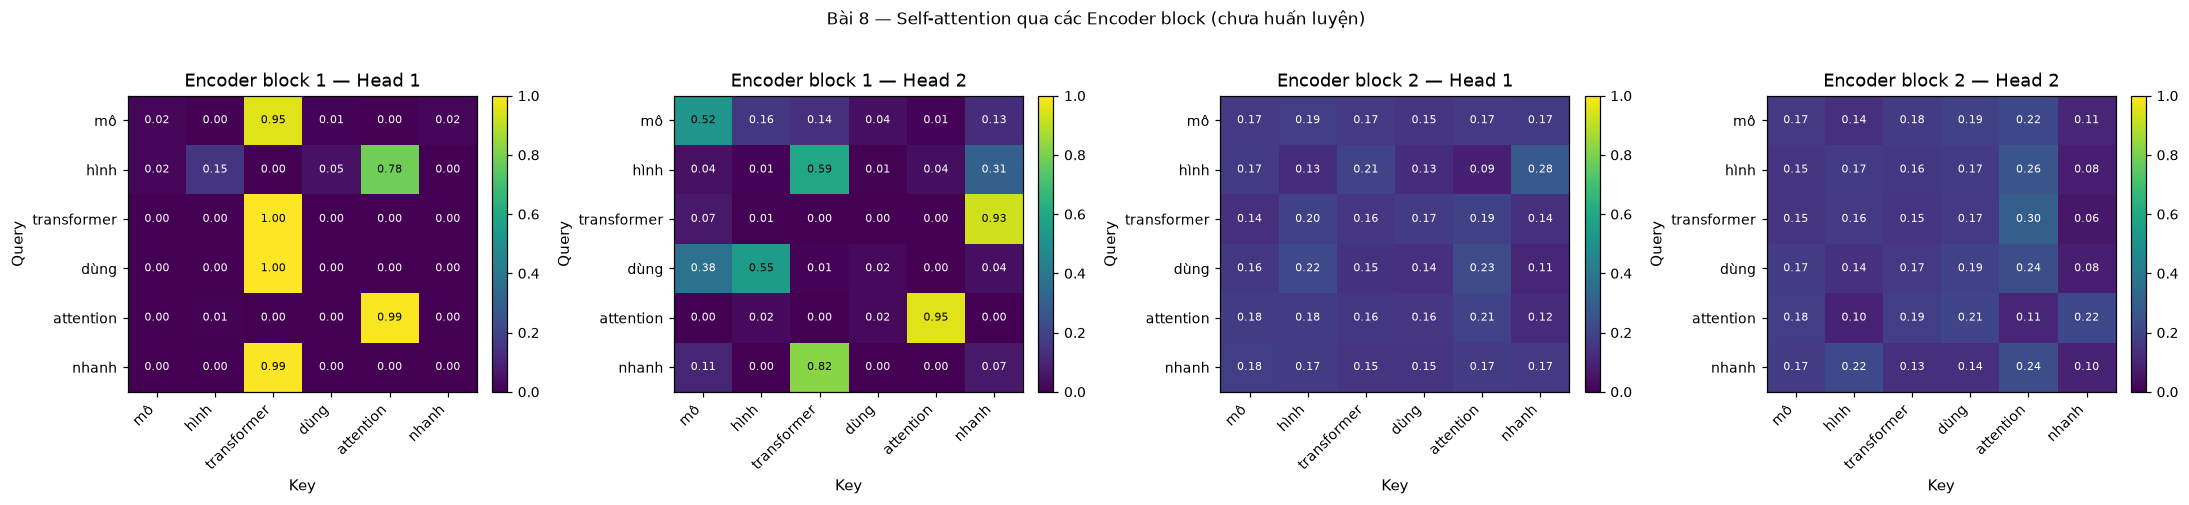

In [27]:
# ---- Trực quan hoá: attention của block đầu tiên của Encoder ----
with torch.no_grad():
    _ = encoder(x, src_mask)
attn_l0 = to_np(encoder.layers[0].self_attn.attn_weights)    # (B, h, L, L)
attn_l1 = to_np(encoder.layers[1].self_attn.attn_weights)
tok_b1 = [itos[i] for i in src_ids[1].tolist()]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
for h in range(N_HEADS):
    plot_heatmap(axes[h], attn_l0[1, h], tok_b1, tok_b1, f"Encoder block 1 — Head {h+1}", "Key", "Query", vmin=0, vmax=1)
    plot_heatmap(axes[2 + h], attn_l1[1, h], tok_b1, tok_b1, f"Encoder block 2 — Head {h+1}", "Key", "Query", vmin=0, vmax=1)
plt.suptitle("Bài 8 — Self-attention qua các Encoder block (chưa huấn luyện)", y=1.03)
plt.tight_layout()
plt.show()

**Nhận xét Bài 8.** Đầu ra mỗi block có **cùng shape** với đầu vào. Self-attention của Encoder **không có causal mask** nên ma trận attention đầy đủ (không có tam giác bằng 0). Thí nghiệm cuối cho thấy nội dung vị trí `<pad>` không làm đổi đầu ra của token thật — padding mask hoạt động đúng. Từ block 2 trở đi attention dựa trên biểu diễn đã được trộn ngữ cảnh ở block 1, nên khác với block 1.

## Bài 9. Decoder Block

### 9.1. Cấu trúc
Một **Decoder block** có **3 sub-layer**, mỗi cái bọc bởi *Add & Norm*:

$$\begin{aligned}
z_1 &= \mathrm{LN}\big(y+\mathrm{Drop}(\mathrm{MaskedMHA}(y,y,y;\;M_{tgt}))\big)\\
z_2 &= \mathrm{LN}\big(z_1+\mathrm{Drop}(\mathrm{MHA}(\underbrace{z_1}_{Q},\underbrace{m}_{K},\underbrace{m}_{V};\;M_{src}))\big)\\
z_3 &= \mathrm{LN}\big(z_2+\mathrm{Drop}(\mathrm{FFN}(z_2))\big)
\end{aligned}$$

với $y$ là đầu vào Decoder $(B,L_{tgt},d_{model})$, $m$ là **memory** từ Encoder $(B,L_{src},d_{model})$.

| Sub-layer | Q | K, V | Mask | Ma trận attention |
|---|---|---|---|---|
| ① Masked Self-Attention | $y$ | $y$ | padding ∧ nhân quả ($M_{tgt}$) | $L_{tgt}\times L_{tgt}$ |
| ② **Encoder–Decoder (Cross) Attention** | $z_1$ (Decoder) | **$m$ (Encoder)** | padding của nguồn ($M_{src}$) | $L_{tgt}\times L_{src}$ |
| ③ FFN | — | — | — | — |

**Ý nghĩa cross-attention:** mỗi token đích đặt câu hỏi "trong câu nguồn, phần nào liên quan đến tôi lúc này?" — chính là *căn chỉnh từ (alignment)* trong dịch máy. $Q$ có độ dài $L_{tgt}$ còn $K,V$ có độ dài $L_{src}$, nên ma trận attention **không vuông**, nhưng đầu ra vẫn có $L_{tgt}$ hàng → shape $(B,L_{tgt},d_{model})$.

> **Kiến thức rút ra:**
>
> - Decoder block = **3 sub-layer**: Masked Self-Attn → **Cross-Attn** → FFN, mỗi cái có Add & Norm.
> - Cross-Attn: **Q từ Decoder, K/V từ memory của Encoder** → ma trận $L_{tgt}\times L_{src}$.
> - Ý nghĩa: mỗi token đích hỏi "phần nào của câu nguồn liên quan đến tôi?" → **căn chỉnh từ (alignment)**.
> - Đầu ra vẫn là $(B, L_{tgt}, d_{model})$.

In [60]:
# ============================================================
# BÀI 9 — Decoder Block và Decoder
# ============================================================
class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)      # Masked self-attention
        self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)     # Encoder–Decoder attention
        self.ffn = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.sublayers = nn.ModuleList([SublayerConnection(d_model, dropout) for _ in range(3)])  # 3 hộp Add&Norm

    def forward(self, y, memory, src_mask, tgt_mask):
        # ① Masked self-attention: Q=K=V=y, mask nhân quả
        y = self.sublayers[0](y, lambda t: self.self_attn(t, t, t, tgt_mask))
        # ② Cross-attention: Q từ Decoder (t), K=V từ Encoder (memory)
        y = self.sublayers[1](y, lambda t: self.cross_attn(t, memory, memory, src_mask))
        # ③ Feed-forward
        y = self.sublayers[2](y, self.ffn)
        return y

class Decoder(nn.Module):
    def __init__(self, num_layers, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList([DecoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])

    def forward(self, y, memory, src_mask, tgt_mask):
        for layer in self.layers:
            y = layer(y, memory, src_mask, tgt_mask)       # CÙNG một memory được dùng ở mọi block
        return y

# ---- Dữ liệu demo: đầu vào Decoder đã embedding, độ dài L_tgt=5 khác L_src=6 ----
torch.manual_seed(0)
L_tgt = 5
y_in = torch.randn(B, L_tgt, D_MODEL)                              # (B, L_tgt, d_model) — giả lập embedding+PE phía đích
tgt_causal = make_causal_mask(L_tgt)                               # (1, 1, L_tgt, L_tgt)

dec_layer = DecoderLayer(D_MODEL, N_HEADS, D_FF, dropout=0.0).eval()
with torch.no_grad():
    out_dec = dec_layer(y_in, memory, src_mask, tgt_causal)

print(f"Đầu vào Decoder y     : {tuple(y_in.shape)}   = (B, L_tgt={L_tgt}, d_model)")
print(f"Memory (từ Encoder)   : {tuple(memory.shape)}   = (B, L_src={L}, d_model)")
print(f"Masked self-attn weights : {tuple(dec_layer.self_attn.attn_weights.shape)}  = (B, h, L_tgt, L_tgt)")
print(f"Cross-attn weights       : {tuple(dec_layer.cross_attn.attn_weights.shape)}  = (B, h, L_tgt, L_src)  ← KHÔNG vuông")
print(f"Đầu ra Decoder block  : {tuple(out_dec.shape)}   = (B, L_tgt, d_model)")

# ---- Kiểm chứng tính nhân quả của TOÀN BỘ block: đổi token tương lai không ảnh hưởng quá khứ ----
y_alt = y_in.clone()
y_alt[:, 4] += 10.0                                                # phá token cuối (vị trí 4)
with torch.no_grad():
    out_alt = dec_layer(y_alt, memory, src_mask, tgt_causal)
print("\nĐầu ra vị trí 0..3 giữ nguyên khi đổi token 4 ?", torch.allclose(out_dec[:, :4], out_alt[:, :4], atol=1e-6))
print("Đầu ra vị trí 4 có thay đổi ?", not torch.allclose(out_dec[:, 4], out_alt[:, 4], atol=1e-6))

# ---- Kiểm chứng: cross-attention THỰC SỰ dùng thông tin Encoder ----
memory_other = torch.randn_like(memory)
with torch.no_grad():
    out_other = dec_layer(y_in, memory_other, src_mask, tgt_causal)
print("Đổi memory có làm đổi đầu ra Decoder ?", not torch.allclose(out_dec, out_other, atol=1e-6))

Đầu vào Decoder y     : (2, 5, 8)   = (B, L_tgt=5, d_model)
Memory (từ Encoder)   : (2, 6, 8)   = (B, L_src=6, d_model)
Masked self-attn weights : (2, 2, 5, 5)  = (B, h, L_tgt, L_tgt)
Cross-attn weights       : (2, 2, 5, 6)  = (B, h, L_tgt, L_src)  ← KHÔNG vuông
Đầu ra Decoder block  : (2, 5, 8)   = (B, L_tgt, d_model)

Đầu ra vị trí 0..3 giữ nguyên khi đổi token 4 ? True
Đầu ra vị trí 4 có thay đổi ? True
Đổi memory có làm đổi đầu ra Decoder ? True


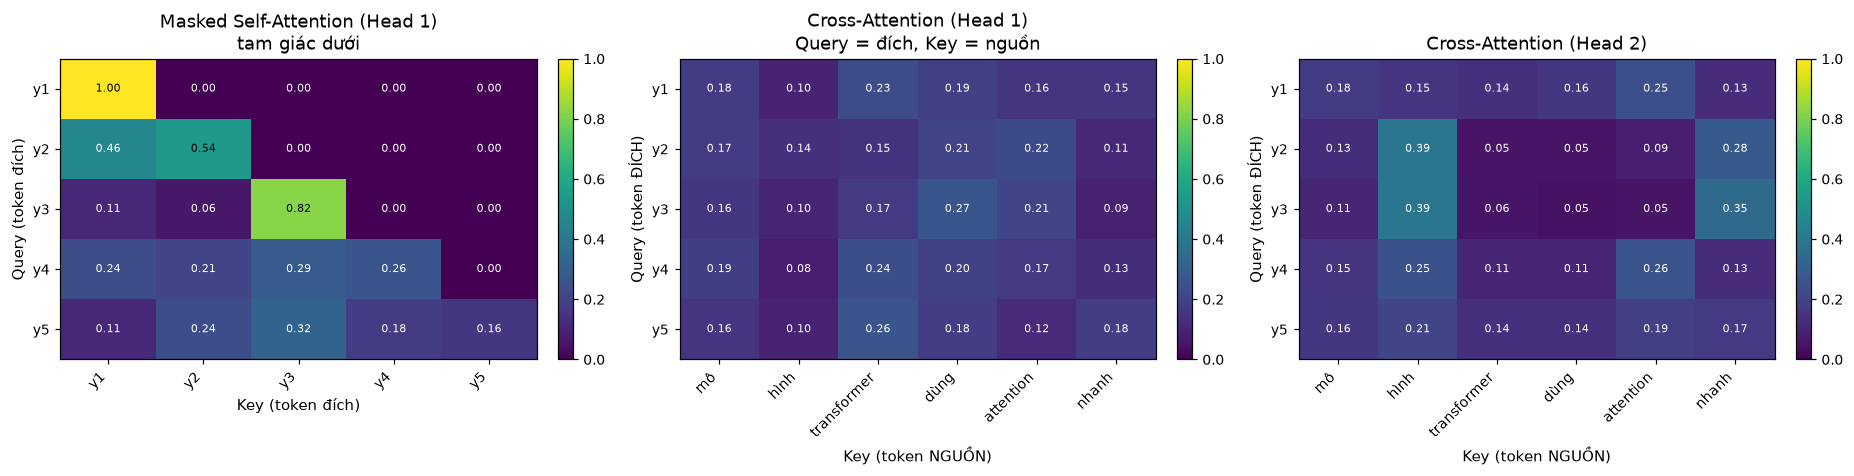

In [29]:
# ---- Trực quan hoá: Masked self-attention vs Cross-attention của cùng một Decoder block ----
with torch.no_grad():
    _ = dec_layer(y_in, memory, src_mask, tgt_causal)
sa = to_np(dec_layer.self_attn.attn_weights)     # (B, h, L_tgt, L_tgt)
ca = to_np(dec_layer.cross_attn.attn_weights)    # (B, h, L_tgt, L_src)
tgt_labels = [f"y{t+1}" for t in range(L_tgt)]
src_labels = [itos[i] for i in src_ids[1].tolist()]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
plot_heatmap(axes[0], sa[1, 0], tgt_labels, tgt_labels, "Masked Self-Attention (Head 1)\ntam giác dưới", "Key (token đích)", "Query (token đích)", vmin=0, vmax=1)
plot_heatmap(axes[1], ca[1, 0], src_labels, tgt_labels, "Cross-Attention (Head 1)\nQuery = đích, Key = nguồn", "Key (token NGUỒN)", "Query (token ĐÍCH)", vmin=0, vmax=1)
plot_heatmap(axes[2], ca[1, 1], src_labels, tgt_labels, "Cross-Attention (Head 2)", "Key (token NGUỒN)", "Query (token ĐÍCH)", vmin=0, vmax=1)
plt.tight_layout()
plt.show()

**Giải thích biểu đồ Bài 9.** Hình trái là ma trận $5\times5$ có dạng tam giác dưới (mask nhân quả). Hai hình phải là ma trận $5\times6$ **chữ nhật**: hàng = token đích, cột = token nguồn — đây là bảng căn chỉnh nguồn↔đích. Mô hình chưa huấn luyện nên chưa có cấu trúc rõ rệt; ở Bài 11 ta sẽ thấy cross-attention sau huấn luyện hình thành đúng các đường căn chỉnh.

## Bài 10. Xây dựng hoàn chỉnh Transformer Encoder–Decoder

### 10.1. Linear + Softmax và dự đoán token kế tiếp

Đầu ra của Decoder cuối cùng là \(D\in\mathbb{R}^{L_{tgt}\times d_{model}}\). Hai bước cuối trong hình:

$$
\text{logits}=D W_{out}+b_{out}
\in\mathbb{R}^{L_{tgt}\times |V|}
$$

$$
P(y_{t+1}=w\mid y_{\le t},x)
=\mathrm{softmax}(\text{logits}_t)_w
=\frac{e^{\text{logit}_{t,w}}}{\sum_{w'\in V}e^{\text{logit}_{t,w'}}}
$$

| Thành phần | Ý nghĩa |
|---|---|
| \(W_{out}\in\mathbb{R}^{d_{model}\times |V|}\) | **Linear**: chiếu vector ngữ cảnh sang một điểm số cho mỗi từ trong từ vựng đích |
| logits | Điểm số thô, có thể âm hoặc lớn |
| softmax | Biến điểm số thành xác suất dương, tổng bằng 1 |
| \(t\) | Vị trí; vector tại \(t\) dự đoán token thứ \(t+1\) (nhờ shifted right) |

**Dự đoán token tiếp theo (suy luận):** lấy phân phối ở vị trí cuối — `argmax` (greedy) hoặc lấy mẫu / beam search — nối vào chuỗi, lặp lại đến khi gặp `<eos>`.

**Huấn luyện:** dùng **cross-entropy**:

$$
\mathcal{L}=-\frac{1}{T}\sum_{t=1}^{T}\log P(y_t^*\mid\cdot)
$$

Trong PyTorch, `CrossEntropyLoss` đã gộp sẵn log-softmax nên mô hình trả **logits**; Softmax tường minh chỉ dùng khi cần xác suất (suy luận, hiển thị).

> **Kiến thức rút ra:**
>
> - **Linear:** $d_{model}\to|V|$ cho ra logits; **Softmax:** logits → xác suất trên từ vựng.
> - Vector ở vị trí $t$ dự đoán token $t+1$.
> - Suy luận: lấy phân phối ở **vị trí cuối** → greedy / sampling / beam search → lặp đến khi gặp `<eos>`.
> - Huấn luyện: **cross-entropy** trên logits (PyTorch đã gộp sẵn log-softmax).

### 10.2. Lắp ráp toàn bộ
$$x\xrightarrow{\text{Emb}\cdot\sqrt{d}+\text{PE}}\text{Encoder}^{\times N}\to m;\qquad
y\xrightarrow{\text{Emb}\cdot\sqrt{d}+\text{PE}}\text{Decoder}^{\times N}(\cdot,m)\xrightarrow{\text{Linear}}\text{logits}\xrightarrow{\text{softmax}}P$$

> **Kiến thức rút ra:**
>
> - Nguồn: Emb·√d + PE → Encoder × N → memory.
> - Đích: Emb·√d + PE → Decoder × N (dùng memory) → Linear → Softmax → $P$.

In [62]:
# ============================================================
# BÀI 10 — Transformer Encoder–Decoder hoàn chỉnh
# ============================================================
class Embeddings(nn.Module):
    """Token ID -> vector, nhân √d_model như bài báo."""
    def __init__(self, vocab_size, d_model, pad_idx=0):
        super().__init__()
        self.lut = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.d_model = d_model

    def forward(self, ids):                                   # (B, L) -> (B, L, d_model)
        return self.lut(ids) * math.sqrt(self.d_model)

class Transformer(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model=512, num_heads=8, d_ff=2048,
                 num_layers=6, dropout=0.1, max_len=512, pad_idx=0):
        super().__init__()
        self.src_embed = Embeddings(src_vocab, d_model, pad_idx)           # Input Embedding
        self.tgt_embed = Embeddings(tgt_vocab, d_model, pad_idx)           # Output Embedding
        self.pos_enc = PositionalEncoding(d_model, dropout, max_len)       # Positional Encoding
        self.encoder = Encoder(num_layers, d_model, num_heads, d_ff, dropout)   # Nx Encoder blocks
        self.decoder = Decoder(num_layers, d_model, num_heads, d_ff, dropout)   # Nx Decoder blocks
        self.generator = nn.Linear(d_model, tgt_vocab)                     # Linear (trước Softmax)
        # Khởi tạo Xavier cho các ma trận trọng số, như bản cài đặt tham chiếu
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def encode(self, src, src_mask):                       # (B, Ls) -> memory (B, Ls, d_model)
        return self.encoder(self.pos_enc(self.src_embed(src)), src_mask)

    def decode(self, tgt, memory, src_mask, tgt_mask):     # (B, Lt) -> (B, Lt, d_model)
        return self.decoder(self.pos_enc(self.tgt_embed(tgt)), memory, src_mask, tgt_mask)

    def forward(self, src, tgt, src_mask, tgt_mask):
        memory = self.encode(src, src_mask)
        dec_out = self.decode(tgt, memory, src_mask, tgt_mask)
        return self.generator(dec_out)                     # LOGITS: (B, Lt, |V_tgt|)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

# ---- Mô hình demo dùng cùng vocab ở hai phía (chỉ để minh hoạ luồng dữ liệu) ----
torch.manual_seed(0)
model_demo = Transformer(V, V, D_MODEL, N_HEADS, D_FF, N_LAYERS, dropout=0.0, max_len=64, pad_idx=PAD).eval()

tgt_in_demo = src_ids.clone()                              # (B, Lt) — dùng tạm câu nguồn làm "câu đích" để minh hoạ
tgt_mask_demo = make_tgt_mask(tgt_in_demo, PAD)            # (B, 1, Lt, Lt)

with torch.no_grad():
    logits = model_demo(src_ids, tgt_in_demo, src_mask, tgt_mask_demo)
    probs = F.softmax(logits, dim=-1)                      # Softmax: logits -> xác suất

print(f"src_ids        : {tuple(src_ids.shape)}            (B, L_src)")
print(f"tgt_in         : {tuple(tgt_in_demo.shape)}            (B, L_tgt)")
print(f"logits         : {tuple(logits.shape)}         (B, L_tgt, |V|={V})")
print(f"probs          : {tuple(probs.shape)}         (B, L_tgt, |V|)")
print("Tổng xác suất mỗi vị trí =1 ?", torch.allclose(probs.sum(-1), torch.ones(B, L), atol=1e-5))
print(f"Số tham số mô hình demo: {count_params(model_demo):,}")

src_ids        : (2, 6)            (B, L_src)
tgt_in         : (2, 6)            (B, L_tgt)
logits         : (2, 6, 26)         (B, L_tgt, |V|=26)
probs          : (2, 6, 26)         (B, L_tgt, |V|)
Tổng xác suất mỗi vị trí =1 ? True
Số tham số mô hình demo: 4,746


In [63]:
# ---- Dự đoán token kế tiếp (mô hình CHƯA huấn luyện => gần như ngẫu nhiên) ----
pos_last = 3                                                # xét vị trí 3 của câu 1
p = probs[0, pos_last]                                      # (|V|,) phân phối cho token kế tiếp
top_p, top_i = torch.topk(p, 5)
print(f"Top-5 token kế tiếp tại vị trí {pos_last} của câu 1 (xác suất đều ~ 1/|V| = {1 / V:.3f} vì chưa huấn luyện):")
for prob, idx in zip(top_p.tolist(), top_i.tolist()):
    print(f"   {itos[idx]:14s} P = {prob:.4f}")
print("Token được chọn (greedy argmax):", itos[int(p.argmax())])

# ---- Số tham số của cấu hình bài báo gốc (base): d_model=512, h=8, d_ff=2048, N=6 ----
paper_model = Transformer(1000, 1000, 512, 8, 2048, 6, dropout=0.1, max_len=64)
n_enc = count_params(paper_model.encoder); n_dec = count_params(paper_model.decoder)
print(f"\nCấu hình bài báo (vocab giả định 1000): Encoder {n_enc:,} + Decoder {n_dec:,} tham số; tổng {count_params(paper_model):,}")
print("→ Bài báo (vocab BPE ≈ 37 000, dùng chung trọng số) báo cáo ≈ 65 triệu tham số cho mô hình base.")
del paper_model

Top-5 token kế tiếp tại vị trí 3 của câu 1 (xác suất đều ~ 1/|V| = 0.038 vì chưa huấn luyện):
   sâu            P = 0.1125
   transformer    P = 0.0821
   lý             P = 0.0709
   ngôn           P = 0.0696
   yêu            P = 0.0582
Token được chọn (greedy argmax): sâu

Cấu hình bài báo (vocab giả định 1000): Encoder 18,914,304 + Decoder 25,224,192 tham số; tổng 45,675,496
→ Bài báo (vocab BPE ≈ 37 000, dùng chung trọng số) báo cáo ≈ 65 triệu tham số cho mô hình base.


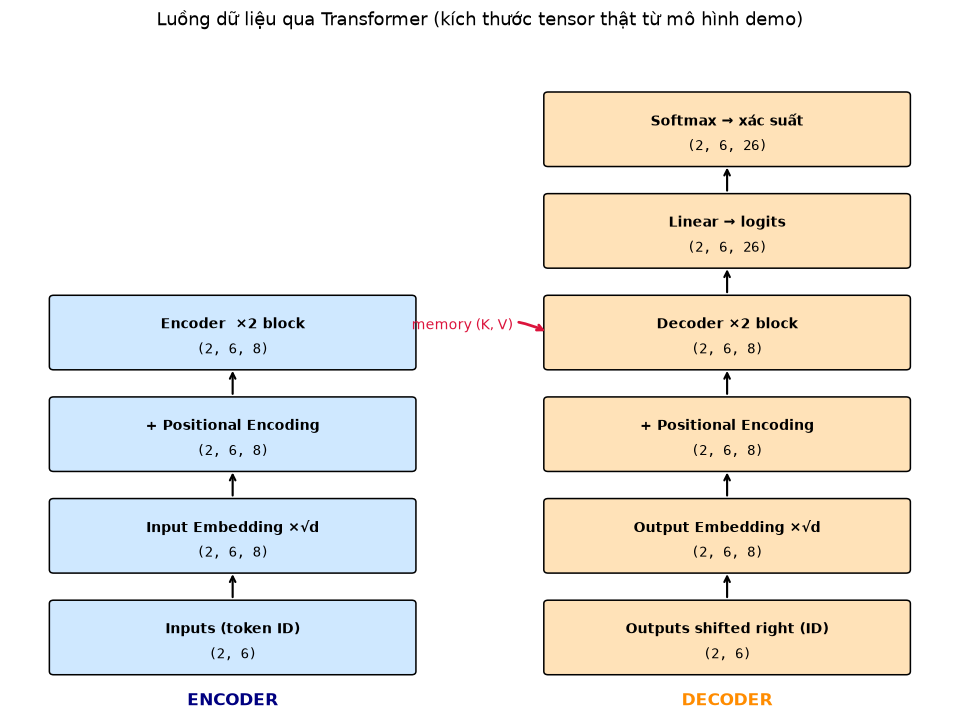

In [64]:
# ============================================================
# MINH HOẠ LUỒNG DỮ LIỆU QUA ENCODER–DECODER (kích thước tensor thật từ mô hình demo)
# ============================================================
from matplotlib.patches import FancyBboxPatch

with torch.no_grad():
    s1 = model_demo.src_embed(src_ids)                      # Input Embedding
    s2 = model_demo.pos_enc(s1)                             # + Positional Encoding
    mem = model_demo.encoder(s2, src_mask)                  # Nx Encoder
    t1 = model_demo.tgt_embed(tgt_in_demo)                  # Output Embedding
    t2 = model_demo.pos_enc(t1)                             # + Positional Encoding
    dec = model_demo.decoder(t2, mem, src_mask, tgt_mask_demo)   # Nx Decoder
    lg = model_demo.generator(dec)                          # Linear
    pr = F.softmax(lg, dim=-1)                              # Softmax

enc_steps = [("Inputs (token ID)", src_ids), ("Input Embedding ×√d", s1), ("+ Positional Encoding", s2),
             (f"Encoder  ×{N_LAYERS} block", mem)]
dec_steps = [("Outputs shifted right (ID)", tgt_in_demo), ("Output Embedding ×√d", t1), ("+ Positional Encoding", t2),
             (f"Decoder ×{N_LAYERS} block", dec), ("Linear → logits", lg), ("Softmax → xác suất", pr)]

fig, ax = plt.subplots(figsize=(11, 8))
ax.set_xlim(0, 11); ax.set_ylim(0, 10); ax.axis("off")
ax.set_title("Luồng dữ liệu qua Transformer (kích thước tensor thật từ mô hình demo)", fontsize=12)

def draw_stack(x0, steps, color):
    centers = []
    for k, (label, tensor) in enumerate(steps):
        y0 = 0.6 + k * 1.5
        box = FancyBboxPatch((x0, y0), 4.2, 1.0, boxstyle="round,pad=0.05", fc=color, ec="black", lw=1)
        ax.add_patch(box)
        ax.text(x0 + 2.1, y0 + 0.62, label, ha="center", va="center", fontsize=9, fontweight="bold")
        ax.text(x0 + 2.1, y0 + 0.25, str(tuple(tensor.shape)), ha="center", va="center", fontsize=9, family="monospace")
        if k > 0:
            ax.annotate("", xy=(x0 + 2.1, y0 - 0.02), xytext=(x0 + 2.1, y0 - 0.45), arrowprops=dict(arrowstyle="->", lw=1.4))
        centers.append((x0 + 2.1, y0 + 0.5))
    return centers

c_enc = draw_stack(0.5, enc_steps, "#cfe8ff")
c_dec = draw_stack(6.3, dec_steps, "#ffe2b8")
# mũi tên memory: đỉnh Encoder -> khối Decoder (bước thứ 4)
ax.annotate("memory (K, V)", xy=(6.3, c_dec[3][1]), xytext=(c_enc[3][0] + 2.1, c_enc[3][1]),
            arrowprops=dict(arrowstyle="->", lw=1.8, color="crimson", connectionstyle="arc3,rad=-0.2"),
            color="crimson", fontsize=9, ha="left", va="bottom")
ax.text(2.6, 0.1, "ENCODER", ha="center", fontsize=11, fontweight="bold", color="navy")
ax.text(8.4, 0.1, "DECODER", ha="center", fontsize=11, fontweight="bold", color="darkorange")
plt.show()

**Giải thích biểu đồ.** Đọc từ dưới lên: token ID $(B,L)$ trở thành tensor $(B,L,d_{model})$ sau embedding và **giữ nguyên kích thước** qua toàn bộ Encoder/Decoder; chỉ **Linear** cuối mới đổi chiều cuối thành $|V|$. Mũi tên đỏ là **memory** đi từ đỉnh Encoder vào Decoder (K, V của Cross-Attention).

**Lưu ý:** mô hình ở đây chưa huấn luyện nên phân phối xác suất gần đều (≈ $1/|V|$). Để Transformer thực sự dự đoán được, cần học — Bài 11.

## Bài 11. Huấn luyện một mô hình Transformer đơn giản (dịch máy mini Việt → Anh)

### 11.1. Bài toán
Bộ dữ liệu **tổng hợp** gồm câu tiếng Việt đơn giản → tiếng Anh, sinh theo mẫu *Chủ ngữ – Động từ – Danh từ [– Tính từ]*:

| Việt | Anh | Điểm cần học |
|---|---|---|
| `tôi yêu mèo` | `i love cats` | ánh xạ từ ↔ từ |
| `tôi yêu mèo đen` | `i love black cats` | **đảo thứ tự** danh từ–tính từ (tiếng Việt: *mèo đen*; tiếng Anh: *black cats*) → cần cross-attention căn chỉnh sai thứ tự |

- Tổng cộng 240 cặp câu (48 câu không tính từ + 192 câu có tính từ), **chia 80/20 theo tổ hợp ngẫu nhiên**: mô hình phải **khái quát** sang các tổ hợp từ chưa thấy.
- Có **độ dài thay đổi** (3 hoặc 4 từ) nên cần **padding + masking**.
- Nhỏ, chạy được trên **CPU** (khoảng vài chục giây).

> **Kiến thức rút ra:**
>
> - Dịch máy mini **Việt → Anh**, 240 cặp câu tổng hợp, chia 80/20.
> - Điểm khó: **đảo thứ tự** danh từ–tính từ (*mèo đen* → *black cats*) → cần cross-attention căn chỉnh tốt.
> - Câu dài 3–4 từ → cần **padding + mask**. Chạy được trên CPU.

### 11.2. Các thành phần huấn luyện
| Thành phần | Chọn | Lý do |
|---|---|---|
| Loss | `CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)` | bỏ qua vị trí đệm; label smoothing 0.1 như bài báo |
| Optimizer | Adam, $\beta_1=0.9,\beta_2=0.98,\epsilon=10^{-9}$ | đúng bài báo |
| LR schedule (Noam) | $lr=\text{factor}\cdot d_{model}^{-0.5}\cdot\min(step^{-0.5},\,step\cdot warmup^{-1.5})$ | tăng tuyến tính trong *warmup* rồi giảm theo $1/\sqrt{step}$ |
| Teacher forcing | Decoder nhận câu đích dịch phải; nhãn là câu đích dịch trái | huấn luyện song song |
| Suy luận | **Greedy decoding** từng token | mô phỏng thật |

> **Kiến thức rút ra:**
>
> - Loss: CrossEntropy, **bỏ qua `<pad>`**, label smoothing 0.1.
> - Adam ($\beta_2=0.98$) + **Noam LR**: tăng dần trong giai đoạn warmup, sau đó giảm theo $1/\sqrt{step}$.
> - **Teacher forcing** khi huấn luyện; **greedy decoding** khi suy luận.

In [65]:
# ============================================================
# BÀI 11 — Bước 1: Chuẩn bị dữ liệu (sinh theo mẫu)
# ============================================================
SUBJ = {"tôi": "i", "bạn": "you", "họ": "they", "chúng_ta": "we"}
VERB = {"yêu": "love", "thích": "like", "ghét": "hate"}
NOUN = {"mèo": "cats", "chó": "dogs", "sách": "books", "xe": "cars"}
ADJ  = {"đen": "black", "trắng": "white", "mới": "new", "cũ": "old"}

pairs = []   # mỗi phần tử: (danh sách token nguồn, danh sách token đích)
for s, v, n in itertools.product(SUBJ, VERB, NOUN):
    pairs.append(([s, v, n], [SUBJ[s], VERB[v], NOUN[n]]))                         # không tính từ
    for a in ADJ:
        pairs.append(([s, v, n, a], [SUBJ[s], VERB[v], ADJ[a], NOUN[n]]))           # tiếng Việt: N + A ; tiếng Anh: A + N

print("Tổng số cặp câu:", len(pairs))
for src_toks, tgt_toks in pairs[:3]:
    print("  ", " ".join(src_toks), "→", " ".join(tgt_toks))

# ---- Chia train / test theo tổ hợp ngẫu nhiên ----
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(pairs))
n_test = int(0.2 * len(pairs))
test_pairs = [pairs[i] for i in perm[:n_test]]
train_pairs = [pairs[i] for i in perm[n_test:]]
print(f"Train: {len(train_pairs)} cặp | Test (tổ hợp CHƯA thấy khi huấn luyện): {len(test_pairs)} cặp")

# ---- Bước 2: Vocabulary riêng cho nguồn và đích (token đặc biệt luôn có ID 0..3) ----
src_stoi, src_itos = make_vocab([p[0] for p in pairs])
tgt_stoi, tgt_itos = make_vocab([p[1] for p in pairs])
V_SRC, V_TGT = len(src_itos), len(tgt_itos)
print(f"|V_src| = {V_SRC}, |V_tgt| = {V_TGT}")
assert src_stoi["<pad>"] == PAD == 0 and tgt_stoi["<sos>"] == SOS and tgt_stoi["<eos>"] == EOS

# ---- Bước 3: Tạo Source / Target Sequence ----
#   source      : x1 x2 x3 <eos>
#   decoder in  : <sos> y1 y2 y3 y4        (dịch phải)
#   decoder out : y1 y2 y3 y4 <eos>        (nhãn: dịch trái)
def build_tensors(pair_list, max_src, max_tgt):
    src_seqs, tin_seqs, tout_seqs = [], [], []
    for s_toks, t_toks in pair_list:
        s_ids = [src_stoi[w] for w in s_toks] + [EOS]
        t_ids = [tgt_stoi[w] for w in t_toks]
        src_seqs.append(s_ids)
        tin_seqs.append([SOS] + t_ids)
        tout_seqs.append(t_ids + [EOS])
    # ---- Bước 4: PADDING về cùng độ dài ----
    return (pad_sequences(src_seqs, PAD, max_src),
            pad_sequences(tin_seqs, PAD, max_tgt),
            pad_sequences(tout_seqs, PAD, max_tgt))

MAX_SRC = max(len(p[0]) for p in pairs) + 1      # +1 cho <eos>
MAX_TGT = max(len(p[1]) for p in pairs) + 1
src_train, tin_train, tout_train = build_tensors(train_pairs, MAX_SRC, MAX_TGT)
src_test, tin_test, tout_test = build_tensors(test_pairs, MAX_SRC, MAX_TGT)

print(f"\nsrc_train {tuple(src_train.shape)} | tgt_in {tuple(tin_train.shape)} | tgt_out {tuple(tout_train.shape)}")
i0 = 0
print("Ví dụ cặp đầu tiên của tập train:")
print("  source     :", [src_itos[i] for i in src_train[i0].tolist()])
print("  decoder in :", [tgt_itos[i] for i in tin_train[i0].tolist()])
print("  decoder out:", [tgt_itos[i] for i in tout_train[i0].tolist()])
print("  src mask   :", make_pad_mask(src_train[i0:i0 + 1], PAD)[0, 0, 0].tolist())
print("  tgt mask (Lt×Lt):")
print(make_tgt_mask(tin_train[i0:i0 + 1], PAD)[0, 0].int())

Tổng số cặp câu: 240
   tôi yêu mèo → i love cats
   tôi yêu mèo đen → i love black cats
   tôi yêu mèo trắng → i love white cats
Train: 192 cặp | Test (tổ hợp CHƯA thấy khi huấn luyện): 48 cặp
|V_src| = 19, |V_tgt| = 19

src_train (192, 5) | tgt_in (192, 5) | tgt_out (192, 5)
Ví dụ cặp đầu tiên của tập train:
  source     : ['họ', 'yêu', 'xe', 'cũ', '<eos>']
  decoder in : ['<sos>', 'they', 'love', 'old', 'cars']
  decoder out: ['they', 'love', 'old', 'cars', '<eos>']
  src mask   : [True, True, True, True, True]
  tgt mask (Lt×Lt):
tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)


Số tham số mô hình: 171,091   cấu hình: {'d_model': 64, 'num_heads': 4, 'd_ff': 128, 'num_layers': 2, 'dropout': 0.1}


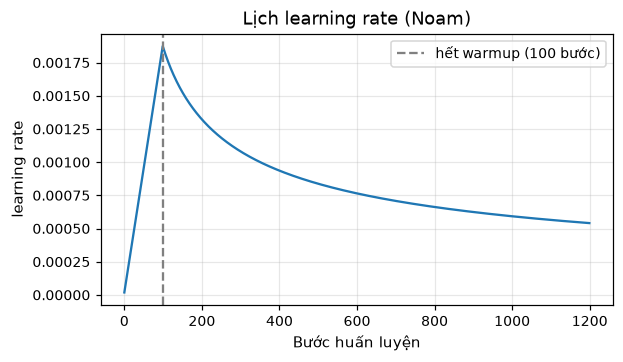

In [66]:
# ============================================================
# BÀI 11 — Bước 5: Mô hình, Loss, Optimizer, LR schedule
# ============================================================
CFG = dict(d_model=64, num_heads=4, d_ff=128, num_layers=2, dropout=0.1)
torch.manual_seed(SEED)
model = Transformer(V_SRC, V_TGT, CFG["d_model"], CFG["num_heads"], CFG["d_ff"], CFG["num_layers"],
                    CFG["dropout"], max_len=32, pad_idx=PAD)
print(f"Số tham số mô hình: {count_params(model):,}   cấu hình: {CFG}")

# Loss: bỏ qua <pad> trong nhãn; label smoothing 0.1 (như bài báo)
criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)

# Optimizer Adam theo bài báo; lr được đặt bởi scheduler ở mỗi bước
optimizer = torch.optim.Adam(model.parameters(), lr=0.0, betas=(0.9, 0.98), eps=1e-9)

class NoamScheduler:
    """lr = factor * d_model^-0.5 * min(step^-0.5, step * warmup^-1.5)"""
    def __init__(self, optimizer, d_model, warmup=100, factor=0.15):
        self.opt, self.d_model, self.warmup, self.factor, self.step_num = optimizer, d_model, warmup, factor, 0
    def step(self):
        self.step_num += 1
        lr = self.factor * self.d_model ** -0.5 * min(self.step_num ** -0.5, self.step_num * self.warmup ** -1.5)
        for g in self.opt.param_groups:
            g["lr"] = lr
        return lr

scheduler = NoamScheduler(optimizer, CFG["d_model"], warmup=100, factor=0.15)

def batch_loss(src, tgt_in, tgt_out):
    s_mask = make_pad_mask(src, PAD)                 # (B,1,1,Ls)
    t_mask = make_tgt_mask(tgt_in, PAD)              # (B,1,Lt,Lt)
    logits = model(src, tgt_in, s_mask, t_mask)      # (B, Lt, V_tgt)
    # CrossEntropyLoss cần (N, C) và (N,): gộp batch và thời gian
    return criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))

# ---- Đường cong learning rate (để hiểu warmup) ----
tmp = NoamScheduler(torch.optim.Adam([nn.Parameter(torch.zeros(1))]), CFG["d_model"], 100, 0.15)
lrs = [tmp.step() for _ in range(1200)]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(lrs); ax.axvline(100, ls="--", c="gray", label="hết warmup (100 bước)")
ax.set_title("Lịch learning rate (Noam)"); ax.set_xlabel("Bước huấn luyện"); ax.set_ylabel("learning rate")
ax.legend(); ax.grid(alpha=0.3); plt.show()

In [67]:
# ============================================================
# BÀI 11 — Bước 6: Vòng lặp huấn luyện (theo dõi loss từng epoch)
# ============================================================
EPOCHS, BATCH = 200, 32
train_losses, test_losses = [], []
N_train = src_train.size(0)
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    order = torch.randperm(N_train)
    running, nb = 0.0, 0
    for i in range(0, N_train, BATCH):
        idx = order[i:i + BATCH]
        loss = batch_loss(src_train[idx], tin_train[idx], tout_train[idx])
        optimizer.zero_grad()
        loss.backward()
        scheduler.step()                 # đặt lr theo lịch Noam
        optimizer.step()
        running += loss.item(); nb += 1
    train_losses.append(running / nb)

    model.eval()
    with torch.no_grad():
        test_losses.append(batch_loss(src_test, tin_test, tout_test).item())

    if epoch == 1 or epoch % 20 == 0:
        print(f"Epoch {epoch:3d}/{EPOCHS} | train loss = {train_losses[-1]:.4f} | test loss = {test_losses[-1]:.4f} | lr = {optimizer.param_groups[0]['lr']:.5f}")

print(f"\nHuấn luyện xong sau {time.time() - t0:.1f}s trên CPU.")

Epoch   1/200 | train loss = 3.7178 | test loss = 3.4133 | lr = 0.00011
Epoch  20/200 | train loss = 0.7193 | test loss = 0.7009 | lr = 0.00171
Epoch  40/200 | train loss = 0.6186 | test loss = 0.6176 | lr = 0.00121
Epoch  60/200 | train loss = 0.6030 | test loss = 0.6011 | lr = 0.00099
Epoch  80/200 | train loss = 0.5952 | test loss = 0.5950 | lr = 0.00086
Epoch 100/200 | train loss = 0.5935 | test loss = 0.5934 | lr = 0.00077
Epoch 120/200 | train loss = 0.5911 | test loss = 0.5906 | lr = 0.00070
Epoch 140/200 | train loss = 0.5901 | test loss = 0.5902 | lr = 0.00065
Epoch 160/200 | train loss = 0.5898 | test loss = 0.5895 | lr = 0.00061
Epoch 180/200 | train loss = 0.5891 | test loss = 0.5891 | lr = 0.00057
Epoch 200/200 | train loss = 0.5887 | test loss = 0.5889 | lr = 0.00054

Huấn luyện xong sau 12.8s trên CPU.


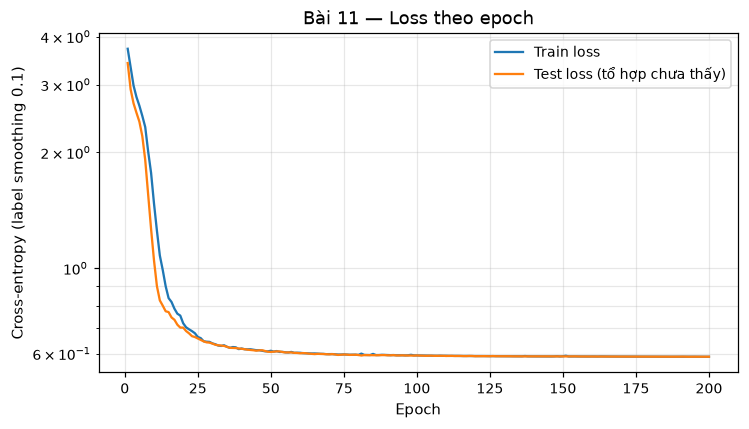

In [68]:
# ---- Biểu đồ Training Loss ----
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(range(1, EPOCHS + 1), train_losses, label="Train loss")
ax.plot(range(1, EPOCHS + 1), test_losses, label="Test loss (tổ hợp chưa thấy)")
ax.set_title("Bài 11 — Loss theo epoch")
ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy (label smoothing 0.1)")
ax.set_yscale("log"); ax.grid(alpha=0.3, which="both"); ax.legend()
plt.show()

**Giải thích biểu đồ loss.** Thông thường loss giảm mạnh ở giai đoạn đầu khi mô hình học ánh xạ từ ↔ từ, rồi tiến dần tới một **sàn dương** vì dùng *label smoothing* (nhãn đúng chỉ được gán xác suất ≈ 0.9, phần còn lại rải đều) — loss không thể về 0 ngay cả khi dự đoán hoàn hảo. Hãy so sánh hai đường: nếu đường test bám sát đường train thì mô hình đang **khái quát** sang các tổ hợp từ chưa gặp (dữ liệu có cấu trúc đơn giản nên điều này khả thi); nếu đường test tách xa và nằm trên đường train thì đó là dấu hiệu overfit. Hãy đối chiếu với độ chính xác khớp hoàn toàn ở cell kế tiếp.

In [69]:
# ============================================================
# BÀI 11 — Bước 7: Suy luận tự hồi quy (Greedy Decoding) và đánh giá
# ============================================================
@torch.no_grad()
def greedy_decode(model, src_tokens, max_len=8):
    """src_tokens: list token tiếng Việt. Sinh từng token một cho tới khi gặp <eos>."""
    model.eval()
    ids = [src_stoi.get(w, UNK) for w in src_tokens] + [EOS]
    src = torch.tensor([ids])                                   # (1, Ls)
    s_mask = make_pad_mask(src, PAD)
    memory = model.encode(src, s_mask)                          # Encoder chỉ chạy MỘT lần
    ys = torch.tensor([[SOS]])                                  # bắt đầu bằng <sos>
    for _ in range(max_len):
        t_mask = make_tgt_mask(ys, PAD)
        dec_out = model.decode(ys, memory, s_mask, t_mask)      # (1, t, d_model)
        probs = F.softmax(model.generator(dec_out[:, -1]), dim=-1)   # phân phối token KẾ TIẾP (vị trí cuối)
        next_id = int(probs.argmax(dim=-1))                     # greedy
        ys = torch.cat([ys, torch.tensor([[next_id]])], dim=1)  # nối vào chuỗi đã sinh
        if next_id == EOS:
            break
    return [tgt_itos[i] for i in ys[0, 1:].tolist() if i != EOS]

def exact_match(pair_list):
    ok = sum(greedy_decode(model, s) == t for s, t in pair_list)
    return ok / len(pair_list)

print(f"Độ chính xác khớp hoàn toàn — train: {exact_match(train_pairs):.1%} | test (tổ hợp chưa thấy): {exact_match(test_pairs):.1%}")

print("\nMột số ví dụ trên tập TEST:")
for s_toks, t_toks in test_pairs[:8]:
    pred = greedy_decode(model, s_toks)
    print(f"  {' '.join(s_toks):22s} → {' '.join(pred):22s} | đáp án: {' '.join(t_toks):22s} {'✔' if pred == t_toks else '✘'}")

print("\nThử câu mới (tự đặt, từ đều có trong vocab):")
for sent in ["chúng_ta ghét sách cũ", "bạn thích xe mới", "họ yêu chó trắng", "tôi ghét mèo"]:
    print(f"  {sent:24s} → {' '.join(greedy_decode(model, sent.split()))}")

print("\nThử từ NGOÀI vocab (→ <unk>), mô hình không thể dịch đúng phần này:")
print("  tôi yêu rồng →", " ".join(greedy_decode(model, "tôi yêu rồng".split())))

Độ chính xác khớp hoàn toàn — train: 100.0% | test (tổ hợp chưa thấy): 100.0%

Một số ví dụ trên tập TEST:
  tôi thích mèo cũ       → i like old cats        | đáp án: i like old cats        ✔
  tôi yêu chó đen        → i love black dogs      | đáp án: i love black dogs      ✔
  bạn thích sách mới     → you like new books     | đáp án: you like new books     ✔
  bạn ghét chó cũ        → you hate old dogs      | đáp án: you hate old dogs      ✔
  bạn ghét mèo cũ        → you hate old cats      | đáp án: you hate old cats      ✔
  họ ghét sách trắng     → they hate white books  | đáp án: they hate white books  ✔
  chúng_ta ghét sách mới → we hate new books      | đáp án: we hate new books      ✔
  bạn thích chó đen      → you like black dogs    | đáp án: you like black dogs    ✔

Thử câu mới (tự đặt, từ đều có trong vocab):
  chúng_ta ghét sách cũ    → we hate old books
  bạn thích xe mới         → you like new cars
  họ yêu chó trắng         → they love white dogs
  tôi ghét mèo         

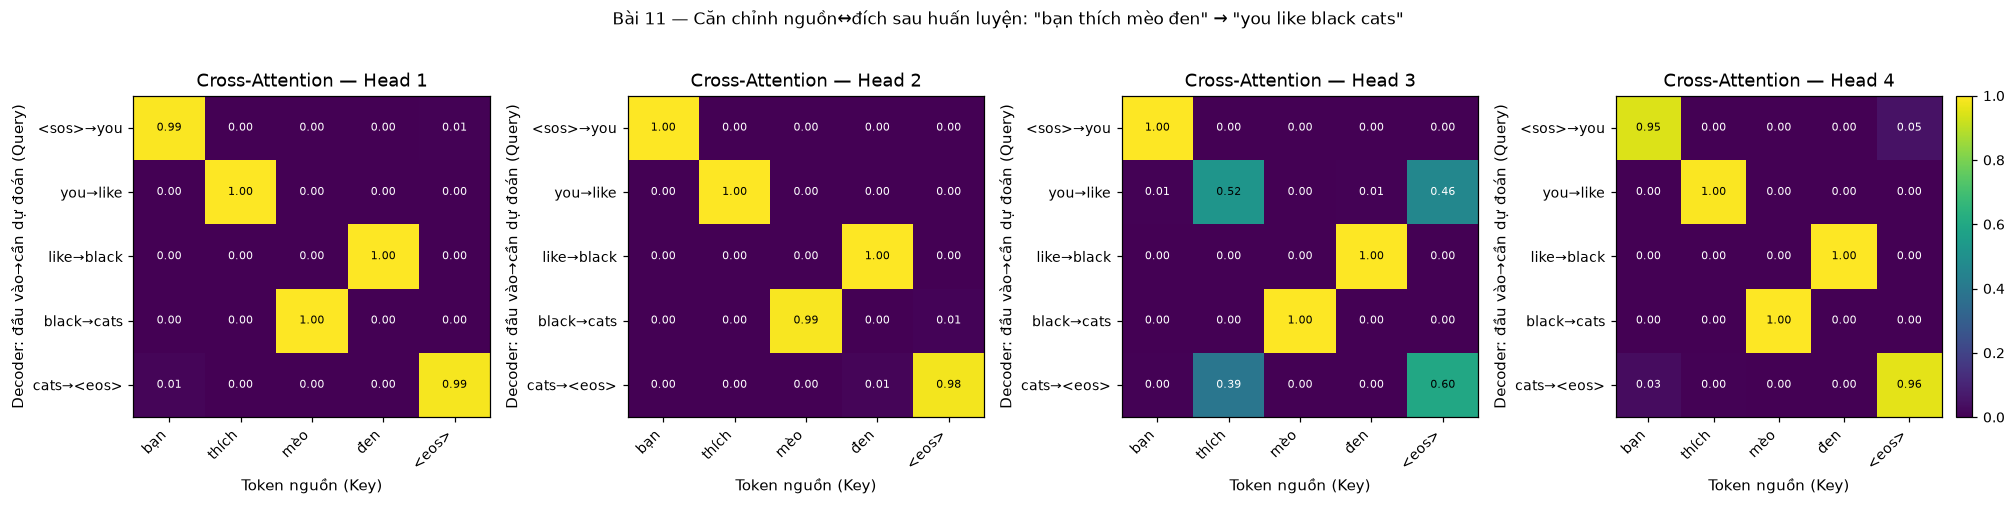

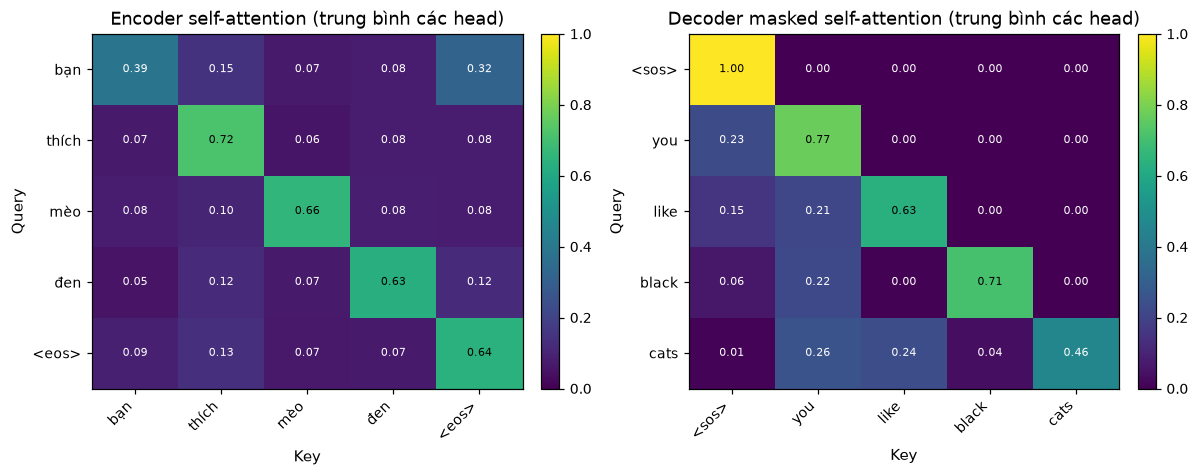

In [70]:
# ============================================================
# BÀI 11 — Trực quan hoá Cross-Attention sau huấn luyện + so sánh các Head
# ============================================================
sent = ["bạn", "thích", "mèo", "đen"]
gold = ["you", "like", "black", "cats"]
ids = [src_stoi[w] for w in sent] + [EOS]
src_t = torch.tensor([ids])
tin = torch.tensor([[SOS] + [tgt_stoi[w] for w in gold]])
model.eval()
with torch.no_grad():
    _ = model(src_t, tin, make_pad_mask(src_t, PAD), make_tgt_mask(tin, PAD))
ca = to_np(model.decoder.layers[-1].cross_attn.attn_weights[0])      # (h, Lt, Ls)
src_lab = sent + ["<eos>"]
dec_inputs = ["<sos>"] + gold                       # 5 token đưa vào Decoder (dịch phải)
row_lab = [f"{a}→{b}" for a, b in zip(dec_inputs, gold + ["<eos>"])]   # đầu vào → token cần dự đoán

fig, axes = plt.subplots(1, CFG["num_heads"], figsize=(4.6 * CFG["num_heads"], 4.4))
for h in range(CFG["num_heads"]):
    plot_heatmap(axes[h], ca[h], src_lab, row_lab, f"Cross-Attention — Head {h+1}", "Token nguồn (Key)", "Decoder: đầu vào→cần dự đoán (Query)",
                 vmin=0, vmax=1, annotate=True, fmt=".2f", colorbar=(h == CFG["num_heads"] - 1))
plt.suptitle('Bài 11 — Căn chỉnh nguồn↔đích sau huấn luyện: "bạn thích mèo đen" → "you like black cats"', y=1.03)
plt.tight_layout()
plt.show()

# ---- Masked self-attention của Decoder (lớp cuối) và self-attention của Encoder (lớp cuối) ----
sa_dec = to_np(model.decoder.layers[-1].self_attn.attn_weights[0])   # (h, Lt, Lt)
sa_enc = to_np(model.encoder.layers[-1].self_attn.attn_weights[0])   # (h, Ls, Ls)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
plot_heatmap(axes[0], sa_enc.mean(0), src_lab, src_lab, "Encoder self-attention (trung bình các head)", "Key", "Query", vmin=0, vmax=1)
plot_heatmap(axes[1], sa_dec.mean(0), dec_inputs, dec_inputs, "Decoder masked self-attention (trung bình các head)", "Key", "Query", vmin=0, vmax=1)
plt.tight_layout()
plt.show()

**Giải thích biểu đồ Bài 11**
- Mỗi **hàng** của cross-attention là một bước giải mã; với mô hình đã học tốt, hàng `<sos>→you` kỳ vọng tập trung vào `bạn`, hàng `you→like` vào `thích`... Điểm đáng chú ý là hai hàng kế cuối: Decoder sinh **`black` trước `cats`**, nên khi dự đoán `black` cần nhìn **`đen`** (từ nguồn đứng *sau* danh từ), còn khi dự đoán `cats` cần nhìn `mèo` — đây là **căn chỉnh đảo thứ tự**, thứ mà seq2seq RNN không có attention khó làm tốt. (Mức độ rõ nét của từng head có thể khác nhau giữa các lần chạy; một số head chuyên căn chỉnh, một số head ôm các token đặc biệt như `<eos>`.)
- Các head **không giống nhau**: đó chính là lợi ích của multi-head — mỗi head học một kiểu quan hệ khác.
- Decoder self-attention là **tam giác dưới** (mask nhân quả); Encoder self-attention là ma trận đầy đủ.

## Chương 3. Tổng kết và kiến thức mở rộng (Phần 5)

### 3.1. Tổng kết vai trò từng thành phần

| Thành phần | Vai trò cốt lõi | Nếu bỏ đi thì sao? |
|---|---|---|
| **Tokenization** | Đưa văn bản về ID rời rạc | Không có đầu vào số |
| **Embedding** ($\times\sqrt{d_{model}}$) | ID → vector học được | Không có biểu diễn ngữ nghĩa |
| **Positional Encoding** | Báo thứ tự/vị trí | Mô hình coi câu là "túi từ" |
| **Q, K, V** | Cơ chế "truy vấn–khoá–giá trị" cho attention | — |
| **Scaled Dot-Product Attention** | Trộn thông tin có trọng số giữa các vị trí | Không có tương tác giữa token |
| **Multi-Head Attention** | Nhiều kiểu quan hệ song song | Chỉ một kiểu chú ý, kém biểu diễn |
| **Masked Self-Attention** | Giữ tính tự hồi quy ở Decoder | Rò rỉ đáp án khi huấn luyện |
| **Encoder–Decoder Attention** | Căn chỉnh đích ↔ nguồn | Decoder không đọc được nguồn |
| **FFN** | Phi tuyến, xử lý từng token | Mô hình gần như chỉ tuyến tính |
| **Residual** | Đường đi gradient trực tiếp | Khó huấn luyện mạng sâu |
| **LayerNorm** | Ổn định thang đo kích hoạt | Huấn luyện mất ổn định |
| **Linear + Softmax** | Vector → phân phối trên từ vựng | Không ra được dự đoán token |

> **Kiến thức rút ra:**
>
> - PE → **thứ tự**; Attention → **tương tác giữa token**; MHA → **nhiều kiểu quan hệ**.
> - Mask → **không nhìn tương lai**; Cross-Attn → **đọc câu nguồn**; FFN → **phi tuyến**.
> - Residual → **gradient chảy tốt**; LayerNorm → **ổn định**; Linear + Softmax → **dự đoán token**.

### 3.2. Ưu điểm và hạn chế

**Ưu điểm**
- **Song song hoá** theo chiều thời gian khi huấn luyện → tận dụng GPU/TPU, mở rộng lên mô hình rất lớn.
- **Độ dài đường đi $O(1)$** giữa hai vị trí bất kỳ → dễ nắm bắt phụ thuộc xa.
- Kiến trúc **thống nhất, mô-đun**, dễ mở rộng sang nhiều miền (văn bản, ảnh, âm thanh, đồ thị...).
- Attention cho khả năng **diễn giải một phần** (xem ma trận chú ý).

**Hạn chế**
- **Chi phí $O(n^2)$** theo độ dài chuỗi (thời gian và bộ nhớ) → khó với chuỗi rất dài (đã có nhiều biến thể: Sparse/Longformer, Linformer, FlashAttention...).
- Cần **nhiều dữ liệu và tính toán**; ít *inductive bias* (không có sẵn tính cục bộ như CNN, tính thứ tự như RNN) nên với dữ liệu nhỏ dễ kém hơn.
- Phụ thuộc vào **Positional Encoding** để biết thứ tự; khả năng ngoại suy độ dài còn hạn chế ở một số cách mã hoá.
- Suy luận tự hồi quy **tuần tự từng token** (chậm khi sinh), cần KV-cache.

> **Kiến thức rút ra:**
>
> - **Ưu điểm:** Song song hoá, phụ thuộc xa $O(1)$, kiến trúc mô-đun, attention giúp diễn giải một phần.
> - **Hạn chế:** Chi phí $O(n^2)$, cần nhiều dữ liệu, phụ thuộc PE, suy luận vẫn tuần tự.

### 3.3. So sánh Transformer với RNN, LSTM, GRU

| Tiêu chí | RNN | LSTM / GRU | **Transformer** |
|---|---|---|---|
| Xử lý chuỗi | Tuần tự | Tuần tự | **Song song** toàn chuỗi |
| Đường đi giữa 2 vị trí cách $n$ | $O(n)$ | $O(n)$ (cổng giảm bớt mất mát) | $O(1)$ |
| Phụ thuộc xa | Rất khó (gradient triệt tiêu) | Tốt hơn RNN, vẫn hạn chế | **Tốt** |
| Chi phí mỗi layer | $O(n\cdot d^2)$ | $O(n\cdot d^2)$ (hằng số lớn hơn) | $O(n^2\cdot d)$ |
| Số bước tuần tự | $O(n)$ | $O(n)$ | $O(1)$ |
| Mã hoá vị trí | Ngầm (theo thứ tự xử lý) | Ngầm | Phải thêm (PE) |
| Bộ nhớ trạng thái | Vector ẩn cố định | Vector ẩn + cell | Toàn bộ chuỗi (KV) |

> **Kiến thức rút ra:**
>
> - RNN/LSTM/GRU: **tuần tự**, đường đi $O(n)$, chi phí $O(n d^2)$.
> - Transformer: **song song**, đường đi $O(1)$, chi phí $O(n^2 d)$, cần PE.
> - LSTM/GRU dùng cổng để giảm mất mát thông tin nhưng vẫn kém Transformer với phụ thuộc xa.

### 3.4. Khả năng xử lý song song
- RNN: $h_t$ cần $h_{t-1}$ ⇒ phải lặp **$n$ bước tuần tự**, mỗi bước là phép nhân nhỏ.
- Transformer: $QK^\top$, softmax và $AV$ là **các phép nhân ma trận lớn** tính cho mọi vị trí cùng lúc ⇒ số bước tuần tự trong một layer là $O(1)$.
- Khi huấn luyện, nhờ *teacher forcing* + mask nhân quả, **cả câu đích cũng được xử lý song song**. (Khi suy luận thì Decoder vẫn tuần tự.)

> **Kiến thức rút ra:**
>
> - RNN cần **$n$ bước tuần tự**; Transformer chỉ cần vài **phép nhân ma trận lớn** cho mọi vị trí cùng lúc.
> - Huấn luyện: cả câu đích chạy song song (teacher forcing + mask). Suy luận: Decoder vẫn tuần tự.

### 3.5. Độ phức tạp của Self-Attention (Bảng 1 trong bài báo)

| Loại layer | Độ phức tạp mỗi layer | Số phép toán tuần tự | Độ dài đường đi tối đa |
|---|---|---|---|
| **Self-Attention** | $O(n^2\cdot d)$ | $O(1)$ | $O(1)$ |
| Recurrent | $O(n\cdot d^2)$ | $O(n)$ | $O(n)$ |
| Convolutional (kernel $k$) | $O(k\cdot n\cdot d^2)$ | $O(1)$ | $O(\log_k n)$ |
| Self-Attention hạn chế (lân cận $r$) | $O(r\cdot n\cdot d)$ | $O(1)$ | $O(n/r)$ |

Giải thích $O(n^2\cdot d)$: $QK^\top$ nhân $(n\times d)$ với $(d\times n)$ tốn $n^2d$; $AV$ nhân $(n\times n)$ với $(n\times d)$ cũng $n^2d$. **Bộ nhớ** lưu ma trận attention là $O(n^2)$ cho mỗi head.  
Khi $n<d$ (câu thường ngắn hơn 512), Self-Attention **rẻ hơn** Recurrent; khi $n>d$ thì ngược lại → động lực cho các biến thể attention hiệu quả.

> **Kiến thức rút ra:**
>
> - Self-attention: $O(n^2 d)$ thời gian, $O(n^2)$ bộ nhớ, nhưng chỉ $O(1)$ bước tuần tự.
> - Rẻ hơn RNN khi $n < d$; đắt hơn khi chuỗi rất dài → động lực cho Longformer, Linformer, FlashAttention.

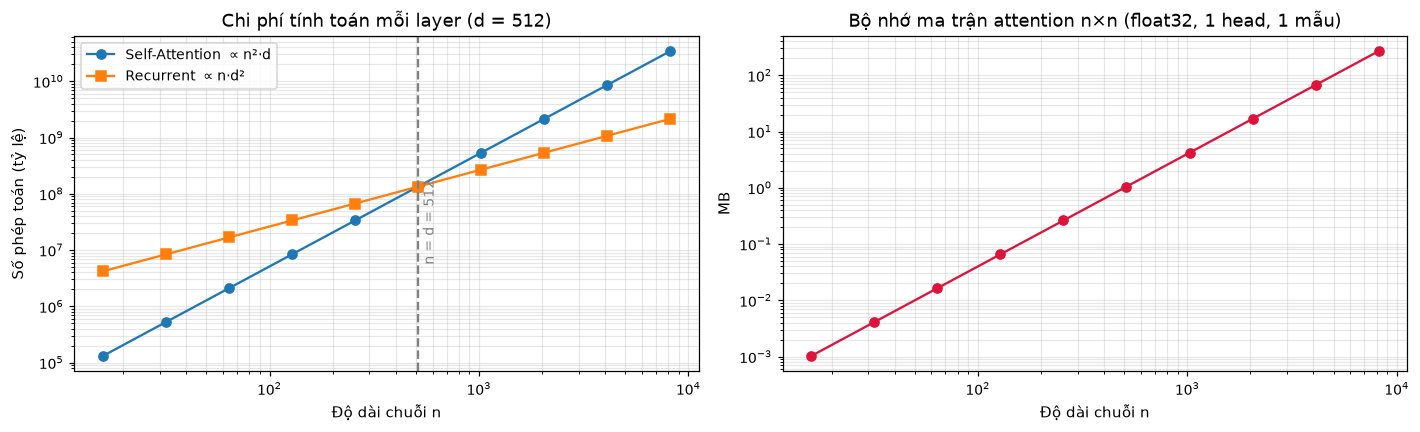

     n |   RNN (vòng lặp n bước) ms |    Attention (1 lượt) ms
    64 |                       0.36 |                     0.28
   256 |                       1.45 |                     1.09
  1024 |                       5.86 |                    21.80
(Thời gian phụ thuộc máy; điểm mấu chốt: RNN có n bước nối tiếp không thể song song hoá, attention là phép nhân ma trận.)


In [71]:
# ============================================================
# MINH HOẠ: độ phức tạp và tính song song
# ============================================================
d = 512
ns = np.array([2 ** k for k in range(4, 14)])             # n = 16 ... 8192
flops_attn = ns.astype(float) ** 2 * d                    # O(n² · d)
flops_rnn = ns.astype(float) * d ** 2                     # O(n · d²)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].loglog(ns, flops_attn, "o-", label="Self-Attention  ∝ n²·d")
axes[0].loglog(ns, flops_rnn, "s-", label="Recurrent  ∝ n·d²")
axes[0].axvline(d, ls="--", c="gray"); axes[0].text(d * 1.05, flops_rnn.min() * 1.5, "n = d = 512", rotation=90, color="gray")
axes[0].set_title("Chi phí tính toán mỗi layer (d = 512)")
axes[0].set_xlabel("Độ dài chuỗi n"); axes[0].set_ylabel("Số phép toán (tỷ lệ)")
axes[0].legend(); axes[0].grid(alpha=0.3, which="both")

# Bộ nhớ của ma trận attention (float32, 1 head, 1 mẫu)
mem_mb = ns.astype(float) ** 2 * 4 / 1e6
axes[1].loglog(ns, mem_mb, "o-", color="crimson")
axes[1].set_title("Bộ nhớ ma trận attention n×n (float32, 1 head, 1 mẫu)")
axes[1].set_xlabel("Độ dài chuỗi n"); axes[1].set_ylabel("MB")
axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

# ---- Minh hoạ tuần tự vs song song: số bước phụ thuộc nhau ----
def rnn_forward(x, Wx, Wh):                  # BẮT BUỘC lặp n bước (h_t phụ thuộc h_{t-1})
    h = torch.zeros(x.size(0), Wh.size(0))
    for t in range(x.size(1)):
        h = torch.tanh(x[:, t] @ Wx + h @ Wh)
    return h

def attention_forward(x):                    # MỘT lượt phép nhân ma trận cho mọi vị trí
    return F.softmax(x @ x.transpose(1, 2) / math.sqrt(x.size(-1)), dim=-1) @ x

def timeit(fn, reps=5):
    fn()
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps * 1000

print(f"{'n':>6s} | {'RNN (vòng lặp n bước) ms':>26s} | {'Attention (1 lượt) ms':>24s}")
Wx, Wh = torch.randn(64, 64) * 0.1, torch.randn(64, 64) * 0.1
with torch.no_grad():
    for n in [64, 256, 1024]:
        xx = torch.randn(8, n, 64)
        print(f"{n:6d} | {timeit(lambda: rnn_forward(xx, Wx, Wh)):26.2f} | {timeit(lambda: attention_forward(xx)):24.2f}")
print("(Thời gian phụ thuộc máy; điểm mấu chốt: RNN có n bước nối tiếp không thể song song hoá, attention là phép nhân ma trận.)")

### 3.6. Từ Transformer gốc đến BERT, GPT, Vision Transformer và Graph Transformer

| Mô hình (năm) | Phần của Transformer được dùng | Ý tưởng chính |
|---|---|---|
| **Transformer** (2017) | Encoder–Decoder | Chỉ dùng attention; dịch máy |
| **GPT** (2018) → GPT-2/3/4... | **Chỉ Decoder** (causal mask) | Mô hình ngôn ngữ tự hồi quy dự đoán token kế tiếp; huấn luyện trước quy mô lớn, *in-context learning* |
| **BERT** (2018) | **Chỉ Encoder** (hai chiều) | *Masked Language Modeling*: che ngẫu nhiên token rồi dự đoán; tinh chỉnh cho nhiều tác vụ hiểu ngôn ngữ |
| **T5 / BART** (2019) | Encoder–Decoder | Mọi tác vụ đưa về "text-to-text" |
| **Vision Transformer – ViT** (2020) | Encoder | Cắt ảnh thành **patch** (ví dụ $16\times16$), mỗi patch là một "token", thêm token `[CLS]` và mã hoá vị trí học được |
| **Swin, DETR** (2021) | Encoder / Enc–Dec | Attention theo cửa sổ dịch chuyển; phát hiện vật thể bằng truy vấn học được |
| **Graph Transformer** (Dwivedi & Bresson 2020; Graphormer 2021; GraphGPS 2022) | Encoder | Nút đồ thị là token; attention giới hạn trên lân cận hoặc toàn đồ thị; **mã hoá cấu trúc** (vector riêng của Laplacian, độ trung tâm, khoảng cách ngắn nhất, đặc trưng cạnh) thay cho Positional Encoding chuỗi |

Điểm chung: giữ **lõi attention + residual + LayerNorm + FFN**; khác nhau ở *đầu vào được "token hoá" thế nào*, *mã hoá vị trí/cấu trúc ra sao* và *dùng nửa nào của kiến trúc*.

> **Kiến thức rút ra:**
>
> - **GPT:** chỉ Decoder, dự đoán token kế tiếp. **BERT:** chỉ Encoder, che token rồi đoán (MLM).
> - **T5/BART:** Encoder–Decoder, mọi tác vụ quy về text-to-text.
> - **ViT:** ảnh → patch làm token. **Graph Transformer:** nút đồ thị làm token, mã hoá cấu trúc thay cho PE.
> - Lõi chung: attention + residual + LayerNorm + FFN.

### 3.7. Ứng dụng thực tế

| Lĩnh vực | Ứng dụng |
|---|---|
| **NLP** | Dịch máy, tóm tắt, hỏi–đáp, trợ lý hội thoại và LLM, tìm kiếm ngữ nghĩa, phân loại văn bản, sinh mã nguồn |
| **Computer Vision** | Phân loại ảnh (ViT), phát hiện vật thể (DETR), phân đoạn, mô hình đa phương thức ảnh–văn bản, sinh ảnh (kiến trúc diffusion dùng Transformer) |
| **Recommender Systems** | Mô hình hoá **chuỗi hành vi người dùng** (SASRec, BERT4Rec, Behavior Sequence Transformer): dự đoán mục kế tiếp người dùng sẽ tương tác |
| **Graph Neural Networks** | Dự đoán tính chất phân tử/thuốc, phân loại nút, dự đoán liên kết; Graphormer/GraphGPS bổ sung attention toàn cục để vượt giới hạn "lan truyền thông điệp cục bộ" của GNN |
| **Khoa học** | Gấp cuộn protein (AlphaFold 2 dùng attention), dự báo thời tiết, phân tích gen |

> **Kiến thức rút ra:**
>
> - NLP (dịch, LLM, hỏi–đáp), Vision (ViT, DETR), Recommender (SASRec, BERT4Rec), Graph (Graphormer), khoa học (AlphaFold).

### 3.8. Bài tập mở rộng (thực hành)

Phần này thực hiện cả **7 bài tập mở rộng** gợi ý ở cuối notebook mẫu. Mọi bài đều **dùng lại các class đã tự viết** ở Chương 2 (`Transformer`, `Encoder`, `MultiHeadAttention`, `SublayerConnection`, `PositionalEncoding`, `NoamScheduler`...) và bộ dữ liệu dịch máy mini của Bài 11.

| Bài | Nội dung | Câu hỏi cần trả lời |
|---|---|---|
| 1 | Đổi số head $h \in \{1,2,4,8\}$ | Nhiều head có giúp mô hình học tốt hơn không? Các head có khác nhau không? |
| 2 | Post-LN → Pre-LN | Kiểu nào ổn định hơn khi mạng sâu (`num_layers` lớn)? |
| 3 | PE sin/cos → embedding vị trí học được | Hai cách mã hoá vị trí khác nhau thế nào? |
| 4 | Thêm dữ liệu mới + dịch ngược Anh → Việt | Mô hình có học được chiều dịch ngược (đảo lại thứ tự tính từ) không? |
| 5 | Beam search | Beam search có tốt hơn greedy không, khi nào? |
| 6 | Weight tying | Dùng chung trọng số tiết kiệm bao nhiêu tham số, có ảnh hưởng chất lượng không? |
| 7 | Encoder kiểu BERT (phân loại) và Decoder kiểu GPT (mô hình ngôn ngữ) | Tách riêng một nửa Transformer thì dùng được vào việc gì? |

Để chạy nhanh trên CPU, mỗi mô hình chỉ huấn luyện **100 epoch** (Bài 11 dùng 200).

In [72]:
# ============================================================
# 3.8 — Hàm dùng chung cho 7 bài tập mở rộng
# ============================================================
def make_dataset(pair_list_all, test_ratio=0.2, seed=SEED):
    """Từ danh sách cặp (câu nguồn, câu đích): chia train/test, tạo vocab, tạo tensor đã padding."""
    perm_ = np.random.RandomState(seed).permutation(len(pair_list_all))
    n_te = int(test_ratio * len(pair_list_all))
    te = [pair_list_all[i] for i in perm_[:n_te]]
    tr = [pair_list_all[i] for i in perm_[n_te:]]
    s_stoi, s_itos = make_vocab([p[0] for p in pair_list_all])
    t_stoi, t_itos = make_vocab([p[1] for p in pair_list_all])
    ms = max(len(p[0]) for p in pair_list_all) + 1
    mt = max(len(p[1]) for p in pair_list_all) + 1
    def to_tensors(pl):
        S  = [[s_stoi[w] for w in s] + [EOS] for s, _ in pl]
        TI = [[SOS] + [t_stoi[w] for w in t] for _, t in pl]          # decoder input  (dịch phải)
        TO = [[t_stoi[w] for w in t] + [EOS] for _, t in pl]          # nhãn           (dịch trái)
        return pad_sequences(S, PAD, ms), pad_sequences(TI, PAD, mt), pad_sequences(TO, PAD, mt)
    return dict(train=tr, test=te, s_stoi=s_stoi, s_itos=s_itos, t_stoi=t_stoi, t_itos=t_itos,
                tr_t=to_tensors(tr), te_t=to_tensors(te))

def build_model(ds, d_model=64, num_heads=4, d_ff=128, num_layers=2, dropout=0.1, seed=SEED):
    """Cấu hình mặc định giống Bài 11."""
    torch.manual_seed(seed)
    return Transformer(len(ds["s_itos"]), len(ds["t_itos"]), d_model, num_heads, d_ff,
                       num_layers, dropout, max_len=32, pad_idx=PAD)

def seq2seq_loss(m, src, tin, tout, crit):
    logits = m(src, tin, make_pad_mask(src, PAD), make_tgt_mask(tin, PAD))
    return crit(logits.reshape(-1, logits.size(-1)), tout.reshape(-1))

def train(m, ds, epochs=100, batch=32, schedule="noam", lr=1e-3, seed=SEED):
    """Vòng lặp huấn luyện giống Bài 11. schedule='noam' (warmup) hoặc 'const' (lr cố định, không warmup)."""
    torch.manual_seed(seed)
    crit = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)
    opt = torch.optim.Adam(m.parameters(), lr=lr, betas=(0.9, 0.98), eps=1e-9)
    sch = NoamScheduler(opt, m.src_embed.d_model, warmup=100, factor=0.15) if schedule == "noam" else None
    S, TI, TO = ds["tr_t"]
    tr_l, te_l, t0 = [], [], time.time()
    for _ in range(epochs):
        m.train()
        order, run, nb_ = torch.randperm(S.size(0)), 0.0, 0
        for i in range(0, S.size(0), batch):
            idx = order[i:i + batch]
            loss = seq2seq_loss(m, S[idx], TI[idx], TO[idx], crit)
            opt.zero_grad(); loss.backward()
            if sch: sch.step()
            opt.step()
            run += loss.item(); nb_ += 1
        tr_l.append(run / nb_)
        m.eval()
        with torch.no_grad():
            te_l.append(seq2seq_loss(m, *ds["te_t"], crit).item())
    return tr_l, te_l, time.time() - t0

@torch.no_grad()
def greedy(m, ds, src_tokens, max_len=8):
    """Greedy decoding (giống Bài 11 nhưng nhận model + dataset làm tham số)."""
    m.eval()
    src = torch.tensor([[ds["s_stoi"].get(w, UNK) for w in src_tokens] + [EOS]])
    s_mask = make_pad_mask(src, PAD)
    memory = m.encode(src, s_mask)
    ys = torch.tensor([[SOS]])
    for _ in range(max_len):
        out = m.decode(ys, memory, s_mask, make_tgt_mask(ys, PAD))
        nxt = int(m.generator(out[:, -1]).argmax(-1))
        ys = torch.cat([ys, torch.tensor([[nxt]])], dim=1)
        if nxt == EOS:
            break
    return [ds["t_itos"][i] for i in ys[0, 1:].tolist() if i != EOS]

def accuracy(m, ds, split="test", decode_fn=greedy):
    """Tỷ lệ câu dịch KHỚP HOÀN TOÀN với đáp án."""
    return sum(decode_fn(m, ds, s) == t for s, t in ds[split]) / len(ds[split])

@torch.no_grad()
def cross_attention(m, ds, src_tokens, tgt_tokens):
    """Trọng số cross-attention ở Decoder block cuối: (h, L_tgt, L_src)."""
    m.eval()
    src = torch.tensor([[ds["s_stoi"][w] for w in src_tokens] + [EOS]])
    tin = torch.tensor([[SOS] + [ds["t_stoi"][w] for w in tgt_tokens]])
    m(src, tin, make_pad_mask(src, PAD), make_tgt_mask(tin, PAD))
    return to_np(m.decoder.layers[-1].cross_attn.attn_weights[0])

EPOCHS_X = 100
ds_vi_en = make_dataset(pairs)           # đúng dữ liệu và cách chia của Bài 11
print(f"Việt → Anh: {len(ds_vi_en['train'])} cặp train | {len(ds_vi_en['test'])} cặp test | "
      f"|V_src|={len(ds_vi_en['s_itos'])}, |V_tgt|={len(ds_vi_en['t_itos'])}")

Việt → Anh: 192 cặp train | 48 cặp test | |V_src|=19, |V_tgt|=19


#### Bài tập 1. Thay đổi số head: $h \in \{1, 2, 4, 8\}$

- Giữ nguyên $d_{model}=64$, chỉ đổi $h$ → $d_k = 64/h$ lần lượt là 64, 32, 16, 8.
- So sánh: số tham số, test loss, độ chính xác khớp hoàn toàn trên tập test, và ma trận cross-attention của từng head.

h=1 | d_k=64 | tham số=171,091 | test loss=0.597 | test exact-match=100.0% | hội tụ (test loss < 0.65) ở epoch 24 | 5.4s
h=2 | d_k=32 | tham số=171,091 | test loss=0.593 | test exact-match=100.0% | hội tụ (test loss < 0.65) ở epoch 23 | 5.8s
h=4 | d_k=16 | tham số=171,091 | test loss=0.594 | test exact-match=100.0% | hội tụ (test loss < 0.65) ở epoch 27 | 6.4s
h=8 | d_k= 8 | tham số=171,091 | test loss=0.592 | test exact-match=100.0% | hội tụ (test loss < 0.65) ở epoch 28 | 5.2s


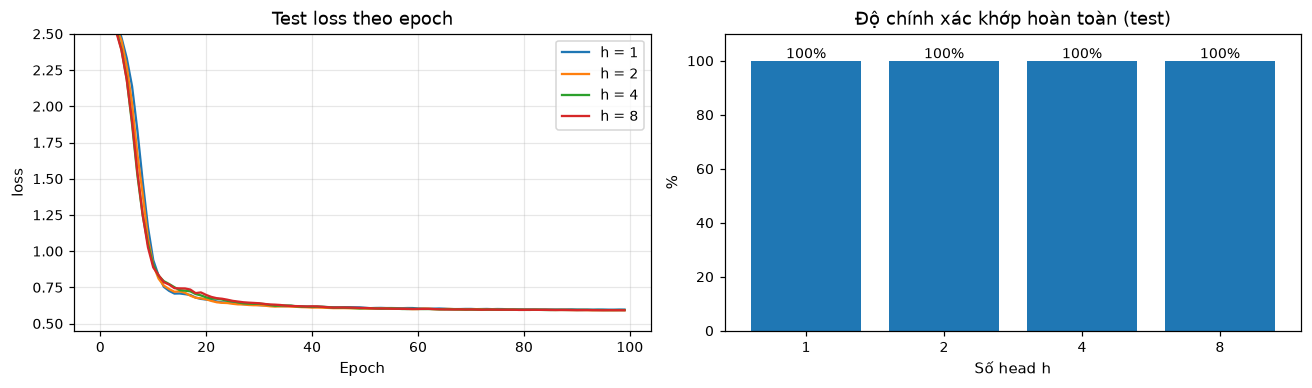

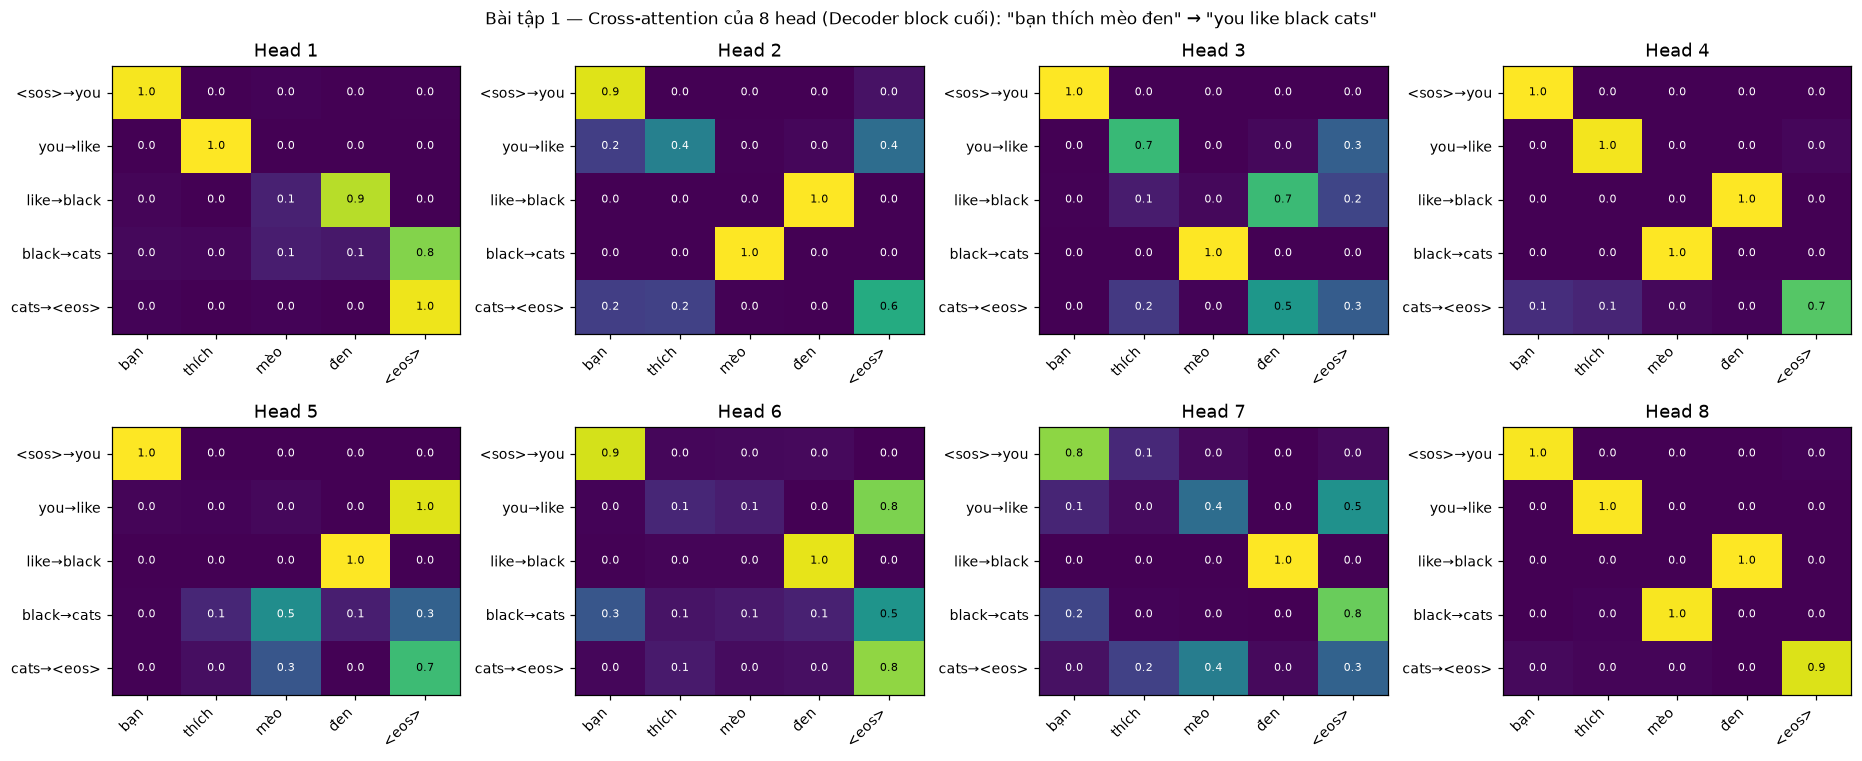

In [73]:
# ============================================================
# BÀI TẬP 1 — So sánh số head
# ============================================================
res_heads = {}
for h in [1, 2, 4, 8]:
    m = build_model(ds_vi_en, num_heads=h)
    tr_l, te_l, sec = train(m, ds_vi_en, EPOCHS_X)
    res_heads[h] = dict(model=m, tr=tr_l, te=te_l, sec=sec, acc=accuracy(m, ds_vi_en))
    conv = next((i + 1 for i, v in enumerate(te_l) if v < 0.65), None)   # loss sàn ≈ 0.59 do label smoothing
    print(f"h={h} | d_k={64 // h:2d} | tham số={count_params(m):,} | test loss={te_l[-1]:.3f} | "
          f"test exact-match={res_heads[h]['acc']:.1%} | hội tụ (test loss < 0.65) ở epoch {conv} | {sec:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for h, r in res_heads.items():
    axes[0].plot(r["te"], label=f"h = {h}")
axes[0].set_title("Test loss theo epoch"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("loss")
axes[0].set_ylim(top=2.5); axes[0].legend(); axes[0].grid(alpha=0.3)
hs = list(res_heads)
axes[1].bar([str(h) for h in hs], [res_heads[h]["acc"] * 100 for h in hs], color="tab:blue")
for i, h in enumerate(hs):
    axes[1].text(i, res_heads[h]["acc"] * 100 + 1, f"{res_heads[h]['acc']:.0%}", ha="center")
axes[1].set_ylim(0, 110); axes[1].set_title("Độ chính xác khớp hoàn toàn (test)")
axes[1].set_xlabel("Số head h"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

# ---- Cross-attention của từng head (mô hình h = 8) ----
sent, gold = ["bạn", "thích", "mèo", "đen"], ["you", "like", "black", "cats"]
ca8 = cross_attention(res_heads[8]["model"], ds_vi_en, sent, gold)
rows = [f"{a}→{b}" for a, b in zip(["<sos>"] + gold, gold + ["<eos>"])]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for k, ax in enumerate(axes.flat):
    plot_heatmap(ax, ca8[k], sent + ["<eos>"], rows, f"Head {k + 1}", "", "", vmin=0, vmax=1,
                 annotate=True, fmt=".1f", colorbar=False)
plt.suptitle('Bài tập 1 — Cross-attention của 8 head (Decoder block cuối): "bạn thích mèo đen" → "you like black cats"')
plt.tight_layout(); plt.show()

**Kết quả và nhận xét:**
- Cả 4 cấu hình có **cùng số tham số (171.091)** và đều đạt **100%** trên tập test; tốc độ hội tụ gần như nhau (epoch 23–28). Bài toán quá đơn giản nên số head không tạo khác biệt về độ chính xác.
- Khác biệt nằm ở **cách các head chia việc** (hình 8 head):
  - Head 1, 4, 8: căn chỉnh gần như hoàn hảo *you↔bạn, like↔thích, black↔đen, cats↔mèo* (đảo thứ tự tính từ–danh từ).
  - Head 2, 5, 6, 7: nhiều hàng dồn vào `<eos>`, đóng vai trò "chỗ trống" khi head không cần lấy thêm thông tin.
- → Các head **tự chuyên môn hoá** khác nhau dù dùng chung đầu vào.

> **Kiến thức rút ra:**
>
> - Đổi $h$ **không làm đổi số tham số** (vì $d_k = d_{model}/h$); chỉ đổi cách chia không gian biểu diễn thành các phần nhỏ.
> - Nhiều head = nhiều "góc nhìn" song song, mỗi head có thể chuyên một kiểu quan hệ (căn chỉnh từ, nhìn `<eos>`, nhìn từ bên cạnh...).
> - $h$ quá lớn thì mỗi head chỉ còn $d_k$ rất nhỏ → mỗi head yếu đi. Bài báo chọn $h=8$, $d_k=64$ làm điểm cân bằng.

#### Bài tập 2. Post-LN → Pre-LN

| | Công thức | Ghi chú |
|---|---|---|
| **Post-LN** (bài báo, Bài 7) | $\mathrm{LN}(x + \mathrm{Sublayer}(x))$ | LayerNorm nằm **trên** đường residual |
| **Pre-LN** (GPT-2, LLaMA...) | $x + \mathrm{Sublayer}(\mathrm{LN}(x))$ | đường residual **thông suốt**; cần thêm 1 LayerNorm ở cuối mỗi chồng block |

Thí nghiệm: tăng `num_layers` lên 2, 6, 12 và huấn luyện với **learning rate cố định $10^{-3}$, không warmup** (điều kiện khó) để thấy rõ khác biệt về độ ổn định.

N= 2 | Post-LN | train loss cuối=0.594 | test loss=0.592 | test exact-match=100.0% | 6.6s
N= 2 | Pre-LN  | train loss cuối=0.591 | test loss=0.589 | test exact-match=100.0% | 6.4s
N= 6 | Post-LN | train loss cuối=0.651 | test loss=0.637 | test exact-match=93.8% | 17.9s
N= 6 | Pre-LN  | train loss cuối=0.589 | test loss=0.588 | test exact-match=100.0% | 17.9s
N=12 | Post-LN | train loss cuối=1.694 | test loss=4.527 | test exact-match=0.0% | 35.7s
N=12 | Pre-LN  | train loss cuối=0.589 | test loss=0.588 | test exact-match=100.0% | 35.7s


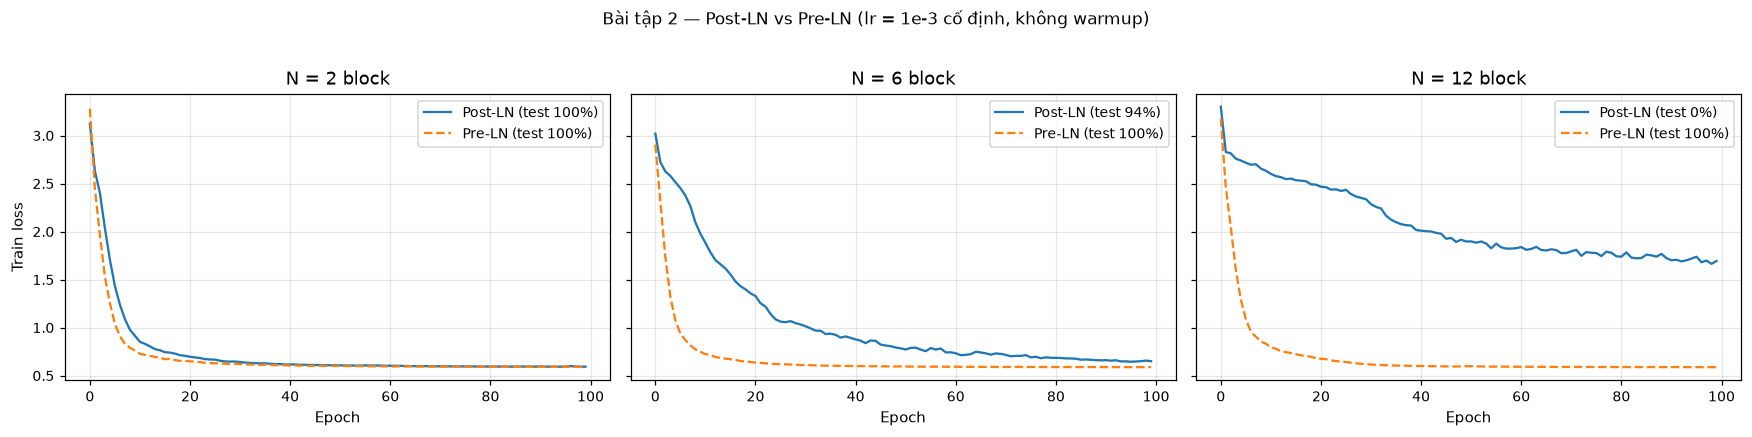

In [74]:
# ============================================================
# BÀI TẬP 2 — Pre-LN và so sánh độ ổn định khi mạng sâu
# ============================================================
class PreLNSublayerConnection(nn.Module):
    """Pre-LN:  x + Dropout( Sublayer( LayerNorm(x) ) )"""
    def __init__(self, d_model, dropout=0.1):
        super().__init__()
        self.norm = LayerNormScratch(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, sublayer):
        return x + self.dropout(sublayer(self.norm(x)))      # chuẩn hoá TRƯỚC, residual giữ nguyên x

class WithFinalNorm(nn.Module):
    """Pre-LN: đầu ra chồng block chưa được chuẩn hoá → thêm 1 LayerNorm ở cuối."""
    def __init__(self, stack, d_model):
        super().__init__()
        self.stack, self.norm = stack, LayerNormScratch(d_model)
        self.layers = stack.layers                           # để code vẽ attention vẫn truy cập được

    def forward(self, *args):
        return self.norm(self.stack(*args))

def to_pre_ln(m, dropout=0.1):
    d = m.src_embed.d_model
    for layer in list(m.encoder.layers) + list(m.decoder.layers):
        layer.sublayers = nn.ModuleList([PreLNSublayerConnection(d, dropout) for _ in layer.sublayers])
    m.encoder, m.decoder = WithFinalNorm(m.encoder, d), WithFinalNorm(m.decoder, d)
    return m

res_ln = {}
for n_layers in [2, 6, 12]:
    for kind in ["Post-LN", "Pre-LN"]:
        m = build_model(ds_vi_en, num_layers=n_layers)
        if kind == "Pre-LN":
            m = to_pre_ln(m)
        tr_l, te_l, sec = train(m, ds_vi_en, EPOCHS_X, schedule="const", lr=1e-3)
        res_ln[(n_layers, kind)] = dict(tr=tr_l, te=te_l, acc=accuracy(m, ds_vi_en))
        print(f"N={n_layers:2d} | {kind:7s} | train loss cuối={tr_l[-1]:.3f} | test loss={te_l[-1]:.3f} | "
              f"test exact-match={res_ln[(n_layers, kind)]['acc']:.1%} | {sec:.1f}s")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, n_layers in zip(axes, [2, 6, 12]):
    for kind, st in [("Post-LN", "-"), ("Pre-LN", "--")]:
        ax.plot(res_ln[(n_layers, kind)]["tr"], st, label=f"{kind} (test {res_ln[(n_layers, kind)]['acc']:.0%})")
    ax.set_title(f"N = {n_layers} block"); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("Train loss")
plt.suptitle("Bài tập 2 — Post-LN vs Pre-LN (lr = 1e-3 cố định, không warmup)", y=1.03)
plt.tight_layout(); plt.show()

**Kết quả và nhận xét:**

| Số block N | Post-LN (test) | Pre-LN (test) |
|---|---|---|
| 2 | 100% | 100% |
| 6 | 93,8% | 100% |
| 12 | **0%** (loss kẹt ở ~1,7) | **100%** |

- Mạng nông (N=2): hai kiểu như nhau.
- Mạng càng sâu, Post-LN càng khó học khi **không có warmup**: N=6 hội tụ chậm hơn hẳn, N=12 gần như không học được.
- Pre-LN hội tụ nhanh và gần như giống nhau ở mọi độ sâu.

> **Kiến thức rút ra:**
>
> - Chỉ đổi **vị trí của LayerNorm** cũng ảnh hưởng lớn đến việc huấn luyện.
> - **Pre-LN** giữ đường residual "sạch" ($x$ đi thẳng qua mọi block) → gradient ổn định, ít phụ thuộc warmup, phù hợp mạng rất sâu.
> - **Post-LN** (bản gốc) cần warmup cẩn thận khi mạng sâu.

#### Bài tập 3. Positional Encoding sin/cos → embedding vị trí học được

- **Sin/cos (bài báo):** công thức cố định, không có tham số.
- **Học được (BERT, GPT-2):** một bảng `nn.Embedding(max_len, d_model)`, mỗi vị trí có một vector được học như embedding của từ.

Thay `model.pos_enc` bằng phiên bản học được, giữ nguyên mọi thứ khác.

sin/cos (cố định)  | tham số=171,091 | test loss=0.594 | test exact-match=100.0%
học được           | tham số=173,139 | test loss=0.593 | test exact-match=100.0%


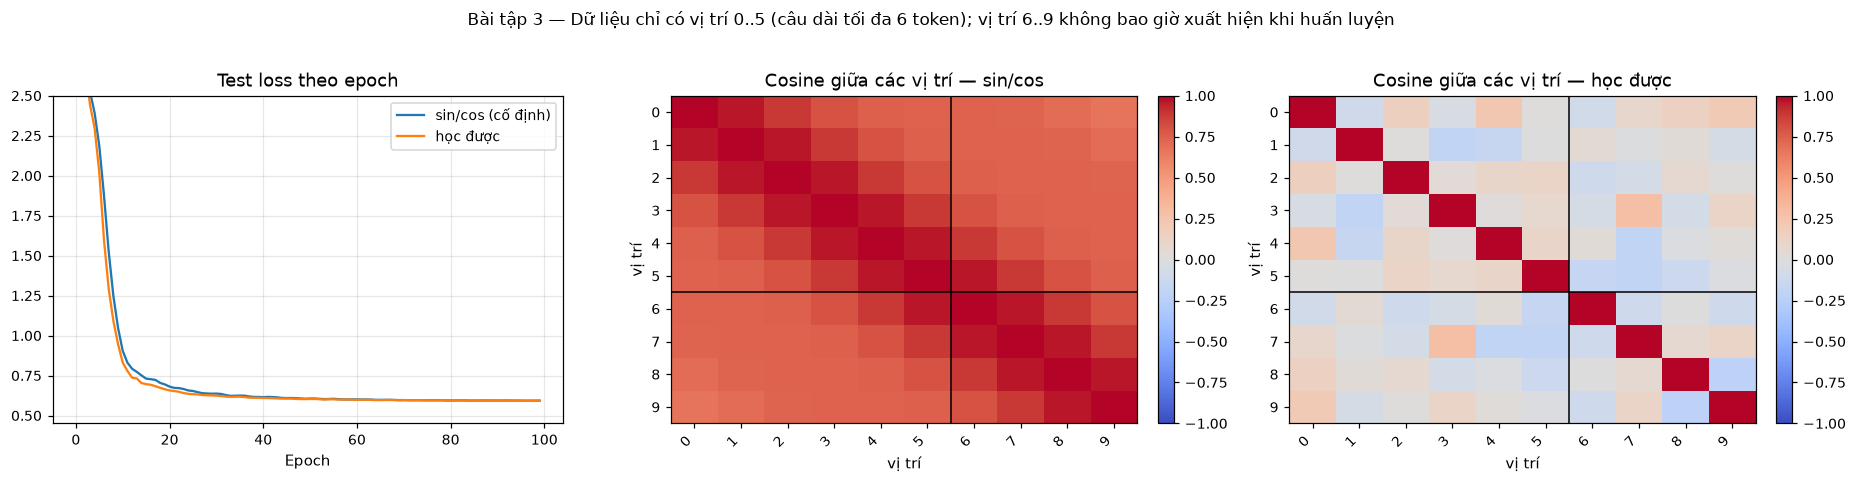

In [75]:
# ============================================================
# BÀI TẬP 3 — Embedding vị trí học được
# ============================================================
class LearnedPositionalEncoding(nn.Module):
    """Cùng giao diện với PositionalEncoding nhưng vector vị trí là THAM SỐ HỌC ĐƯỢC."""
    def __init__(self, d_model, dropout=0.1, max_len=512):
        super().__init__()
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):                                    # x: (B, L, d_model)
        pos = torch.arange(x.size(1), device=x.device)       # 0, 1, ..., L-1
        return self.dropout(x + self.pos_emb(pos).unsqueeze(0))

res_pe = {"sin/cos (cố định)": res_heads[4]}                 # mô hình h=4 ở Bài tập 1 = cấu hình gốc
m_lpe = build_model(ds_vi_en)
m_lpe.pos_enc = LearnedPositionalEncoding(64, dropout=0.1, max_len=32)
tr_l, te_l, sec = train(m_lpe, ds_vi_en, EPOCHS_X)
res_pe["học được"] = dict(model=m_lpe, tr=tr_l, te=te_l, acc=accuracy(m_lpe, ds_vi_en))

for name, r in res_pe.items():
    print(f"{name:18s} | tham số={count_params(r['model']):,} | test loss={r['te'][-1]:.3f} | test exact-match={r['acc']:.1%}")

# ---- So sánh độ tương đồng cosine giữa các vector vị trí 0..9 ----
def cos_sim(P):
    P = F.normalize(P, dim=-1)
    return to_np(P @ P.T)

sin_pe = res_heads[4]["model"].pos_enc.pe[0, :10]
learn_pe = m_lpe.pos_enc.pos_emb.weight[:10].detach()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for name, r in res_pe.items():
    axes[0].plot(r["te"], label=name)
axes[0].set_title("Test loss theo epoch"); axes[0].set_xlabel("Epoch"); axes[0].set_ylim(top=2.5)
axes[0].legend(); axes[0].grid(alpha=0.3)
plot_heatmap(axes[1], cos_sim(sin_pe), range(10), range(10), "Cosine giữa các vị trí — sin/cos", "vị trí", "vị trí",
             vmin=-1, vmax=1, annotate=False, cmap="coolwarm")
plot_heatmap(axes[2], cos_sim(learn_pe), range(10), range(10), "Cosine giữa các vị trí — học được", "vị trí", "vị trí",
             vmin=-1, vmax=1, annotate=False, cmap="coolwarm")
for ax in axes[1:]:
    ax.axhline(5.5, c="k", lw=1); ax.axvline(5.5, c="k", lw=1)
plt.suptitle("Bài tập 3 — Dữ liệu chỉ có vị trí 0..5 (câu dài tối đa 6 token); vị trí 6..9 không bao giờ xuất hiện khi huấn luyện", y=1.03)
plt.tight_layout(); plt.show()

**Kết quả và nhận xét:**
- Chất lượng gần như **giống hệt** (test 100%, loss 0,594 vs 0,593). Embedding học được tốn thêm $32 \times 64 = 2.048$ tham số.
- **Sin/cos:** vị trí gần nhau thì vector gần nhau (đường chéo đậm, nhạt dần), và cấu trúc này kéo dài sang cả vị trí 6–9 chưa từng gặp.
- **Học được:** mô hình chỉ học cách **phân biệt** các vị trí (gần như trực giao với nhau), không học khái niệm "gần/xa". Vị trí 6–9 không có trong dữ liệu nên vẫn là vector ngẫu nhiên lúc khởi tạo.

> **Kiến thức rút ra:**
>
> - Hai cách đều cho mô hình biết thứ tự từ; trên câu ngắn, chất lượng gần như nhau (bài báo cũng ghi nhận điều này).
> - **Sin/cos:** không tốn tham số, có cấu trúc sẵn (vị trí gần nhau thì vector gần nhau), dùng được cho câu dài hơn lúc train.
> - **Học được:** linh hoạt hơn nhưng tốn tham số và **chỉ học được những vị trí đã thấy**; vị trí chưa gặp vẫn là vector ngẫu nhiên → không ngoại suy được sang câu dài hơn.

#### Bài tập 4. Thêm dữ liệu mới và dịch ngược Anh → Việt

- Thêm 2 danh từ (`nhà` → *houses*, `hoa` → *flowers*) và 2 tính từ (`đẹp` → *beautiful*, `lớn` → *big*): từ 240 lên **504 cặp câu**.
- Huấn luyện 2 mô hình: Việt → Anh và **Anh → Việt**. Chiều ngược phải học đảo *"black cats"* → *"mèo đen"* (tính từ chuyển ra **sau** danh từ).

Dữ liệu mở rộng: 504 cặp (404 train / 100 test)
Việt → Anh | test loss=0.613 | train exact-match=100.0% | test exact-match=100.0% | 13.7s
Anh → Việt | test loss=0.613 | train exact-match=100.0% | test exact-match=100.0% | 13.3s

Ví dụ dịch Anh → Việt (câu trong tập TEST, có từ mới):
  you like beautiful cats      → bạn thích mèo đẹp    | đáp án: bạn thích mèo đẹp    ✔
  we hate big cars             → chúng_ta ghét xe lớn | đáp án: chúng_ta ghét xe lớn ✔
  i like white houses          → tôi thích nhà trắng  | đáp án: tôi thích nhà trắng  ✔
  i like big houses            → tôi thích nhà lớn    | đáp án: tôi thích nhà lớn    ✔
  we hate big dogs             → chúng_ta ghét chó lớn | đáp án: chúng_ta ghét chó lớn ✔
  we hate black flowers        → chúng_ta ghét hoa đen | đáp án: chúng_ta ghét hoa đen ✔


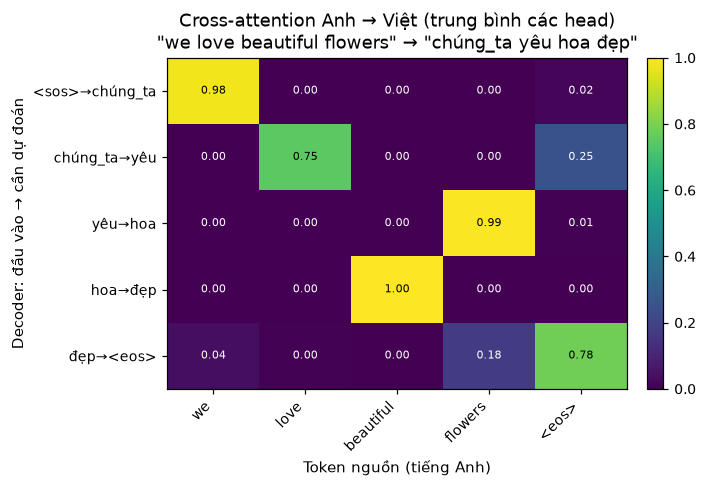

In [76]:
# ============================================================
# BÀI TẬP 4 — Thêm dữ liệu + dịch ngược Anh → Việt
# ============================================================
NOUN2 = {**NOUN, "nhà": "houses", "hoa": "flowers"}
ADJ2  = {**ADJ, "đẹp": "beautiful", "lớn": "big"}

pairs2 = []
for s, v, n in itertools.product(SUBJ, VERB, NOUN2):
    pairs2.append(([s, v, n], [SUBJ[s], VERB[v], NOUN2[n]]))
    for a in ADJ2:
        pairs2.append(([s, v, n, a], [SUBJ[s], VERB[v], ADJ2[a], NOUN2[n]]))

ds_vi_en2 = make_dataset(pairs2)                              # Việt → Anh (dữ liệu mở rộng)
ds_en_vi  = make_dataset([(t, s) for s, t in pairs2])         # Anh → Việt (đảo chiều cặp câu)
print(f"Dữ liệu mở rộng: {len(pairs2)} cặp ({len(ds_vi_en2['train'])} train / {len(ds_vi_en2['test'])} test)")

models4 = {}
for name, ds in [("Việt → Anh", ds_vi_en2), ("Anh → Việt", ds_en_vi)]:
    m = build_model(ds)
    tr_l, te_l, sec = train(m, ds, EPOCHS_X)
    models4[name] = m
    print(f"{name} | test loss={te_l[-1]:.3f} | train exact-match={accuracy(m, ds, 'train'):.1%} | "
          f"test exact-match={accuracy(m, ds):.1%} | {sec:.1f}s")

print("\nVí dụ dịch Anh → Việt (câu trong tập TEST, có từ mới):")
shown = 0
for s, t in ds_en_vi["test"]:
    if any(w in s for w in ["houses", "flowers", "beautiful", "big"]) and shown < 6:
        pred = greedy(models4["Anh → Việt"], ds_en_vi, s)
        print(f"  {' '.join(s):28s} → {' '.join(pred):20s} | đáp án: {' '.join(t):20s} {'✔' if pred == t else '✘'}")
        shown += 1

# ---- Cross-attention Anh → Việt: kiểm tra căn chỉnh đảo thứ tự ----
src_en, tgt_vi = ["we", "love", "beautiful", "flowers"], ["chúng_ta", "yêu", "hoa", "đẹp"]
ca = cross_attention(models4["Anh → Việt"], ds_en_vi, src_en, tgt_vi).mean(0)
rows = [f"{a}→{b}" for a, b in zip(["<sos>"] + tgt_vi, tgt_vi + ["<eos>"])]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
plot_heatmap(ax, ca, src_en + ["<eos>"], rows, 'Cross-attention Anh → Việt (trung bình các head)\n"we love beautiful flowers" → "chúng_ta yêu hoa đẹp"',
             "Token nguồn (tiếng Anh)", "Decoder: đầu vào → cần dự đoán", vmin=0, vmax=1)
plt.tight_layout(); plt.show()

**Kết quả và nhận xét:**
- Cả hai chiều đều đạt **100%** trên 100 câu test, kể cả câu chứa từ mới (*houses, flowers, beautiful, big*).
- Heatmap Anh → Việt cho thấy căn chỉnh **chéo**: khi sinh `hoa` mô hình nhìn `flowers` (0,99), khi sinh `đẹp` nhìn `beautiful` (1,00). Thứ tự nguồn A–N được đảo thành N–A ở đích.

> **Kiến thức rút ra:**
>
> - Cùng một kiến trúc, chỉ đổi dữ liệu là dịch được chiều ngược lại: Transformer **không gắn với ngôn ngữ hay chiều dịch** nào.
> - Việc đảo thứ tự tính từ–danh từ được giải quyết bởi **cross-attention**: khi sinh mỗi từ, Decoder tự chọn nhìn vào đúng từ nguồn, không cần nguồn và đích cùng thứ tự.
> - Thêm từ mới thì vocab tăng và cần thêm dữ liệu chứa các từ đó; từ không có trong vocab vẫn thành `<unk>`.

#### Bài tập 5. Beam search thay cho greedy decoding

- **Greedy:** mỗi bước chọn 1 token có xác suất cao nhất → nhanh nhưng có thể "đi nhầm đường" từ sớm.
- **Beam search (k):** mỗi bước giữ $k$ chuỗi có tổng log-xác suất cao nhất, cuối cùng chọn chuỗi tốt nhất (có chuẩn hoá theo độ dài để không thiên vị câu ngắn).
- So sánh trên 2 mô hình: mô hình **huấn luyện đầy đủ** (100 epoch) và mô hình **huấn luyện ít** (6 epoch, còn chưa chắc chắn).
- Ngoài độ chính xác, đo thêm **xác suất của cả câu** $P(y \mid x)$ theo mô hình — đây chính là đại lượng beam search cố gắng tối đa hoá.

In [77]:
# ============================================================
# BÀI TẬP 5 — Beam search
# ============================================================
@torch.no_grad()
def beam_search(m, ds, src_tokens, beam=3, max_len=8, alpha=0.6, return_all=False):
    m.eval()
    src = torch.tensor([[ds["s_stoi"].get(w, UNK) for w in src_tokens] + [EOS]])
    s_mask = make_pad_mask(src, PAD)
    memory = m.encode(src, s_mask)                                # Encoder chỉ chạy 1 lần
    beams, finished = [([SOS], 0.0)], []                          # (chuỗi token, tổng log-prob)
    for _ in range(max_len):
        cand = []
        for toks, lp in beams:
            ys = torch.tensor([toks])
            out = m.decode(ys, memory, s_mask, make_tgt_mask(ys, PAD))
            logp = F.log_softmax(m.generator(out[:, -1]), dim=-1)[0]
            top = logp.topk(beam)
            cand += [(toks + [i], lp + v) for v, i in zip(top.values.tolist(), top.indices.tolist())]
        cand.sort(key=lambda c: c[1], reverse=True)
        beams = []
        for toks, lp in cand:                                     # giữ k chuỗi tốt nhất chưa kết thúc
            (finished if toks[-1] == EOS else beams).append((toks, lp))
            if len(beams) == beam:
                break
        # Dừng khi chuỗi đã xong tốt nhất >= mọi chuỗi đang dở (log-prob chỉ có thể giảm thêm)
        if not beams or (finished and max(lp for _, lp in finished) >= beams[0][1]):
            break
    finished = finished or beams
    score = lambda toks, lp: lp / (((5 + len(toks) - 1) / 6) ** alpha)   # chuẩn hoá độ dài (Wu et al., 2016)
    finished.sort(key=lambda c: score(*c), reverse=True)
    words = lambda toks: [ds["t_itos"][i] for i in toks[1:] if i != EOS]
    if return_all:
        return [(words(t), math.exp(lp)) for t, lp in finished]
    return words(finished[0][0])

@torch.no_grad()
def sentence_logprob(m, ds, src_tokens, tgt_tokens):
    """log P(câu đích + <eos> | câu nguồn) theo mô hình."""
    m.eval()
    src = torch.tensor([[ds["s_stoi"].get(w, UNK) for w in src_tokens] + [EOS]])
    ids = [ds["t_stoi"][w] for w in tgt_tokens]
    tin, tout = torch.tensor([[SOS] + ids]), torch.tensor([ids + [EOS]])
    logp = F.log_softmax(m(src, tin, make_pad_mask(src, PAD), make_tgt_mask(tin, PAD)), dim=-1)
    return logp.gather(-1, tout.unsqueeze(-1)).sum().item()

m_weak = build_model(ds_vi_en2)
train(m_weak, ds_vi_en2, epochs=6)                                # cố tình huấn luyện ít
m_full = models4["Việt → Anh"]                                    # mô hình đầy đủ ở Bài tập 4

beam_fn = lambda k: (lambda mm, d, s: beam_search(mm, d, s, beam=k))
print(f"{'Mô hình':26s} | {'greedy':>8s} | {'beam k=1':>8s} | {'beam k=3':>8s} | {'beam k=5':>8s} | log P trung bình (greedy → beam 5)")
for name, m in [("Huấn luyện ít (6 epoch)", m_weak), ("Huấn luyện đủ (100 epoch)", m_full)]:
    accs = [accuracy(m, ds_vi_en2)] + [accuracy(m, ds_vi_en2, decode_fn=beam_fn(k)) for k in [1, 3, 5]]
    lp_g = np.mean([sentence_logprob(m, ds_vi_en2, s, greedy(m, ds_vi_en2, s)) for s, _ in ds_vi_en2["test"]])
    lp_b = np.mean([sentence_logprob(m, ds_vi_en2, s, beam_search(m, ds_vi_en2, s, beam=5)) for s, _ in ds_vi_en2["test"]])
    print(f"{name:26s} | " + " | ".join(f"{a:8.1%}" for a in accs) + f" | {lp_g:.3f} → {lp_b:.3f}")

# ---- Những câu mà greedy và beam search cho kết quả KHÁC nhau (mô hình huấn luyện ít) ----
print("\nCác câu greedy ≠ beam k=5 (mô hình huấn luyện ít):")
diff = [(s, t) for s, t in ds_vi_en2["test"] if greedy(m_weak, ds_vi_en2, s) != beam_search(m_weak, ds_vi_en2, s, beam=5)]
for s, t in diff[:5]:
    g, b = greedy(m_weak, ds_vi_en2, s), beam_search(m_weak, ds_vi_en2, s, beam=5)
    pg, pb = math.exp(sentence_logprob(m_weak, ds_vi_en2, s, g)), math.exp(sentence_logprob(m_weak, ds_vi_en2, s, b))
    print(f"  {' '.join(s):22s} | greedy: {' '.join(g):24s} P={pg:.3f} {'✔' if g == t else '✘'} "
          f"| beam: {' '.join(b):24s} P={pb:.3f} {'✔' if b == t else '✘'}")
print(f"  ... tổng cộng {len(diff)}/{len(ds_vi_en2['test'])} câu khác nhau")

Mô hình                    |   greedy | beam k=1 | beam k=3 | beam k=5 | log P trung bình (greedy → beam 5)
Huấn luyện ít (6 epoch)    |    78.0% |    78.0% |    75.0% |    76.0% | -2.004 → -1.888
Huấn luyện đủ (100 epoch)  |   100.0% |   100.0% |   100.0% |   100.0% | -0.398 → -0.398

Các câu greedy ≠ beam k=5 (mô hình huấn luyện ít):
  tôi thích nhà trắng    | greedy: i like white houses      P=0.050 ✔ | beam: i like houses            P=0.098 ✘
  tôi yêu chó trắng      | greedy: i love white dogs        P=0.147 ✔ | beam: i love dogs              P=0.163 ✘
  tôi ghét hoa đẹp       | greedy: i hate beautiful flowers P=0.124 ✔ | beam: i hate flowers           P=0.140 ✘
  họ yêu xe đẹp          | greedy: they love they love beautiful cars P=0.020 ✘ | beam: they love beautiful cars P=0.119 ✔
  tôi yêu nhà trắng      | greedy: i love old houses        P=0.077 ✘ | beam: i love houses            P=0.102 ✘
  ... tổng cộng 17/100 câu khác nhau


**Kết quả và nhận xét:**
- Mô hình huấn luyện đủ: greedy và beam đều **100%**, xác suất câu như nhau → mô hình đã chắc chắn thì beam search không có tác dụng.
- Mô hình huấn luyện ít: beam search làm **tăng xác suất câu** (log P trung bình −2,004 → −1,888), đúng nhiệm vụ của nó, nhưng độ chính xác **không tăng** (78% → 75–76%).
- Nguyên nhân thấy rõ ở các ví dụ: mô hình yếu gán xác suất cao cho câu **ngắn hơn** (*i like houses*, thiếu tính từ), nên beam search chọn câu đó. Beam chỉ thắng khi greedy bị lặp từ (*they love they love...*).
- Đây là điểm yếu đã biết của beam search: nó tối ưu theo mô hình, nên **mô hình sai thì beam cũng sai**.

> **Kiến thức rút ra:**
>
> - Greedy chọn tốt nhất **từng bước**; beam search tìm chuỗi tốt nhất **cả câu** (gần đúng), đổi lại tốn khoảng $k$ lần tính toán.
> - Beam search tìm được câu có **xác suất cao hơn theo mô hình**, nhưng "xác suất cao hơn" chỉ có nghĩa là "đúng hơn" khi mô hình đã tốt. Mô hình yếu thì beam search có thể còn tệ hơn greedy.
> - Khi mô hình đã rất tự tin, greedy và beam cho cùng kết quả → bài toán đơn giản dùng greedy là đủ; beam search có ích với bài toán khó (câu dài, nhiều cách dịch).
> - Beam $k=1$ chính là greedy; cần **chuẩn hoá theo độ dài** vì cộng log-prob luôn âm nên chuỗi ngắn sẽ được lợi.

#### Bài tập 6. Weight tying (dùng chung trọng số Embedding đích và Linear cuối)

- Embedding đích: $E \in \mathbb{R}^{|V|\times d}$ (token → vector). Linear cuối: $W \in \mathbb{R}^{|V|\times d}$ (vector → điểm số từng token). Hai ma trận **cùng kích thước**.
- Weight tying: đặt $W = E$ → một ma trận làm cả hai việc (bài báo dùng chung cả 3 ma trận vì vocab Anh–Đức chung).

Không tie  | tham số=171,863 | test loss=0.613 | test exact-match=100.0%
Có tie     | tham số=170,391 | test loss=0.615 | test exact-match=100.0%

Linear cuối và Embedding đích là cùng một tensor ? True
Tiết kiệm: 1,472 tham số = |V_tgt| × d_model = 23 × 64
Với bài báo (vocab chung ~37.000, d_model=512): mỗi ma trận 18,944,000 tham số; dùng chung 3 ma trận tiết kiệm ~38 triệu tham số.


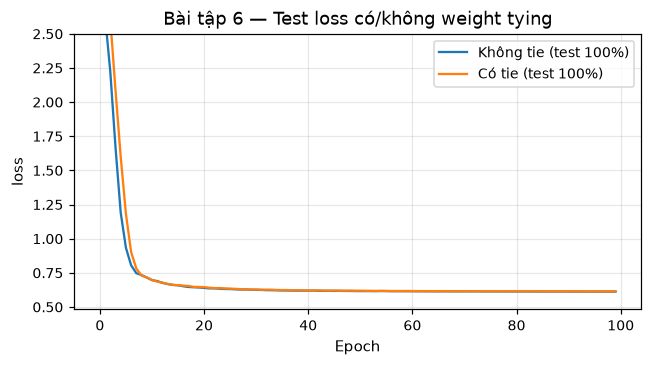

In [78]:
# ============================================================
# BÀI TẬP 6 — Weight tying
# ============================================================
def tie_weights(m):
    m.generator.weight = m.tgt_embed.lut.weight              # CÙNG một tensor tham số
    return m

res_tie = {}
for name, tie in [("Không tie", False), ("Có tie", True)]:
    m = build_model(ds_vi_en2)
    if tie:
        m = tie_weights(m)
    tr_l, te_l, sec = train(m, ds_vi_en2, EPOCHS_X)
    res_tie[name] = dict(model=m, te=te_l, acc=accuracy(m, ds_vi_en2), params=count_params(m))
    print(f"{name:10s} | tham số={res_tie[name]['params']:,} | test loss={te_l[-1]:.3f} | test exact-match={res_tie[name]['acc']:.1%}")

m_t = res_tie["Có tie"]["model"]
print("\nLinear cuối và Embedding đích là cùng một tensor ?", m_t.generator.weight is m_t.tgt_embed.lut.weight)
saved = res_tie["Không tie"]["params"] - res_tie["Có tie"]["params"]
print(f"Tiết kiệm: {saved:,} tham số = |V_tgt| × d_model = {len(ds_vi_en2['t_itos'])} × 64")
print(f"Với bài báo (vocab chung ~37.000, d_model=512): mỗi ma trận {37000 * 512:,} tham số; "
      f"dùng chung 3 ma trận tiết kiệm ~{2 * 37000 * 512 / 1e6:.0f} triệu tham số.")

fig, ax = plt.subplots(figsize=(6, 3.4))
for name, r in res_tie.items():
    ax.plot(r["te"], label=f"{name} (test {r['acc']:.0%})")
ax.set_title("Bài tập 6 — Test loss có/không weight tying"); ax.set_xlabel("Epoch"); ax.set_ylabel("loss")
ax.set_ylim(top=2.5); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Kết quả và nhận xét:**
- Kiểm tra `generator.weight is tgt_embed.lut.weight` → `True`: đúng là một tensor dùng ở hai chỗ.
- Tiết kiệm **1.472 tham số** (23 × 64), chất lượng không đổi (test 100%, loss 0,613 vs 0,615); bản có tie hội tụ chậm hơn một chút ở vài epoch đầu.
- Ở quy mô bài báo, khoản tiết kiệm lên tới khoảng **38 triệu tham số**.

> **Kiến thức rút ra:**
>
> - Embedding (token → vector) và Linear cuối (vector → token) là hai chiều của **cùng một ánh xạ**, nên dùng chung một ma trận là hợp lý.
> - Lợi ích chính là **giảm tham số**: với vocab nhỏ không đáng kể, nhưng với vocab lớn (hàng chục nghìn token) tiết kiệm hàng chục triệu tham số.
> - Đây là lý do bài báo nhân embedding với $\sqrt{d_{model}}$: cùng một ma trận được dùng ở hai chỗ với thang đo khác nhau.

#### Bài tập 7. Tách riêng một nửa Transformer: Encoder kiểu BERT và Decoder kiểu GPT

**7a. Encoder-only (kiểu BERT) — phân loại câu.**
- Bài toán: phân loại **cảm xúc** câu tiếng Việt: động từ *yêu / thích* → **tích cực**, *ghét* → **tiêu cực**.
- Thêm token đặc biệt `[CLS]` vào đầu câu → `Encoder` (attention hai chiều) → lấy vector của `[CLS]` → `Linear` → 2 lớp.

**7b. Decoder-only (kiểu GPT) — mô hình ngôn ngữ.**
- Bỏ Encoder và cross-attention. Một block GPT = self-attention **có causal mask** + FFN, nên dùng lại đúng class `Encoder`, chỉ đổi mask.
- Học trên các câu tiếng Anh, rồi cho mô hình **tự sinh câu** từ một đoạn mở đầu.

Phân loại cảm xúc — test accuracy: 100.0%  (100 câu test)


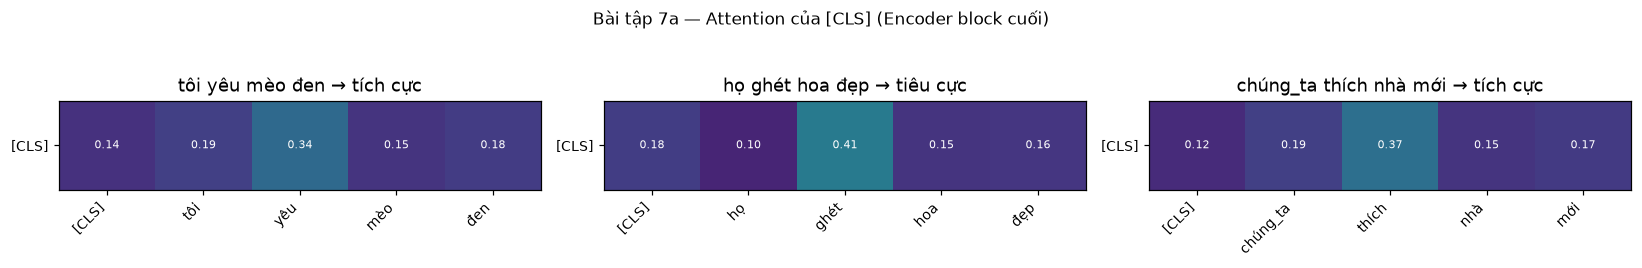

In [79]:
# ============================================================
# BÀI TẬP 7a — Encoder-only (kiểu BERT): phân loại cảm xúc
# ============================================================
class EncoderClassifier(nn.Module):
    def __init__(self, vocab, n_classes, d_model=64, num_heads=4, d_ff=128, num_layers=2, dropout=0.1):
        super().__init__()
        self.embed = Embeddings(vocab, d_model, PAD)
        self.cls = nn.Parameter(torch.randn(1, 1, d_model))          # vector [CLS] học được
        self.pos_enc = PositionalEncoding(d_model, dropout, max_len=32)
        self.encoder = Encoder(num_layers, d_model, num_heads, d_ff, dropout)   # dùng lại class Encoder
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, ids):                                          # ids: (B, L)
        x = torch.cat([self.cls.expand(ids.size(0), -1, -1), self.embed(ids)], dim=1)     # (B, 1+L, d)
        mask = torch.cat([torch.ones(ids.size(0), 1, 1, 1, dtype=torch.bool), make_pad_mask(ids, PAD)], dim=-1)
        h = self.encoder(self.pos_enc(x), mask)                      # hai chiều: chỉ mask padding
        return self.head(h[:, 0])                                    # chỉ dùng vector [CLS]

LABELS = ["tiêu cực", "tích cực"]
def sentiment(src_tokens):
    return 0 if src_tokens[1] == "ghét" else 1

def cls_tensors(pl):
    ids = pad_sequences([[ds_vi_en2["s_stoi"][w] for w in s] for s, _ in pl], PAD)
    return ids, torch.tensor([sentiment(s) for s, _ in pl])

Xtr, ytr = cls_tensors(ds_vi_en2["train"])
Xte, yte = cls_tensors(ds_vi_en2["test"])
torch.manual_seed(SEED)
clf = EncoderClassifier(len(ds_vi_en2["s_itos"]), 2)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
for ep in range(30):
    clf.train()
    order = torch.randperm(len(Xtr))
    for i in range(0, len(Xtr), 32):
        idx = order[i:i + 32]
        loss = F.cross_entropy(clf(Xtr[idx]), ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
clf.eval()
with torch.no_grad():
    acc_te = (clf(Xte).argmax(-1) == yte).float().mean().item()
print(f"Phân loại cảm xúc — test accuracy: {acc_te:.1%}  ({len(Xte)} câu test)")

# ---- [CLS] đã "nhìn" vào từ nào để quyết định? ----
examples = [["tôi", "yêu", "mèo", "đen"], ["họ", "ghét", "hoa", "đẹp"], ["chúng_ta", "thích", "nhà", "mới"]]
fig, axes = plt.subplots(1, 3, figsize=(15, 2.2))
for ax, s in zip(axes, examples):
    ids = torch.tensor([[ds_vi_en2["s_stoi"][w] for w in s]])
    with torch.no_grad():
        pred = clf(ids).argmax(-1).item()
    w = clf.encoder.layers[-1].self_attn.attn_weights[0].mean(0)[0:1]     # hàng [CLS], trung bình các head
    plot_heatmap(ax, w, ["[CLS]"] + s, ["[CLS]"], f"{' '.join(s)} → {LABELS[pred]}", "", "",
                 vmin=0, vmax=1, colorbar=False)
plt.suptitle("Bài tập 7a — Attention của [CLS] (Encoder block cuối)", y=1.08)
plt.tight_layout(); plt.show()

In [80]:
# ============================================================
# BÀI TẬP 7b — Decoder-only (kiểu GPT): mô hình ngôn ngữ tiếng Anh
# ============================================================
class DecoderOnlyLM(nn.Module):
    """Không có Encoder, không có cross-attention. Block = self-attention CÓ causal mask + FFN."""
    def __init__(self, vocab, d_model=64, num_heads=4, d_ff=128, num_layers=2, dropout=0.1):
        super().__init__()
        self.embed = Embeddings(vocab, d_model, PAD)
        self.pos_enc = PositionalEncoding(d_model, dropout, max_len=32)
        self.blocks = Encoder(num_layers, d_model, num_heads, d_ff, dropout)   # dùng lại Encoder + causal mask
        self.lm_head = nn.Linear(d_model, vocab)

    def forward(self, ids):                                              # ids: (B, L)
        h = self.blocks(self.pos_enc(self.embed(ids)), make_tgt_mask(ids, PAD))   # mask: padding AND nhân quả
        return self.lm_head(h)                                           # (B, L, |V|): dự đoán token KẾ TIẾP

t_stoi2, t_itos2 = ds_vi_en2["t_stoi"], ds_vi_en2["t_itos"]
_, LM_in_tr, LM_out_tr = ds_vi_en2["tr_t"]          # <sos> y1..yn  →  y1..yn <eos>
_, LM_in_te, LM_out_te = ds_vi_en2["te_t"]

torch.manual_seed(SEED)
lm = DecoderOnlyLM(len(t_itos2))
opt = torch.optim.Adam(lm.parameters(), lr=1e-3)
lm_loss = lambda inp, out: F.cross_entropy(lm(inp).reshape(-1, len(t_itos2)), out.reshape(-1), ignore_index=PAD)
for ep in range(60):
    lm.train()
    order = torch.randperm(len(LM_in_tr))
    for i in range(0, len(order), 32):
        idx = order[i:i + 32]
        loss = lm_loss(LM_in_tr[idx], LM_out_tr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
lm.eval()
with torch.no_grad():
    te_loss = lm_loss(LM_in_te, LM_out_te).item()
print(f"Mô hình ngôn ngữ — test loss = {te_loss:.3f} | perplexity = {math.exp(te_loss):.2f} "
      f"(đoán ngẫu nhiên: {len(t_itos2)})")

@torch.no_grad()
def generate(prompt, max_new=6, temperature=1.0, gen=None):
    ids = [SOS] + [t_stoi2[w] for w in prompt.split()]
    for _ in range(max_new):
        probs = F.softmax(lm(torch.tensor([ids]))[0, -1] / temperature, dim=-1)
        nxt = int(torch.multinomial(probs, 1, generator=gen))
        if nxt == EOS:
            break
        ids.append(nxt)
    return ids[1:]

def is_grammatical(ids):
    """Đúng mẫu: Chủ ngữ – Động từ – [Tính từ] – Danh từ ?"""
    w = [t_itos2[i] for i in ids]
    S_, V_, A_, N_ = set(SUBJ.values()), set(VERB.values()), set(ADJ2.values()), set(NOUN2.values())
    return (len(w) == 3 and w[0] in S_ and w[1] in V_ and w[2] in N_) or \
           (len(w) == 4 and w[0] in S_ and w[1] in V_ and w[2] in A_ and w[3] in N_)

g = torch.Generator().manual_seed(SEED)
print("\nSinh câu từ đoạn mở đầu (lấy mẫu ngẫu nhiên):")
for p in ["i", "they hate", "we love big", "you"]:
    print(f"  '{p}' → " + " | ".join(" ".join(t_itos2[i] for i in generate(p, gen=g)) for _ in range(3)))

train_sents = {tuple(t) for _, t in ds_vi_en2["train"]}
samples = [generate("", gen=g) for _ in range(300)]
ok = [s for s in samples if is_grammatical(s)]
new = [s for s in ok if tuple(t_itos2[i] for i in s) not in train_sents]
print(f"\n300 câu sinh tự do: {len(ok) / 300:.0%} đúng ngữ pháp mẫu (S–V–[A]–N); "
      f"trong đó {len(new) / max(len(ok), 1):.0%} là câu KHÔNG có trong tập train.")

Mô hình ngôn ngữ — test loss = 1.349 | perplexity = 3.85 (đoán ngẫu nhiên: 23)

Sinh câu từ đoạn mở đầu (lấy mẫu ngẫu nhiên):
  'i' → i love old dogs | i like black cars | i like beautiful dogs
  'they hate' → they hate white flowers | they hate books | they hate big houses
  'we love big' → we love big houses | we love big flowers | we love big cats
  'you' → you love white dogs | you love old flowers | you hate new dogs

300 câu sinh tự do: 98% đúng ngữ pháp mẫu (S–V–[A]–N); trong đó 16% là câu KHÔNG có trong tập train.


**Kết quả và nhận xét:**
- **7a (BERT):** phân loại đúng **100%** câu test. Hàng attention của `[CLS]` dồn nhiều nhất vào **động từ** (*yêu* 0,34, *ghét* 0,41, *thích* 0,37) — đúng từ quyết định cảm xúc. Mô hình tự tìm ra từ quan trọng.
- **7b (GPT):** perplexity **3,85** (đoán ngẫu nhiên là 23). Câu sinh ra đúng ngữ pháp mẫu S–V–[A]–N tới **98%**, và tính từ luôn đứng **trước** danh từ như tiếng Anh.
- **16%** câu đúng ngữ pháp là câu **không có trong tập train** → mô hình học được **cấu trúc câu**.

> **Kiến thức rút ra:**
>
> - **Encoder-only (BERT):** attention hai chiều, đọc cả câu rồi tóm vào vector `[CLS]` → hợp với bài toán **hiểu** (phân loại, gán nhãn, tìm kiếm).
> - **Decoder-only (GPT):** chỉ cần self-attention + **causal mask**, học dự đoán token kế tiếp → hợp với bài toán **sinh** văn bản.
> - Khác biệt cốt lõi giữa hai loại block chỉ nằm ở **mask**: cùng một class `Encoder`, đổi mask là đổi từ "BERT" sang "GPT".

#### Kết luận bài tập mở rộng

| Bài | Kết quả chính |
|---|---|
| 1. Số head 1/2/4/8 | Số tham số như nhau, đều đạt 100%. Biểu đồ 8 head cho thấy các head chia việc: một số head căn chỉnh từ, một số dồn vào `<eos>`. |
| 2. Post-LN → Pre-LN | Với 12 block và không warmup: **Post-LN 0%, Pre-LN 100%**.|
| 3. PE học được | Chất lượng như nhau. Sin/cos có cấu trúc gần/xa giữa các vị trí; bản học được thì không, và các vị trí chưa gặp vẫn là vector ngẫu nhiên. |
| 4. Thêm dữ liệu + Anh → Việt | 504 cặp câu, cả hai chiều dịch đều đạt 100%. Heatmap cho thấy căn chỉnh đảo thứ tự *beautiful flowers → hoa đẹp*. |
| 5. Beam search | Mô hình tốt: greedy và beam như nhau. Mô hình yếu: beam tăng xác suất câu nhưng **không tăng độ chính xác**, vì hay chọn câu ngắn thiếu tính từ. |
| 6. Weight tying | Tiết kiệm 1.472 tham số mà chất lượng không đổi. Ở quy mô bài báo, mức tiết kiệm khoảng 38 triệu tham số. |
| 7. BERT / GPT | 7a: phân loại đúng 100%, token `[CLS]` tự chú ý nhiều nhất vào động từ. 7b: 98% câu sinh ra đúng ngữ pháp, trong đó 16% là câu mới không có trong tập train. |

#### Tài liệu tham khảo
- Vaswani, A. et al. (2017). *Attention Is All You Need.* NeurIPS. arXiv:1706.03762  
- Devlin, J. et al. (2018). *BERT.* arXiv:1810.04805 · Radford, A. et al. (2018). *Improving Language Understanding by Generative Pre-Training.*  
- Dosovitskiy, A. et al. (2020). *An Image is Worth 16x16 Words (ViT).* arXiv:2010.11929  
- Dwivedi, V. P., Bresson, X. (2020). *A Generalization of Transformer Networks to Graphs.* arXiv:2012.09699 · Ying, C. et al. (2021). *Graphormer.* arXiv:2106.05234  
- Ba, J. L. et al. (2016). *Layer Normalization.* arXiv:1607.06450 · He, K. et al. (2016). *Deep Residual Learning.*